# Juice+: Finding the Extra Gear in the "Underwear Olympics"

Scouts say a player has **juice** when he has an extra gear the players around him don't. It's the receiver who runs past a corner who had him covered, or the safety who closes on a ball that looked out of reach. It's the movement that **pops off the screen**.

The Combine is often mocked as the **"Underwear Olympics"**. Prospects run and jump in shorts, with no pads and no opponent, so many evaluators doubt the drills say much about football. We agree they don't tell you who can *play*. We ask a narrower question a front office can act on:

> **If a team wants to add juice to its roster, does the way a prospect moves in Combine drills show up in how he moves in NFL games? And what can tracking see that a stopwatch can't?**

**Juice+** answers with one number, built from the Combine's 10 Hz tracking and rebuilt the same way from NFL game tracking.

**Key findings (270 rookies with both scores, 2023 to 2025 draft classes):**
- **Combine juice shows up on Sundays.** Players at 110+ became elite movers in games **33%** of the time. Under 90, only **1 of 39** did.
- **For speed, the stopwatch already knows.** Juice+ ties a size-adjusted 40 on game movement and clearly beats NGS and RAS.
- **Agility is what the 40 misses.** For receivers and defensive backs, tracked drill agility predicts how hard a player cuts in games even after his 40 is known (**+0.33**).
- **Agility predicts growth.** Receivers and DBs whose drill agility ran ahead of their rookie play improved in year 2. The 40 predicted none of it.

## 1. What Juice+ measures

Juice+ borrows from baseball's **OPS+**. Compare a player with his peers, remove context that isn't ability, and report one number where **100 is average**. Here the peers are players at the same position, and the context removed is **body size and draft class**. **Every 10 points is one standard deviation**, so 110 means one standard deviation better than the average player at his position.

It has three pieces, each measured with the same tracking chips at the Combine and in games:

| Piece | Combine Juice+ (tracking) | Game Juice+ | Stopwatch tests averaged in |
|---|---|---|---|
| **Top speed** (the extra gear) | Fastest 10-yard stretch of the 40 | Peak speed on his best plays | 40 time |
| **Burst** (first step) | Time and acceleration from yard 2 to yard 10 of the 40 | The same split, timed from where he stood at the snap | 10-yard split, vertical, broad jump |
| **Agility** (change of direction) | Pace and braking through his position drills | Hardest sideways acceleration on his best plays | 3-cone, shuttle |

Speed and burst are timed the same way in both places. Agility is not. At the Combine it is drill pace, and in games it is how hard a player actually cuts. So when one predicts the other, two different measurements agree, not one formula counted twice.

In [1]:
# Setup: data folder, output folders and libraries. Change DATA if your competition files live somewhere else.
import os, sys, re, json, glob, subprocess, warnings, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import animation
from scipy.stats import spearmanr
from IPython.display import display, Image
warnings.filterwarnings("ignore")

DATA, CACHE = "/Users/ramsay_5/Desktop/NFL Big Data Bowl 2027/nfl-big-data-bowl-2027/", "juice_cache"
WORK = Path.cwd()
if os.path.isdir("/kaggle/input"):
    hits = glob.glob("/kaggle/input/**/players.csv", recursive=True)
    DATA = os.path.dirname(hits[0]) + "/"
    WORK, CACHE = Path("/kaggle/working"), "/kaggle/working/juice_cache"
elif not os.path.isdir(DATA):
    # Fall back to a Kaggle download cache or a data/ folder next to this notebook
    spots = [os.getenv("JUICE_DATA_DIR", ""), "~/.cache/kagglehub/competitions/nfl-big-data-bowl-2027", "data", "../data"]
    hits = [h for s in spots if s for h in sorted(glob.glob(os.path.expanduser(s) + "/**/players.csv", recursive=True))]
    assert hits, "Competition files not found. Set DATA to the folder that holds players.csv."
    DATA = os.path.dirname(hits[0]) + "/"
OUT, CACHE, CODE = WORK / "juice_nb_output", WORK / CACHE, WORK / "juice_code"
CODE.mkdir(exist_ok=True)
os.environ.update(JUICE_DATA_DIR=DATA, JUICE_OUT_DIR=str(OUT), JUICE_CACHE_DIR=str(CACHE))
print("Data:", DATA)

Data: /Users/quinnramsay/.cache/kagglehub/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/


In [2]:
%%writefile juice_code/juice.py
"""Juice+: Combine movement measured from tracking, and the same movement measured in NFL games.

Combine Juice+ is built from Combine tracking. Game Juice+ is built from 2023-2025 regular-season tracking.
Both are on one scale: 100 = average for the position group, 10 points = one standard deviation.
Position groups are the ones the competition covers: WR, TE, DB, OL, DL and EDGE (LB and RB are left out).

Changes from the November 3 audit (juice_plus_improvement_plan.md):
  - Burst (E) is the time from yard 2 to yard 10 of the tracked 40 (t2_10). The old d15/v1 pair started the clock
    at the first frame at 1 yd/s, so one frame of error moved it by most of an SD.
  - Nov 5 test pass: E now averages the yard 2-10 split with the mean acceleration over the same yards (the
    acceleration measure repeats at 0.66 attempt to attempt, the split at 0.47). Game burst is measured the same clock-free way from the snap spot on standing-start
    plays that reach 10 yards within 4 s. The old game burst (speed at 1.0 s, distance at 1.5 s after the snap) was
    mostly reaction time: it tracked Combine burst at only +0.07 and the 40 at +0.17. The new one tracks Combine burst
    at about +0.21, and Game Juice+ pieces agree far better (alpha: WR 0.50 -> 0.63, TE -0.11 -> 0.75).
    Old behavior: BURST_METHOD=split GAME_BURST=snap.
  - Game agility per play uses the second-highest frame, not the single highest (GAME_AGIL=max for the old one).
  - GAME_AGIL_WINDOW=prethrow measures WR/TE/DB game agility before the throw only. Off by default (tried and reverted,
    see PRIMARY_TESTS.md).
  - E shrinkage uses the retest reliability of the E piece itself, not the average of its parts' reliabilities.
  - Game Juice+ needs MIN_GAME_PLAYS usable plays (default 50). Players below the floor are reported, not scored.
  - Game Juice+ is the reliability-weighted average of its shrunk pieces on the 100 scale. It is no longer
    re-standardized, so a final score always sits inside the range of its own pieces.
  - The size model is plain out-of-fold least squares (no ridge). Unadjusted scores are saved next to it.
  - Every output carries a run_id, and run_manifest.json records the settings of the run.
  - The position-blend weight search is off by default (RUN_BLEND_SEARCH=1 to turn it on).

Run in Colab or locally. Needs the competition files (Kaggle login) or JUICE_DATA_DIR pointing at them.
Run order: juice.py -> juice_physics.py -> juice_transfer.py -> juice_predictive.py -> juice_casework.py
-> juice_routes.py -> juice_figures.py. Once, after the frozen run: juice_forward.py --freeze (2026 forward test).
"""

# ## 0. Setup and settings

import os
import glob
import json
import hashlib
import subprocess
import warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict

warnings.filterwarnings("ignore")

# Folders. Set JUICE_DATA_DIR to a local copy of the competition files, or let kagglehub download them.
COMP = "nfl-big-data-bowl-2027"
DATA_DIR = os.getenv("JUICE_DATA_DIR")
CACHE = Path(os.getenv("JUICE_CACHE_DIR", "juice_cache"))
OUT = Path(os.getenv("JUICE_OUT_DIR", "juice_nb_output"))
if os.path.isdir("/kaggle/input"):
    hits = glob.glob("/kaggle/input/**/players.csv", recursive=True)
    if hits:
        DATA_DIR = os.path.dirname(hits[0])
    CACHE, OUT = Path("/kaggle/working/juice_cache"), Path("/kaggle/working/juice_nb_output")
for _p in (CACHE, OUT):
    _p.mkdir(parents=True, exist_ok=True)

# Model settings.
SEASONS = (2023, 2024, 2025)
CHUNK_SIZE = 2_000_000
MIN_PLAY_SECONDS = 3.0
MIN_FRAMES = int(round(MIN_PLAY_SECONDS * 10))   # plays shorter than this are dead plays
MIN_FRAMES_OPEN = 20                             # plays used for top speed and agility
# Which Combine score is the main one. "tracked_only" uses the tracked movement data alone.
# "blend_50_50" averages each tracked piece with the official tests of the same trait.
JUICE_VERSION = os.getenv("JUICE_VERSION", "blend_50_50")
BLEND_STOPWATCH = JUICE_VERSION == "blend_50_50"
DROP_BLOWOUTS, GARBAGE_WP = True, 0.05           # drop snaps when home win probability is under 5% or over 95%
GATE_ALPHA, MIN_PLAYERS_DRILL, MIN_OVERLAP = 0.5, 20, 15
RELIABILITY_MIN = (200, 50)                      # reliabilities are estimated on well-sampled players only
SEASON_MIN = (100, 30)                           # persistence check, one season at a time
MIN_GAME_PLAYS = int(os.getenv("MIN_GAME_PLAYS", "50"))   # usable open plays needed for a Game Juice+ score
# Burst measure for the Combine E piece. "split_macc" (default) = average of the yard 2-10 split time and the mean
# acceleration over yards 2-10 (retest 0.72 vs 0.56 for the split alone). "split" = split only. "legacy" = old d15/v1.
BURST_METHOD = os.getenv("BURST_METHOD", "split_macc")
SPLIT_FROM, SPLIT_TO = 2.0, 10.0
# Game burst. "clockfree" (default) = the same yard 2-10 split and mean acceleration, measured from the snap position on
# standing-start plays that reach 10 yards within 4 s. No snap clock, so reaction time is not mixed in, matching the
# Combine 40. "clockfree_split" = the split time only. "snap" = old speed at 1.0 s and distance at 1.5 s after the
# snap (mostly reaction / get-off).
GAME_BURST = os.getenv("GAME_BURST", "clockfree")
# Game agility per play: "second" (default) = second-highest frame of lateral acceleration (s >= 2 yd/s), robust to one
# noisy frame. "max" = highest frame (old). "p90" = 90th percentile of the play's frames. "max_s1" = max, s >= 1 yd/s.
GAME_AGIL = os.getenv("GAME_AGIL", "second")
AGIL_COL = {"max": "alat_max", "second": "alat_2nd", "p90": "alat_p90", "max_s1": "alat_max_s1"}[GAME_AGIL]
# Which frames count for game agility. "all" (default): every frame after the snap. "prethrow": for WR, TE and DB on
# plays with a forward pass, only the frames from the snap to the throw (at least PRE_THROW_MIN_FRAMES of them).
# "prethrow" was tried on November 5, 2026 and reverted: it did not link to separation better (check R4, +0.114 vs
# +0.139) and weakened P1 (+0.147 vs +0.172). See PRIMARY_TESTS.md.
GAME_AGIL_WINDOW = os.getenv("GAME_AGIL_WINDOW", "all")
PRE_THROW_MIN_FRAMES = 10
PRE_THROW_GROUPS = ("WR", "TE", "DB")
BURST_WINDOW = 40                                # frames after the snap searched for the 2- and 10-yard marks
EXPL_PARTS = {"clockfree": ["gsplit_c", "gmacc_c"], "clockfree_split": ["gsplit_c"]}.get(GAME_BURST, [])
# Top-end measure for the Combine T piece. "fly10" = fastest 10 yards (default). "peak" = peak smoothed speed.
TOP_METHOD = os.getenv("TOP_METHOD", "fly10")
RUN_BLEND_SEARCH = os.getenv("RUN_BLEND_SEARCH", "0") == "1"
BELOW_AVG, ELITE, LOW_JUICE, HIGH_JUICE = 100, 110, 90, 110
HIGH_PICK, LOW_PICK = 64, 140
BOOT = 1000
REUSE_JUICE_PY_CACHE = False   # True only if game_play_table_v2.csv in the cache folder was written by juice.py
YD_TO_MPH = 3600 / 1760
rng = np.random.default_rng(42)

# Position groups the competition covers: WR, TE, DB, OL and DL (DL is split into interior DL and EDGE).
PGM = {"T": "OL", "G": "OL", "C": "OL", "DT": "DL", "NT": "DL", "DE": "EDGE", "OLB": "EDGE",
       "CB": "DB", "DB": "DB", "SS": "DB", "FS": "DB", "WR": "WR", "TE": "TE"}

# Run ID: one per run, written into every output table, so every number in the writeup can be traced to one run.
SETTINGS = {k: v for k, v in dict(
    JUICE_VERSION=JUICE_VERSION, MIN_GAME_PLAYS=MIN_GAME_PLAYS, BURST_METHOD=BURST_METHOD, GAME_BURST=GAME_BURST, GAME_AGIL=GAME_AGIL, TOP_METHOD=TOP_METHOD,
    GAME_AGIL_WINDOW=GAME_AGIL_WINDOW, DROP_BLOWOUTS=DROP_BLOWOUTS, GARBAGE_WP=GARBAGE_WP, MIN_PLAY_SECONDS=MIN_PLAY_SECONDS,
    MIN_FRAMES_OPEN=MIN_FRAMES_OPEN, GATE_ALPHA=GATE_ALPHA, RUN_BLEND_SEARCH=RUN_BLEND_SEARCH).items()}
_here = Path(__file__).resolve().parent if "__file__" in globals() else None
try:
    _git = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True, cwd=_here).stdout.strip()
    # Uncommitted edits to the pipeline mean the commit alone can't say which code made this run.
    _dirty = bool(subprocess.run(["git", "status", "--porcelain", "--", "."], capture_output=True, text=True,
                                 cwd=_here).stdout.strip()) if _git else False
except Exception:
    _git, _dirty = "", False
if _git and _dirty:
    _git += "-dirty"
# Fingerprint of the pipeline code itself (every .py next to this file), recorded in the manifest.
try:
    _h = hashlib.sha1()
    for _f in sorted((_here or Path(".")).glob("*.py")):
        _h.update(_f.name.encode())
        _h.update(_f.read_bytes())
    CODE_SHA = _h.hexdigest()[:12]
except Exception:
    CODE_SHA = ""
_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_ID = f"{_stamp}-{hashlib.sha1(json.dumps(SETTINGS, sort_keys=True).encode()).hexdigest()[:6]}"
print(f"Run ID: {RUN_ID}  (git {_git or 'n/a'}, code {CODE_SHA or 'n/a'})  settings: {SETTINGS}")
ALIAS = {"PASS_PRO-MIRROR_DRILL": "PASS_PRO_MIRROR_DRILL", "SPEED_OUT_LEFT": "SPEED_OUT_ROUTE_LEFT",
         "OVER_THE_SHOULDER_ADJUST": "OVER_SHOULDER_ADJUST"}
KEYS = ["game_id", "play_id", "nfl_id"]

# ## 1. Helpers

_root = None


def kaggle_login():
    """Read Kaggle credentials from a .env file (this folder or any parent folder), or from Colab secrets.
    Supports KAGGLE_USERNAME + KAGGLE_KEY, or a single KAGGLE_API_TOKEN. Never prompts."""
    here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    for folder in [Path.cwd(), here, *here.parents]:
        env_file = folder / ".env"
        if env_file.is_file():
            for line in env_file.read_text().splitlines():
                line = line.strip()
                if line and not line.startswith("#") and "=" in line:
                    k, v = line.split("=", 1)
                    k = k.replace("export ", "").strip()
                    os.environ.setdefault(k, v.strip().strip('"').strip("'"))
            print(f"Read Kaggle settings from {env_file}")
            break
    # Also accept the name KAGGLE_API. New-style tokens (KGAT_...) are a token; older ones are a key.
    api = os.environ.get("KAGGLE_API", "").strip()
    if api:
        os.environ["KAGGLE_API_TOKEN" if api.startswith("KGAT_") else "KAGGLE_KEY"] = api
    try:
        from google.colab import userdata
        for k in ("KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"):
            try:
                os.environ.setdefault(k, userdata.get(k))
            except Exception:
                pass
    except Exception:
        pass
    have = [k for k in ("KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN", "KAGGLE_API") if os.environ.get(k)]
    print("Kaggle variables found:", have or "none")


def find_local_data():
    """Folder that already holds the competition files: the kagglehub cache, or a data folder near this script."""
    here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    spots = [Path.home() / ".cache" / "kagglehub" / "competitions" / COMP,
             here / "data", here.parent / "data", Path.cwd() / "data"]
    for spot in spots:
        if spot.is_dir():
            hits = sorted(spot.rglob("players.csv"))
            if hits:
                print(f"Using local competition files in {hits[0].parent}")
                return str(hits[0].parent)
    return None


def get_file(name):
    """Path to a competition file, from JUICE_DATA_DIR or a Kaggle download."""
    global _root
    if DATA_DIR:
        return os.path.join(DATA_DIR, name)
    if _root is None:
        _root = find_local_data()
    if _root is None:
        import kagglehub
        kaggle_login()
        _root = kagglehub.competition_download(COMP)
    direct, nested = os.path.join(_root, name), os.path.join(_root, COMP, name)
    return direct if os.path.exists(direct) else nested


def load_csv(name, **kw):
    return pd.read_csv(get_file(name), **kw)


def save(df, name):
    """Write a table with the run ID as its first column."""
    df = df.copy()
    df.insert(0, "run_id", RUN_ID)
    df.to_csv(OUT / name, index=False, float_format="%.10g")   # 10 digits: no last-digit noise between runs


def circ(deg):
    return (deg + 180.0) % 360.0 - 180.0


def zs(s):
    sd = s.std()
    return pd.Series(np.nan, index=s.index) if not np.isfinite(sd) or sd == 0 else (s - s.mean()) / sd


def safe_spearman(x, y):
    p = pd.DataFrame({"x": np.asarray(x, float), "y": np.asarray(y, float)}).dropna()
    if len(p) < 4 or p.x.nunique() < 2 or p.y.nunique() < 2:
        return np.nan
    return float(spearmanr(p.x, p.y)[0])


def fisher_ci(r, n):
    if not np.isfinite(r) or n <= 3 or abs(r) >= 1:
        return np.nan, np.nan
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return float(np.tanh(z - 1.96 * se)), float(np.tanh(z + 1.96 * se))


def pooled_fisher(rs_ns):
    """Pool correlations across groups by Fisher z weighted by n-3. Returns r, lo, hi."""
    rs_ns = [(r, n) for r, n in rs_ns if np.isfinite(r) and abs(r) < 1 and n > 3]
    if not rs_ns:
        return np.nan, np.nan, np.nan
    w = sum(n - 3 for _, n in rs_ns)
    r = float(np.tanh(sum(np.arctanh(r) * (n - 3) for r, n in rs_ns) / w))
    se = 1.96 / np.sqrt(w)
    return r, float(np.tanh(np.arctanh(r) - se)), float(np.tanh(np.arctanh(r) + se))


def sb(k, r):
    """Spearman-Brown: reliability of the mean of k observations, each with reliability r."""
    k = np.asarray(k, dtype=float)
    if not np.isfinite(r) or r <= 0:
        return np.zeros_like(k, dtype=float)
    return np.clip(k * r / (1 + (k - 1) * r), 0, 1)


def single_obs_reliability(r_full, k):
    """Invert Spearman-Brown: reliability of ONE observation."""
    if not np.isfinite(r_full) or r_full <= 0 or not np.isfinite(k) or k <= 1:
        return 0.0
    r_full = min(float(r_full), 0.999)
    return r_full / (k - (k - 1) * r_full)


def scale100(df, col, by="pgm"):
    g = df.groupby(by)[col]
    return 100 + 10 * (df[col] - g.transform("mean")) / g.transform("std").replace(0, np.nan)


def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z ** 2 / n
    ctr = (p + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return ctr - half, ctr + half


def auc_ci(y, s, reps=1000, seed=3):
    y, s = np.asarray(y).astype(int), np.asarray(s, dtype=float)
    ok = ~np.isnan(s)
    y, s = y[ok], s[ok]
    if len(y) < 10 or y.min() == y.max():
        return np.nan, np.nan, np.nan
    r, boots = np.random.default_rng(seed), []
    for _ in range(reps):
        i = r.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            boots.append(roc_auc_score(y[i], s[i]))
    lo, hi = np.percentile(boots, [2.5, 97.5]) if boots else (np.nan, np.nan)
    return float(roc_auc_score(y, s)), float(lo), float(hi)


def adjust(df, col, use_class=True, size_adj=True):
    """Leave-one-out residual of `col` within each position group after removing body size
    (weight, weight squared, height) and draft class, standardized to mean 0, sd 1."""
    out = pd.Series(np.nan, index=df.index)
    for _, d in df.groupby("pgm"):
        d = d.dropna(subset=[col, "combine_weight", "combine_height"])
        if len(d) < 15:
            continue
        y = d[col].to_numpy()
        feats = (pd.get_dummies(d.draft_year, prefix="yr", drop_first=True).astype(float)
                 if use_class else pd.DataFrame(index=d.index))
        if size_adj and len(d) >= 25:
            feats["w"] = d.combine_weight.to_numpy()
            feats["h"] = d.combine_height.to_numpy()
            feats["w2"] = ((d.combine_weight - d.combine_weight.mean()) ** 2 / 100).to_numpy()
        if feats.shape[1] == 0:
            pred = np.array([np.delete(y, i).mean() for i in range(len(y))])
        else:
            # Plain least squares, fit out of fold. Ridge left a weight link near -0.10 (audit item 9).
            pred = cross_val_predict(LinearRegression(), feats.to_numpy(), y, cv=LeaveOneOut())
        r = y - pred
        if r.std() > 0:
            out.loc[d.index] = (r - r.mean()) / r.std()
    return out

# ## 2. Players and Combine tracking
#
# Only players in the six position groups **with Combine tracking** are scored, so the game data covers exactly the
# positions the Combine data covers.

players = load_csv("players.csv")
combine = load_csv("combine_results.csv")
games = load_csv("games.csv")

LOWER_BETTER = [c for c in ["forty", "ten_yd_split", "three_cone", "short_shuttle"] if c in combine.columns]
HIGHER_BETTER = [c for c in ["vertical", "broad_jump", "bench_reps"] if c in combine.columns]
TESTS = combine[["nfl_id"] + LOWER_BETTER + HIGHER_BETTER].copy()

pcols = [c for c in ["nfl_id", "display_name", "nfl_position", "draft_year", "draft_round",
                     "draft_overall_pick"] if c in players.columns]
D = players[pcols].copy()
D["pgm"] = D.nfl_position.map(PGM)
D = D.dropna(subset=["pgm"]).merge(
    combine[["nfl_id", "combine_weight", "combine_height", "ngs_athleticism_score"]], on="nfl_id", how="left")

ct = load_csv("combine_tracking.csv",
              usecols=["nfl_id", "entity_type", "event_id", "drill_name", "drill_type", "time", "x", "y", "s", "a"])
ct = ct[(ct.entity_type == "PLAYER") & ct.nfl_id.notna()].copy()
ct["nfl_id"] = ct.nfl_id.astype(int)
ct = ct[ct.nfl_id.isin(D.nfl_id)]
D = D[D.nfl_id.isin(ct.nfl_id)].copy()
ct["drill_name"] = ct.drill_name.replace(ALIAS)
ct["time"] = pd.to_datetime(ct.time)
ct = ct.sort_values(["event_id", "time"])
ct["t"] = (ct.time - ct.groupby("event_id").time.transform("min")).dt.total_seconds()
print(f"Players with Combine tracking in the scored position groups: {len(D)}")
print(D.nfl_position.value_counts().to_dict())

def show(df, digits=2):
    print(df.round(digits).to_string())


# ## 3. Combine Juice+
#
# Three pieces from the tracked 40-yard dash and the position drills, then one score per player.
# - **E (explosiveness):** distance at 1.5 s and speed at 1.0 s.
# - **T (top end):** the fastest 10 yards of the run.
# - **A (agility):** position drills, used only for groups whose drills agree with each other.
#
# Each piece is adjusted for body size and draft class, then shrunk by how repeatable it is.
# Section 3 ends by averaging each piece with the stopwatch tests of the same trait.

def asp_fit(speed, acc, min_speed=2.0):
    """Acceleration-speed line on the rising part of one run: acc = a0 - (a0 / v0) * speed.
    a0 = first-step power (yd/s^2), v0 = top gear (yd/s). Needs no start time."""
    m = np.isfinite(speed) & np.isfinite(acc) & (speed >= min_speed) & (acc > 0)
    if m.sum() < 5:
        return np.nan, np.nan
    slope, a0 = np.polyfit(speed[m], acc[m], 1)
    if slope >= 0 or a0 <= 0:
        return np.nan, np.nan
    return float(a0), float(-a0 / slope)


# The tracked 40: burst, top end and the acceleration-speed line for each attempt.
def feats40(a):
    s_all, x_all, t_all = a.s.to_numpy(), a.x.to_numpy(), a.t.to_numpy()
    # Distance split from the start of the clip. Clips start near rest (median first-frame speed 0.6 yd/s,
    # 7% at 1 yd/s or more), so progress is measured from the first frame, not from a speed threshold.
    prog_all = np.maximum.accumulate(np.abs(x_all - x_all[0])) + np.arange(len(x_all)) * 1e-9
    moving = np.where(s_all >= 1.0)[0]
    if len(moving) < 10 or prog_all[-1] < 36:
        return None
    t_split = float(np.interp(SPLIT_TO, prog_all, t_all) - np.interp(SPLIT_FROM, prog_all, t_all))
    i0 = moving[0]
    s, x, t = s_all[i0:], x_all[i0:], t_all[i0:]
    progress = np.maximum.accumulate(np.abs(x - x[0])) + np.arange(len(x)) * 1e-9
    elapsed = t - t[0]
    best = 0.0
    for start in np.arange(5.0, min(progress[-1] - 10, 30.0) + 1e-6, 2.5):
        mask = (progress >= start) & (progress <= start + 10)
        if mask.sum() >= 5:
            best = max(best, float(s[mask].mean()))
    smooth = pd.Series(s_all).rolling(3, center=True, min_periods=1).mean().to_numpy()
    acc = np.gradient(smooth, t_all)
    rising = np.arange(len(smooth)) <= int(np.argmax(smooth))
    a0, v0 = asp_fit(np.where(rising, smooth, np.nan), np.where(rising, acc, np.nan))
    # Mean acceleration from yard 2 to yard 10: speed gained over the split, divided by its time. Clock-free.
    v_from, v_to = np.interp(SPLIT_FROM, prog_all, smooth), np.interp(SPLIT_TO, prog_all, smooth)
    macc = (v_to - v_from) / t_split if t_split > 0 else np.nan
    return pd.Series({
        "d15": np.interp(1.5, elapsed, progress),
        "v1": np.interp(1.0, elapsed, pd.Series(s).rolling(3, center=True, min_periods=1).mean().to_numpy()),
        "split": -t_split,             # faster = higher, so every piece reads "higher is better"
        "macc": macc,
        "fly10": best if best > 0 else np.nan,
        "peak": float(smooth.max()),
        "a0_40": a0, "v0_40": v0,
        "first_s": float(s_all[0]),
    })

# Retest reliability: how well attempt 1 predicts attempt 2, within position.
f40 = ct[ct.drill_name == "FORTY_YARD_DASH"]
a40 = f40.groupby("event_id").apply(feats40).dropna(subset=["fly10"])
a40["nfl_id"] = f40.groupby("event_id").nfl_id.first().reindex(a40.index).astype(int)
a40 = a40.sort_index()
a40["k"] = a40.groupby("nfl_id").cumcount()

print("First-frame speed of tracked 40 clips (yd/s):",
      a40.first_s.quantile([0.1, 0.5, 0.9]).round(2).to_dict(),
      f"share at 1 yd/s or more: {(a40.first_s >= 1).mean():.3f}")

E_COLS = {"split_macc": ["split", "macc"], "split": ["split"]}.get(BURST_METHOD, ["d15", "v1"])
T_COL = "peak" if TOP_METHOD == "peak" else "fly10"
# The E piece itself, per attempt: the average of its parts standardized within position. Its retest reliability is
# what the shrinkage should use (an average of two measures repeats better than either part).
_pg = a40.nfl_id.map(D.set_index("nfl_id").pgm)
a40["E_comp"] = pd.concat([a40[c_].groupby(_pg).transform(zs) for c_ in E_COLS], axis=1).mean(axis=1)
RT_FEATS = ["d15", "v1", "split", "macc", "fly10", "peak", "E_comp"]
w2 = a40[a40.k < 2].pivot(index="nfl_id", columns="k", values=RT_FEATS).dropna()
w2.columns = [f"{f}_{k}" for f, k in w2.columns]
w2 = w2.reset_index().merge(D[["nfl_id", "pgm", "draft_year"]], on="nfl_id")


def retest_reliability(w):
    """Attempt-to-attempt Spearman WITHIN position after removing class means,
    pooled by Fisher z. Returns (explosiveness reliability, top-end reliability, dict)."""
    out = {}
    for feat in RT_FEATS:
        zsum, wsum = 0.0, 0.0
        for _, d in w.groupby("pgm"):
            if len(d) < 15:
                continue
            x0 = d[feat + "_0"] - d.groupby("draft_year")[feat + "_0"].transform("mean")
            x1 = d[feat + "_1"] - d.groupby("draft_year")[feat + "_1"].transform("mean")
            r = spearmanr(x0, x1)[0]
            if np.isfinite(r) and abs(r) < 1:
                zsum += np.arctanh(r) * (len(d) - 3)
                wsum += len(d) - 3
        out[feat] = float(np.tanh(zsum / wsum)) if wsum > 0 else 0.6
    return out["E_comp"], out[T_COL], out


REL_E, REL_T, RELI = retest_reliability(w2)
print("Combine retest reliability (within position):", {k: round(v, 2) for k, v in RELI.items()})
print(f"Burst method: {BURST_METHOD} {E_COLS} (reliability {REL_E:.2f}); top-end: {T_COL} ({REL_T:.2f})")

# One row per player: average over attempts.
P40 = a40.groupby("nfl_id").agg(
    d15=("d15", "mean"), v1=("v1", "mean"), split=("split", "mean"), macc=("macc", "mean"), fly10=("fly10", "mean"),
    peak=("peak", "mean"), a0_40=("a0_40", "median"), v0_40=("v0_40", "median"),
    attempts=("fly10", "size"),
).reset_index()

# Validity check for the burst fix: each tracked 40 feature against the official 40 and 10-yard split, within position.
_val = P40.merge(D[["nfl_id", "pgm"]], on="nfl_id").merge(combine[["nfl_id", "forty", "ten_yd_split"]], on="nfl_id")
VALID_ROWS = []
for feat in ["d15", "v1", "split", "macc", "fly10", "peak", "a0_40", "v0_40"]:
    row = {"feature": feat, "retest": RELI.get(feat, np.nan)}
    for ref in ["forty", "ten_yd_split"]:
        parts = [(abs(safe_spearman(g[feat], g[ref])), g[[feat, ref]].dropna().shape[0])
                 for _, g in _val.groupby("pgm") if g[[feat, ref]].dropna().shape[0] >= 15]
        row[f"vs_{ref}"] = pooled_fisher(parts)[0]
        for grp, g in _val.groupby("pgm"):
            row[f"vs_{ref}_{grp}"] = abs(safe_spearman(g[feat], g[ref]))
    VALID_ROWS.append(row)
BURST_VALIDITY = pd.DataFrame(VALID_ROWS)
print("Tracked 40 features vs the stopwatch (|Spearman| within position, pooled):")
show_cols = ["feature", "retest", "vs_forty", "vs_ten_yd_split"]
print(BURST_VALIDITY[show_cols].round(2).to_string(index=False))

# Agility drills. A group's agility counts only if its drills agree with each other (alpha >= 0.5).
def drill_feats(a):
    s, t, acc = a.s.to_numpy(), a.t.to_numpy(), a.a.to_numpy()
    moving = np.where(s >= 1.0)[0]
    if len(moving) < 10:
        return None
    i0, i1 = moving[0], moving[-1]
    if t[i1] - t[i0] < 1.0:
        return None
    return pd.Series({"mean_s": np.nanmean(s[i0:i1 + 1]),
                      "acc95": np.nanpercentile(acc[i0:i1 + 1], 95)})


od = ct[ct.drill_name != "FORTY_YARD_DASH"]
ad = od.groupby("event_id").apply(drill_feats).dropna(subset=["mean_s"])
ad = ad.join(od.groupby("event_id").agg(
    nfl_id=("nfl_id", "first"), drill_type=("drill_type", "first"),
    drill_name=("drill_name", "first"),
))

DL_SUBS = ["PASS_RUSH_DRILL", "FRONT_START_WAVE", "FOUR_BAG_AGILITY",
           "RUN_AND_CLUB", "BODY_CONTROL", "RUN_THE_HOOP"]
FAM = {
    "DL": ("SKILL_DRILLS_DL", DL_SUBS),
    "EDGE": ("SKILL_DRILLS_DL", DL_SUBS),
    "OL": ("SKILL_DRILLS_OL", ["PASS_RUSH_DROP", "PASS_PRO", "FIVE_YARD_WAVE",
                               "OL_PULL", "SCREEN"]),
    "DB": ("SKILL_DRILLS_DB", ["BACK_PEDAL_AND_90", "BACK_PEDAL_AND_TRANSITION",
                               "BOX_DRILL", "W_DRILL", "TERYL_AUSTIN", "LINE_DRILL"]),
    "WR": ("SKILL_DRILLS_WR", ["SLANT_ROUTE", "DAGGER_ROUTE", "CURL_ROUTE",
                               "SLOT_STRIKE", "COMEBACK", "SLOT_SAIL", "POST_CORNER",
                               "SPEED_OUT", "GO_ROUTE", "RED_ZONE"]),
    "TE": ("SKILL_DRILLS_TE", ["FLAT_ROUTE", "HOOK_ROUTE", "IN_ROUTE",
                               "WHEEL_ROUTE", "CORNER_ROUTE"]),
}
COMMON = ["THREE_CONE_DRILL", "SHORT_SHUTTLE"]
print("Drill types found in Combine tracking:", sorted(ad.drill_type.dropna().unique()))

gate, rbar, agil_parts, GATE_ROWS, WIDE = {}, {}, [], [], {}
for grp, (dtype, subs) in FAM.items():
    ids = set(D.loc[D.pgm == grp, "nfl_id"])
    keep = ((ad.drill_type == dtype)
            & ad.drill_name.apply(lambda n: any(s_ in n for s_ in subs))) | ad.drill_name.isin(COMMON)
    sub = ad[keep & ad.nfl_id.isin(ids)]
    pdr = sub.groupby(["nfl_id", "drill_name"])[["mean_s", "acc95"]].mean().reset_index()
    cnt = pdr.groupby("drill_name").nfl_id.nunique()
    pdr = pdr[pdr.drill_name.isin(cnt[cnt >= MIN_PLAYERS_DRILL].index)].copy()
    if pdr.drill_name.nunique() < 2:
        gate[grp], rbar[grp] = False, np.nan
        continue
    for col in ["mean_s", "acc95"]:
        pdr[col + "_z"] = pdr.groupby("drill_name")[col].transform(zs)
    pdr["pace"] = pdr[["mean_s_z", "acc95_z"]].mean(axis=1)
    wide = pdr.pivot(index="nfl_id", columns="drill_name", values="pace")
    cors, cols = [], list(wide.columns)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            both = wide[[cols[i], cols[j]]].dropna()
            if len(both) >= MIN_OVERLAP:
                cors.append(np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1])
    rb = float(np.nanmean(cors)) if cors else np.nan
    kmed = float(wide.notna().sum(axis=1).median())
    alpha = kmed * rb / (1 + (kmed - 1) * rb) if np.isfinite(rb) and kmed >= 2 else np.nan
    gate[grp], rbar[grp] = bool(np.isfinite(alpha) and alpha >= GATE_ALPHA), rb
    GATE_ROWS.append((grp, len(cols), round(rb, 2) if np.isfinite(rb) else rb,
                      kmed, round(alpha, 2) if np.isfinite(alpha) else alpha, gate[grp]))
    WIDE[grp] = wide
    nd = wide.notna().sum(axis=1)
    agil_parts.append(pd.DataFrame({
        "agil": wide.mean(axis=1).where(nd >= 2), "n_drills": nd}).reset_index())
AGL = (pd.concat(agil_parts, ignore_index=True) if agil_parts
       else pd.DataFrame(columns=["nfl_id", "agil", "n_drills"]))
print("Combine agility gate (group, drills, mean r, median drills, alpha, passes):")
for row in GATE_ROWS:
    print("  ", row)

C = D.merge(P40, on="nfl_id", how="left").merge(AGL, on="nfl_id", how="left")


# Official tests that measure the same trait as each tracked piece (+1 higher is better, -1 lower is better).
OFFICIAL = {
    "E": {"vertical": 1, "broad_jump": 1, "ten_yd_split": -1},
    "T": {"forty": -1},
    "A": {"three_cone": -1, "short_shuttle": -1},
}
TRACKED_COLS = E_COLS + [T_COL, "agil"]
OFFICIAL_COLS = sorted({c_ for d_ in OFFICIAL.values() for c_ in d_} & set(TESTS.columns))


def with_tests(df):
    """Same rows as df, plus the official Combine tests."""
    return df.join(TESTS.set_index("nfl_id"), on="nfl_id")


def combine_pieces(z, c, rel_e, rel_t, rbar_map, gate_map, shrink=True, blend=True):
    """E, T, A from standardized columns z. Tracked pieces are shrunk by their reliability;
    with blend=True each is then averaged with the official tests of the same trait."""
    E = pd.concat([z[c_] for c_ in E_COLS], axis=1).mean(axis=1)
    T = z[T_COL]
    A = z["agil"].where(c.pgm.map(gate_map).fillna(False).astype(bool))
    if shrink:
        k = c.attempts.fillna(1).clip(lower=1)
        m = c.n_drills.fillna(1).clip(lower=1)
        rb = c.pgm.map(rbar_map)
        E, T = E * sb(k, rel_e), T * sb(k, rel_t)
        A = A * np.clip(m * rb / (1 + (m - 1) * rb), 0, 1)
    if blend:
        pieces = {}
        for name, tracked in (("E", E), ("T", T), ("A", A)):
            cols = [(col, sg) for col, sg in OFFICIAL[name].items() if col in z]
            if cols:
                off = pd.concat([sg * z[col] for col, sg in cols], axis=1).mean(axis=1)
                tracked = ((tracked + off) / 2).where(off.notna(), tracked)
            pieces[name] = tracked
        E, T, A = pieces["E"], pieces["T"], pieces["A"]
    return E, T, A


def build_scores(Cin, size_adj=True, shrink=True, blend=True):
    c = Cin.copy()
    src = with_tests(Cin)
    z = {col: adjust(src, col, size_adj=size_adj) for col in TRACKED_COLS + (OFFICIAL_COLS if blend else [])}
    for col in TRACKED_COLS:
        c[col + "_z"] = z[col]
    c["E"], c["T"], c["A"] = combine_pieces(z, c, REL_E, REL_T, rbar, gate, shrink, blend)
    c["raw"] = c[["E", "T", "A"]].mean(axis=1, skipna=True)
    c.loc[c["E"].isna() | c["T"].isna(), "raw"] = np.nan   # E and T are required
    for comp in ["E", "T", "A", "raw"]:
        c[comp + "_plus"] = scale100(c, comp)
    c["juice"] = c["raw_plus"]
    return c

# Build the scores. S is the main score; TRK is tracked-only, kept to show what the blend adds.
S = build_scores(C, blend=BLEND_STOPWATCH)
S["juice_unadjusted"] = build_scores(C, size_adj=False, blend=BLEND_STOPWATCH)["juice"].values
# Tracked-only version, saved so outcome.py can show what the blend adds.
TRK = build_scores(C, blend=False)
S["juice_tracked_only"] = TRK["juice"].values
S["juice_5050"] = build_scores(C, blend=True)["juice"].values
for comp in ["E", "T", "A"]:
    S[f"{comp}_trk_plus"] = TRK[f"{comp}_plus"].values
FINAL = S[S.E_plus.notna() & S.T_plus.notna()].copy()
FINAL["juice_final"] = FINAL["juice"]
print(f"Players with a Combine Juice+ score: {len(FINAL)}")

# ## 4. Game tracking
#
# Every regular-season snap in 2023 to 2025 is reduced to a few numbers per player-play: peak speed, peak lateral
# acceleration, speed at 1.0 s, distance at 1.5 s and the starting speed. This is the slow step, so the result is cached.
# Game tracking is read in chunks and only for the columns needed.

REG = set(games.loc[games.season_type == "REG", "game_id"])
KEEP_IDS = set(D.nfl_id)


def summarize_chunk(df):
    cols = KEYS + ["n_after", "peak", "alat_max", "alat_2nd", "alat_p90", "alat_max_s1", "s0", "s10", "d15",
                   "t2", "t6", "t10", "v2", "v6", "v10", "n_pre", "alat_2nd_pre"]
    if df is None or len(df) == 0:
        return pd.DataFrame(columns=cols)
    # Only the Combine-tracked players are needed, which makes this pass faster and the cache small.
    df = df[df.nfl_id.isin(KEEP_IDS)]
    if len(df) == 0:
        return pd.DataFrame(columns=cols)
    df = df.sort_values(KEYS + ["time"])
    snap = df.loc[df["event"] == "ball_snap"].groupby(KEYS).time.min().rename("snap")
    df = df.join(snap, on=KEYS)
    df = df[df.time >= df.snap].copy()
    if len(df) == 0:
        return pd.DataFrame(columns=cols)
    gk = [df.game_id, df.play_id, df.nfl_id]
    df["k"] = df.groupby(KEYS).cumcount()
    om = (circ(df.groupby(KEYS)["dir"].diff()) * np.pi / 180.0) / 0.1  # rad/s
    omg = om.groupby(gk)
    om_s = pd.concat([om, omg.shift(1), omg.shift(-1)], axis=1).mean(axis=1)
    df["alat"] = (df.s * om_s.abs()).where(df.s >= 2.0)
    df["alat1"] = (df.s * om_s.abs()).where(df.s >= 1.0)
    out = df.groupby(KEYS).agg(
        n_after=("k", "size"), peak=("s", "max"), alat_max=("alat", "max"), alat_max_s1=("alat1", "max"))
    # Robust versions of the per-play peak (one noisy frame can set a max): second-highest frame, and 90th pct.
    out["alat_p90"] = df.groupby(KEYS).alat.quantile(0.9)
    rk = df.groupby(KEYS).alat.rank(ascending=False, method="first")
    out["alat_2nd"] = df.loc[rk == 2].set_index(KEYS).alat
    # Pre-throw window: frames from the snap up to the forward pass (pass plays only; NaN on other plays).
    thr = df.loc[df["event"].isin(["pass_forward", "pass_shovel"])].groupby(KEYS).time.min().rename("thr")
    pre = df.join(thr, on=KEYS)
    pre = pre[pre.thr.notna() & (pre.time <= pre.thr)]
    out["n_pre"] = pre.groupby(KEYS).size()
    rk_pre = pre.groupby(KEYS).alat.rank(ascending=False, method="first")
    out["alat_2nd_pre"] = pre.loc[rk_pre == 2].set_index(KEYS).alat
    out["s0"] = df.loc[df.k == 0].set_index(KEYS).s
    out["s10"] = df.loc[df.k == 10].set_index(KEYS).s
    # Distance covered in the first 1.5 s after the snap (same idea as the Combine d15).
    p0 = df.loc[df.k == 0].set_index(KEYS)[["x", "y"]]
    p15 = df.loc[df.k == 15].set_index(KEYS)[["x", "y"]]
    out["d15"] = np.hypot(p15.x - p0.x.reindex(p15.index), p15.y - p0.y.reindex(p15.index))
    # Clock-free burst: time and speed when the player first gets 2 and 10 yards from his snap spot (first 4 s).
    w = df[df.k <= BURST_WINDOW].copy()
    w = w.join(p0.rename(columns={"x": "x0", "y": "y0"}), on=KEYS)
    w["d"] = np.hypot(w.x - w.x0, w.y - w.y0)
    w["d"] = w.groupby(KEYS, sort=False).d.cummax()
    wg = w.groupby(KEYS, sort=False).s
    w["sm"] = pd.concat([w.s, wg.shift(1), wg.shift(-1)], axis=1).mean(axis=1)
    w = w.reset_index(drop=True)
    for mark in (2, 6, 10):
        hit = w[w.d >= mark].groupby(KEYS, sort=False).head(1)
        hit = hit[hit.k > 0]
        prev = w.loc[hit.index - 1]
        frac = ((mark - prev.d.to_numpy()) / np.maximum(hit.d.to_numpy() - prev.d.to_numpy(), 1e-6)).clip(0, 1)
        key = pd.MultiIndex.from_frame(hit[KEYS])
        out[f"t{mark}"] = pd.Series((prev.k.to_numpy() + frac) / 10.0, index=key)
        out[f"v{mark}"] = pd.Series(prev.sm.to_numpy() + frac * (hit.sm.to_numpy() - prev.sm.to_numpy()), index=key)
    return out.reset_index()[cols]


def game_pass():
    parts = []
    for yr in SEASONS:
        name = f"game_tracking_{yr}.csv"
        print(f"  Processing {name} in chunks...")
        left = None
        for chunk in pd.read_csv(
            get_file(name), usecols=KEYS + ["time", "s", "dir", "event", "x", "y"],
            chunksize=CHUNK_SIZE,
        ):
            chunk = chunk[chunk.game_id.isin(REG)]
            if left is not None:
                chunk = pd.concat([left, chunk], ignore_index=True)
            if len(chunk) == 0:
                left = None
                continue
            last = chunk.iloc[-1]
            same = (chunk.game_id == last.game_id) & (chunk.play_id == last.play_id)
            left, body = chunk[same], chunk[~same]
            parts.append(summarize_chunk(body))
        parts.append(summarize_chunk(left))
    out = pd.concat([p for p in parts if len(p)], ignore_index=True)
    return out.drop_duplicates(KEYS)


cache_name = "game_play_table_v2.csv" if REUSE_JUICE_PY_CACHE else "game_play_table_v7.csv"
cache_file = CACHE / cache_name
if cache_file.exists():
    print(f"Using cached play table: {cache_file}")
    PT0 = pd.read_csv(cache_file)
else:
    PT0 = game_pass()
    try:
        PT0.to_csv(cache_file, index=False)
    except OSError as e:
        cache_file.unlink(missing_ok=True)
        print(f"Could not save the cache ({e}). Continuing without it; free disk space to keep it.")
print(f"Player-plays in table (all players): {len(PT0):,}")

# ## 5. Who is in the game data, and why
#
# Plays are attached to the Combine-tracked players and to each play's role (route, coverage job, alignment,
# win probability). Three filters follow:
# - **Dead plays** (shorter than 3 s) carry no movement, so they are dropped.
# - **Decided games** (home win probability under 5% or over 95%) are dropped *unless the player has no other snaps*.
# - **Snap floor.** Game Juice+ needs MIN_GAME_PLAYS usable plays (default 50). Players under it are counted, not scored.
#   The 95th percentile of a few plays sits below average, and shrinkage did not fully fix that (audit item 4).

pp = load_csv(
    "player_play.csv",
    usecols=KEYS + ["lined_up_position", "route_ran", "player_get_off", "coverage_assignment",
                    "pass_rushers_encountered", "pre_snap_home_team_win_probability"],
)
PT_ALL = (
    PT0.merge(games[["game_id", "season"]], on="game_id")
       .merge(D[["nfl_id", "pgm", "nfl_position", "draft_year"]], on="nfl_id")
       .merge(pp, on=KEYS, how="left")
)
ids_any = set(PT_ALL.nfl_id)

# Dead plays out first, so a player is judged on plays that carry movement.
PT = PT_ALL[PT_ALL.n_after >= MIN_FRAMES].copy()
ids_usable = set(PT.nfl_id)

# Decided games out, unless that would remove every snap the player has.
wp = PT.pre_snap_home_team_win_probability
PT["blowout"] = (wp <= GARBAGE_WP) | (wp >= 1 - GARBAGE_WP)
has_clean = (~PT.blowout).groupby(PT.nfl_id).transform("any")
PT["blowout_only_player"] = ~has_clean
if DROP_BLOWOUTS:
    PT = PT[~PT.blowout | PT.blowout_only_player].copy()
print(f"Players who only have decided-game snaps (kept anyway): {PT.loc[PT.blowout_only_player, 'nfl_id'].nunique()}")

PT["role"] = (
    (PT.pgm.isin(["WR", "TE"]) & PT.route_ran.notna())
    | (PT.pgm.isin(["DL", "EDGE"]) & PT.player_get_off.notna())
    | ((PT.pgm == "DB") & PT.coverage_assignment.notna() & (PT.coverage_assignment != "NO_ASSIGNMENT"))
    | ((PT.pgm == "OL") & PT.pass_rushers_encountered.notna())
)
PT["align"] = np.where(PT.pgm.isin(["DL", "EDGE", "DB", "WR"]), PT.lined_up_position.fillna("UNK"), "ALL")
PT["len_s"] = np.minimum(PT.n_after // 10, 10)


def coverage_family(a):
    """Collapse coverage assignments into the jobs a DB actually has. Snaps with no assignment get their own key."""
    if pd.isna(a) or a == "NO_ASSIGNMENT":
        return "NO_JOB"
    a = str(a)
    if a == "MAN":
        return "MAN"
    if a.startswith("DEEP_THIRD") or a == "DEEP_FREE":
        return "DEEP_THIRD"
    if a.startswith("QUARTERS"):
        return "QUARTERS"
    if a.startswith(("DEEP_HALF", "PREVENT")):
        return "DEEP_HALF"
    if a.startswith(("CURL_FLAT", "FLAT", "HOOK_CURL")) or a == "HOLE":
        return "SHORT_ZONE"
    return "OTHER"


# One "route" key for everyone: the route for WR/TE, the coverage job for DBs, nothing for the rest.
PT["route"] = np.where(PT.pgm.isin(["WR", "TE"]), PT.route_ran.fillna("NO_ROUTE"),
                       np.where(PT.pgm == "DB", PT.coverage_assignment.map(coverage_family), "NONE"))
print("DB coverage keys:", PT.loc[PT.pgm == "DB", "route"].value_counts().to_dict())
leftover = PT.loc[(PT.pgm == "DB") & (PT.route == "OTHER"), "coverage_assignment"].value_counts()
print("Assignments still in the OTHER bucket (check these):", leftover.to_dict())

# ### Roster accounting
# Every player with Combine tracking ends up in exactly one row.

n_tracked = len(D)
rows = [("Players with Combine tracking", n_tracked),
        ("  no regular-season game snap in the tracking data", n_tracked - len(ids_any & set(D.nfl_id))),
        ("  only dead plays (under 3 s)", len(ids_any - ids_usable)),
        ("  at least one usable game snap", len(ids_usable))]
ACCOUNT_ROWS = rows
PT_PLAYS = PT.groupby("nfl_id").size()

# ## 6. Context adjustment and game components
#
# A burst or a top speed means little without context, so each play is compared with plays at the same position,
# alignment, route or coverage job, and play length. The player's score is the 95th percentile of those adjusted values.

def demean(df, col, key_sets, min_cell=100):
    mu = df.groupby(key_sets[-1])[col].transform("mean")
    for keys in reversed(key_sets[:-1]):
        m = df.groupby(keys)[col].transform("mean")
        n = df.groupby(keys)[col].transform("count")
        mu = m.where(n >= min_cell, mu)
    return df[col] - mu


def backfit(df, col, factors, min_cell=100, base=("nfl_position",)):
    base = list(base)
    tmp = df[base + list(factors)].copy()
    tmp["_r"] = demean(df, col, [base], min_cell)
    for _ in range(1 if len(factors) <= 1 else 3):
        for f in factors:
            tmp["_r"] = demean(tmp, "_r", [base + [f], base], min_cell)
    return tmp["_r"]


def burst_mask(P):
    """Plays that are real standing-start bursts in the player's role."""
    base = P.role & (P.s0 < 1.0)
    if GAME_BURST == "snap":
        return base & P.s10.notna() & P.d15.notna()
    return base & P.t2.notna() & P.t10.notna() & (P.t10 > P.t2)


def agility_column(P):
    """Per-play game agility value. With GAME_AGIL_WINDOW=prethrow, WR/TE/DB pass plays use the snap-to-throw window
    (second-highest frame, the same rule as AGIL_COL="second"); a throw sooner than PRE_THROW_MIN_FRAMES leaves no value."""
    v = P[AGIL_COL].copy()
    if GAME_AGIL_WINDOW == "prethrow" and "n_pre" in P:
        pass_play = P.pgm.isin(PRE_THROW_GROUPS) & P.n_pre.notna()
        pre_ok = P.n_pre >= PRE_THROW_MIN_FRAMES
        v = v.where(~pass_play, P.alat_2nd_pre.where(pre_ok))
    return v


def add_adjusted(frame):
    P = frame.copy()
    P["agil_play"] = agility_column(P)
    factors = ["route", "len_s", "align"]
    P["peak_c"], P["alat_c"], P["s10_c"], P["d15_c"], P["expl_c"] = (
        np.nan, np.nan, np.nan, np.nan, np.nan)
    open_play = P.n_after >= MIN_FRAMES_OPEN
    if open_play.any():
        P.loc[open_play, "peak_c"] = backfit(P[open_play], "peak", factors)
        P.loc[open_play, "alat_c"] = backfit(P[open_play], "agil_play", factors)
    ok = burst_mask(P)
    if ok.any() and GAME_BURST != "snap":
        # Same two numbers as the Combine E piece: yard 2-10 split (faster = higher) and mean acceleration over it.
        cells = [["nfl_position", "align", "route"], ["nfl_position", "align"], ["nfl_position"]]
        P["gsplit"] = -(P.t10 - P.t2)
        P["gmacc"] = (P.v10 - P.v2) / (P.t10 - P.t2)
        cols_ = ("gsplit",) if GAME_BURST == "clockfree_split" else ("gsplit", "gmacc")
        parts = []
        for col in cols_:
            c_ = demean(P[ok], col, cells)
            c_ = c_ / c_.groupby(P.loc[ok, "pgm"]).transform("std")
            P.loc[ok, col + "_c"] = c_
            parts.append(c_)
        # Per-play average, kept for the play-level models downstream. The player score takes each measure's best
        # effort (95th percentile) first and then averages, which is more repeatable than the q95 of the average.
        P.loc[ok, "expl_c"] = sum(parts) / len(parts)
    elif ok.any():
        cells = [["nfl_position", "align", "route"], ["nfl_position", "align"], ["nfl_position"]]
        P.loc[ok, "s10_c"] = demean(P[ok], "s10", cells)
        P.loc[ok, "d15_c"] = demean(P[ok], "d15", cells)
        # Put the two on one scale (divide by the spread within position group), then average.
        # This mirrors the Combine E piece, which averages distance at 1.5 s and speed at 1.0 s.
        sd_s = P.loc[ok].groupby("pgm").s10_c.transform("std")
        sd_d = P.loc[ok].groupby("pgm").d15_c.transform("std")
        P.loc[ok, "expl_c"] = (P.loc[ok, "s10_c"] / sd_s + P.loc[ok, "d15_c"] / sd_d) / 2
    return P


def q95(s):
    return s.quantile(0.95)


def game_components(P, min_plays=1, min_bursts=0, strict_join=False):
    """One row per player: top speed, agility, explosiveness and counts (P already adjusted).
    The defaults keep every player with at least one usable play."""
    burst = P[burst_mask(P)]
    gb = burst.groupby("nfl_id").agg(nb=("expl_c", "size"), g_expl=("expl_c", q95))
    bcols = [c for c in EXPL_PARTS if c in burst]
    if bcols:
        gb["g_expl"] = burst.groupby("nfl_id")[bcols].quantile(0.95).mean(axis=1)
    open_ = P[P.n_after >= MIN_FRAMES_OPEN]
    ga = open_.groupby("nfl_id").agg(
        npl=("peak_c", "size"), n_alat=("alat_c", "count"),
        g_top=("peak_c", q95), g_agil=("alat_c", q95),
    )
    G = ga.join(gb, how="inner" if strict_join else "left")
    G["nb"] = G.nb.fillna(0)
    G = G[(G.nb >= min_bursts) & (G.npl >= min_plays)].reset_index()
    G = G.merge(
        D[["nfl_id", "display_name", "nfl_position", "pgm", "draft_year", "draft_overall_pick",
           "combine_weight", "combine_height"]], on="nfl_id",
    )
    for c in ["g_top", "g_agil"]:
        G[c] = G[c] - G.groupby("nfl_position")[c].transform("mean")
    return G


PTa = add_adjusted(PT)
# Play-level, context-adjusted movement for every usable play (no snap floor). juice_transfer.py uses it for the
# mixed model and the snap-takeover test.
save(PTa[KEYS + ["season", "pgm", "nfl_position", "n_after", "role", "align", "route", "s0",
                 "peak_c", "alat_c", "expl_c"]], "play_level_movement.csv")
G_ALL = game_components(PTa)
print(f"Players with a game score: {len(G_ALL)} of {n_tracked}")
print(f"  with any burst (explosiveness):   {(G_ALL.nb > 0).sum()}")
print(f"  plays per player (median / min):  {G_ALL.npl.median():.0f} / {G_ALL.npl.min():.0f}")

# ## 7. Reliability, shrinkage and Game Juice+
#
# How repeatable is each game piece? Split each well-sampled player's plays in two random halves and correlate them.
# Each piece is then multiplied by `sb(n, r)`, the reliability of an average of n plays (Spearman-Brown). A player with
# few plays keeps only a small share of his z-score, so low-snap players sit near 100.
# The `confidence` column reports that share, so thin scores can be shown faded or filtered in any chart.
# Known limit: the 95th percentile of very few plays is lower on average than that of many plays; shrinkage reduces
# but does not fully remove this.

def split_half(P, ids, col, stat, reps=30, burst=False):
    sub = P[P.nfl_id.isin(ids)]
    if burst:
        sub = sub[burst_mask(sub)]
    else:
        sub = sub[sub.n_after >= MIN_FRAMES_OPEN]
    cols = list(col) if isinstance(col, (list, tuple)) else [col]   # several columns: stat of each, then average
    sub = sub[["nfl_id"] + cols].dropna().reset_index(drop=True)
    out = []
    for _ in range(reps):
        sub["h"] = rng.integers(0, 2, len(sub))
        g = sub.groupby(["nfl_id", "h"])[cols].agg(stat).mean(axis=1).unstack("h").dropna()
        if len(g) < 10:
            continue
        r = safe_spearman(g[0], g[1])
        if np.isfinite(r) and r > -0.99:
            out.append(2 * r / (1 + r))
    return float(np.nanmean(out)) if out else np.nan


G_REL = game_components(PTa, *RELIABILITY_MIN, strict_join=True)
if len(G_REL) < 60:
    print("Few well-sampled players; estimating reliabilities on all players instead.")
    G_REL = G_ALL
rel_ids = G_REL.nfl_id
GREL = {
    "top": split_half(PTa, rel_ids, "peak_c", q95),
    "expl": split_half(PTa, rel_ids, EXPL_PARTS or "expl_c", q95, burst=True),
    "agil": split_half(PTa, rel_ids, "alat_c", q95),
}
K_TYP = {
    "top": float(G_REL.npl.median()),
    "expl": float(G_REL.nb.replace(0, np.nan).median()),
    "agil": float(G_REL.n_alat.median()),
}
GREL1 = {k: single_obs_reliability(GREL[k], K_TYP[k]) for k in GREL}
GATE_G = bool(np.isfinite(GREL["agil"]) and GREL["agil"] >= 0.5)
print("Split-half reliability (full sample):", {k: round(v, 2) for k, v in GREL.items()})
print("Typical plays per well-sampled player:", {k: round(v) for k, v in K_TYP.items()})
print("Single-play reliability:", {k: round(v, 3) for k, v in GREL1.items()})
print("Game agility included:", GATE_G)

COMP_COL = {"top_z": ("g_top", "npl", "top"),
            "expl_z": ("g_expl", "nb", "expl"),
            "agil_z": ("g_agil", "n_alat", "agil")}
USE = ["top_z", "expl_z"] + (["agil_z"] if GATE_G else [])
_w = {z: max(float(np.nan_to_num(GREL[COMP_COL[z][2]])), 0.0) for z in USE}
_tot = sum(_w.values())
C_WEIGHTS = {z: (w / _tot if _tot > 0 else 1 / len(USE)) for z, w in _w.items()}
print("Game Juice+ component weights:", {k: round(v, 2) for k, v in C_WEIGHTS.items()})


def c_score(G, how="adjust"):
    """Game Juice+ from a component frame. how='adjust' removes body size and draft class (main score);
    how='zscore' only standardizes within position. `confidence` is the average shrink factor.

    Each piece is shrunk toward 100 by its own reliability at the player's play count. The final score is the
    reliability-weighted average of the shrunk pieces on the same 100 scale, with no second rescale, so it always
    lies inside the range of its own pieces (audit item 4)."""
    g = G.copy()
    for z, (col, _, _) in COMP_COL.items():
        g[z] = adjust(g, col) if how == "adjust" else g.groupby("pgm")[col].transform(zs)
    # Combine agility is only scored where its drills agree, so game agility is left out there too.
    g.loc[~g.pgm.map(gate).fillna(False).astype(bool), "agil_z"] = np.nan
    num, den, conf = 0, 0, 0
    for z in USE:
        _, ncol, key = COMP_COL[z]
        k = pd.Series(sb(g[ncol].fillna(0), GREL1[key]), index=g.index)
        shrunk = g[z] * k
        g[z + "_shrunk"] = shrunk
        num = num + shrunk.fillna(0) * C_WEIGHTS[z]
        den = den + shrunk.notna() * C_WEIGHTS[z]
        conf = conf + k.where(shrunk.notna(), 0) * C_WEIGHTS[z]
    g["raw"] = num / den.replace(0, np.nan)
    g["confidence"] = conf / den.replace(0, np.nan)
    g["game_juice"] = 100 + 10 * g["raw"]
    for z, name in [("top_z", "g_top"), ("expl_z", "g_expl"), ("agil_z", "g_agil")]:
        g[name + "_plus_unshrunk"] = 100 + 10 * g[z]
        g[name + "_plus"] = 100 + 10 * g[z + "_shrunk"] if z + "_shrunk" in g else np.nan
    return g


def piece_alpha(g, cols):
    """Cronbach-style alpha of the game pieces within each position group (is Game Juice+ one trait?)."""
    rows = []
    for grp, d in g.groupby("pgm"):
        d = d[[c for c in cols if d[c].notna().sum() >= 15]].dropna()
        if d.shape[1] < 2 or len(d) < 15:
            continue
        cm = d.corr(method="spearman").to_numpy()
        k = cm.shape[0]
        rb = cm[np.triu_indices(k, 1)].mean()
        rows.append({"pgm": grp, "n": len(d), "pieces": k, "mean_r": rb, "alpha": k * rb / (1 + (k - 1) * rb)})
    return pd.DataFrame(rows)


# Snap floor (audit item 4): a 95th percentile of a handful of plays sits well below average, so players under the
# floor are counted and reported but not given a game score.
G_FLOOR = G_ALL[G_ALL.npl >= MIN_GAME_PLAYS].copy()
GAME = c_score(G_FLOOR)
GAME = GAME[GAME.game_juice.notna()].copy()
print(f"Game Juice+ scored for {len(GAME)} players with {MIN_GAME_PLAYS}+ usable plays "
      f"({(G_ALL.npl < MIN_GAME_PLAYS).sum()} below the floor); median confidence {GAME.confidence.median():.2f}")
GAME_ALPHA = piece_alpha(GAME, ["top_z", "expl_z", "agil_z"])
print("Do the game pieces measure one trait? (alpha by group; 0.5 is the gate used for Combine drills)")
show(GAME_ALPHA)
save(GAME_ALPHA, "game_piece_alpha.csv")
# Bias check: mean unshrunk piece z by play count. Near 0 everywhere means the floor removed the small-sample drag.
_bias = GAME.assign(bucket=pd.cut(GAME.npl, [0, 99, 199, 599, 100000], labels=["50-99", "100-199", "200-599", "600+"]))
GAME_BIAS = _bias.groupby("bucket", observed=True)[["top_z", "expl_z", "agil_z", "game_juice"]].mean()
GAME_BIAS["n"] = _bias.groupby("bucket", observed=True).size()
print("Mean piece z and Game Juice+ by usable plays:")
show(GAME_BIAS)
save(GAME_BIAS.reset_index(), "game_bias_by_plays.csv")
save(GAME.drop(columns=["raw"]), "game_juice_scores.csv")

# Accounting table, final rows.
ACCOUNT_ROWS.append((f"  under the {MIN_GAME_PLAYS}-play floor (not scored)", int((G_ALL.npl < MIN_GAME_PLAYS).sum())))
ACCOUNT_ROWS.append((f"  scored (Game Juice+, {MIN_GAME_PLAYS}+ plays)", len(GAME)))
ACCOUNT = pd.DataFrame(ACCOUNT_ROWS, columns=["group", "players"])
ACCOUNT["share_of_tracked"] = (100 * ACCOUNT.players / n_tracked).round(1)
show(ACCOUNT)
save(ACCOUNT, "roster_accounting.csv")
print("Scored players by number of usable plays:")
print(pd.cut(GAME.npl, [0, 9, 49, 199, 100000], labels=["1-9", "10-49", "50-199", "200+"]).value_counts().sort_index().to_dict())
by_pos = D.groupby("pgm").nfl_id.nunique().to_frame("tracked").join(GAME.groupby("pgm").nfl_id.nunique().rename("scored"))
show(by_pos.fillna(0).astype(int), 0)
small = by_pos.index[by_pos.tracked < 15].tolist()
if small:
    print(f"Too few Combine-tracked players to score on their own (under 15): {small}")

# Season-to-season persistence of Game Juice+: the ceiling for any Combine link.
persist_rows, season_scores = [], []
for seas, sub in PT.groupby("season"):
    Gs = game_components(add_adjusted(sub), *SEASON_MIN, strict_join=True)
    if len(Gs) < 10:
        continue
    Gs = c_score(Gs, how="zscore")
    Gs["season"] = seas
    season_scores.append(Gs[["nfl_id", "season", "raw"]])
if season_scores:
    wide_s = pd.concat(season_scores).pivot(index="nfl_id", columns="season", values="raw")
    cols_s = sorted(wide_s.columns)
    for a_, b_ in zip(cols_s[:-1], cols_s[1:]):
        x = wide_s[[a_, b_]].dropna()
        if len(x) >= 10:
            persist_rows.append({"season_pair": f"{a_}->{b_}", "n_players": len(x),
                                 "spearman": safe_spearman(x[a_], x[b_])})
persist_df = pd.DataFrame(persist_rows)
show(persist_df)

# Score bands and stopwatch comparison scores (RAS-style is a percentile average of the official tests).
BAND_EDGES = [-np.inf, LOW_JUICE, BELOW_AVG, ELITE, np.inf]
BAND_LABELS = ["Low (<90)", "Below avg (90-100)", "Above avg (100-110)", "Elite (110+)"]

# --- comparison frame: Combine tracking score vs stopwatch scores -----------------
CMP = FINAL.merge(TESTS, on="nfl_id", how="left")


def ras_style(df):
    out = pd.Series(np.nan, index=df.index)
    for _, d in df.groupby("pgm"):
        pct = {c_: d[c_].rank(pct=True, ascending=(c_ not in LOWER_BETTER))
               for c_ in LOWER_BETTER + HIGHER_BETTER
               if c_ in d.columns and d[c_].notna().sum() >= 15}
        if pct:
            Pp = pd.DataFrame(pct)
            out.loc[d.index] = (10 * Pp.mean(axis=1)).where(Pp.notna().sum(axis=1) >= 4)
    return out


def adj_or_nan(df, col, sign=1):
    return sign * adjust(df, col) if col in df.columns else pd.Series(np.nan, index=df.index)


CMP["ras_style"] = ras_style(CMP)
CMP["ngs_adj"] = adj_or_nan(CMP, "ngs_athleticism_score")
CMP["ras_adj"] = adj_or_nan(CMP, "ras_style")
CMP["forty_adj"] = adj_or_nan(CMP, "forty", -1)
CMP["split_adj"] = adj_or_nan(CMP, "ten_yd_split", -1)
CMP["forty_neg"] = -CMP["forty"] if "forty" in CMP.columns else np.nan

# Fully held-out Combine formula: each draft class is scored by a formula fitted without it.
def gate_fn(ids):
    gt, rb_ = {g: False for g in FAM}, {g: np.nan for g in FAM}
    for g, wide in WIDE.items():
        w = wide[wide.index.isin(ids)]
        cors = []
        for i in range(w.shape[1]):
            for j in range(i + 1, w.shape[1]):
                both = w.iloc[:, [i, j]].dropna()
                if len(both) >= MIN_OVERLAP:
                    cors.append(np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1])
        rb = float(np.nanmean(cors)) if cors else np.nan
        k = float(w.notna().sum(axis=1).median()) if len(w) else 0
        alpha = k * rb / (1 + (k - 1) * rb) if np.isfinite(rb) and k >= 2 else np.nan
        gt[g], rb_[g] = bool(np.isfinite(alpha) and alpha >= GATE_ALPHA), rb
    return gt, rb_


def adjust_frozen(df, col, train):
    """Size model fit on the training classes only; the held-out class is standardized
    against itself."""
    out = pd.Series(np.nan, index=df.index)
    for _, d in df.groupby("pgm"):
        d = d.dropna(subset=[col, "combine_weight", "combine_height"])
        tr, te = d[train.loc[d.index]], d[~train.loc[d.index]]
        if len(tr) < 15 or len(te) < 3:
            continue

        def feats(x):
            return np.column_stack([x.combine_weight, x.combine_height,
                                    (x.combine_weight - tr.combine_weight.mean()) ** 2 / 100])
        if len(tr) >= 25:
            # Same size model as adjust() (plain least squares), so the held-out check tests the formula in use.
            p = LinearRegression().fit(feats(tr), tr[col]).predict(feats(te))
        else:
            p = tr[col].mean()
        r = te[col].values - p
        if np.std(r) > 0:
            out.loc[te.index] = (r - np.mean(r)) / np.std(r)
    return out


JF = pd.Series(np.nan, index=C.index)
CT = with_tests(C)
for cls in sorted(C.draft_year.dropna().unique()):
    train = C.draft_year != cls
    ids_tr = set(C.nfl_id[train])
    RE_f, RT_f, _ = retest_reliability(w2[w2.nfl_id.isin(ids_tr)])
    gate_f, rbar_f = gate_fn(ids_tr)
    z = {col: adjust_frozen(CT, col, train)
         for col in TRACKED_COLS + (OFFICIAL_COLS if BLEND_STOPWATCH else [])}
    E, T, A = combine_pieces(z, C, RE_f, RT_f, rbar_f, gate_f, blend=BLEND_STOPWATCH)
    raw = pd.concat([E, T, A], axis=1).mean(axis=1).where(E.notna() & T.notna())
    te = ~train & raw.notna()
    g_ = raw[te].groupby(C.pgm[te])
    JF[te] = 100 + 10 * (raw[te] - g_.transform("mean")) / g_.transform("std")
JF_MAP = dict(zip(C.nfl_id[JF.notna()], JF[JF.notna()]))

# ---------------------------------------------------------------------
# Analysis. Question: is the athleticism a player shows at the Combine, relative to his
# position group, the same as the athleticism he shows in NFL games, relative to his
# position group? And does Juice+ carry that over better than NGS, RAS-style and the 40?
# ---------------------------------------------------------------------

def hdr(text):
    print("\n" + "=" * 78 + f"\n{text}\n" + "=" * 78)


# One row per player with both scores, plus every comparison score.
M = FINAL[["nfl_id", "juice_final", "juice_tracked_only", "juice_5050", "juice_unadjusted", "E_plus", "T_plus", "A_plus",
           "E_trk_plus", "T_trk_plus", "A_trk_plus"]].merge(
    GAME[["nfl_id", "display_name", "nfl_position", "pgm", "draft_year", "draft_overall_pick", "game_juice",
          "g_top_plus", "g_expl_plus", "g_agil_plus", "g_top_plus_unshrunk", "g_expl_plus_unshrunk",
          "g_agil_plus_unshrunk", "npl", "nb", "confidence"]], on="nfl_id")
M = M.merge(CMP[["nfl_id", "combine_weight", "forty", "forty_neg", "ngs_athleticism_score", "ras_style",
                 "ngs_adj", "ras_adj", "forty_adj"]], on="nfl_id", how="left")
M["speed_score"] = M.combine_weight * 200 / M.forty ** 4
M["juice_heldout"] = M.nfl_id.map(JF_MAP)
M["g_above"] = M.game_juice >= BELOW_AVG

SCORES = [("Juice+", "juice_final"),
          ("Juice+ (held-out formula)", "juice_heldout"),
          ("NGS athleticism", "ngs_athleticism_score"),
          ("RAS-style", "ras_style"),
          ("Official 40", "forty_neg"),
          ("Speed score (weight x 40)", "speed_score"),
          ("NGS, size-adjusted", "ngs_adj"),
          ("RAS-style, size-adjusted", "ras_adj"),
          ("Official 40, size-adjusted", "forty_adj")]
NAME = dict((c, n) for n, c in SCORES)

# Everything is compared as a within-position percentile, so groups on different scales mix fairly.
for _, c in SCORES + [("game", "game_juice"), ("weight", "combine_weight")]:
    M["X_" + c] = M.groupby("pgm")[c].rank(pct=True)
# V: players who have every score, so each comparison uses exactly the same people.
V = M.dropna(subset=[c for _, c in SCORES]).copy()


def pr(x, y):
    return float(np.corrcoef(x, y)[0, 1])


def boot(x, y, reps=BOOT, seed=5):
    r_ = np.random.default_rng(seed)
    idx = r_.integers(0, len(x), (reps, len(x)))
    return np.array([pr(x[i], y[i]) for i in idx])


# ---------------------------------------------------------------------
hdr("1. WHO IS COVERED")
# ---------------------------------------------------------------------
print(f"Every player with Combine tracking ends in one row below. Game Juice+ needs {MIN_GAME_PLAYS}+ usable plays.")
show(ACCOUNT.set_index("group"), 1)
cov = (D.groupby("pgm").nfl_id.nunique().to_frame("tracked")
        .join(GAME.groupby("pgm").nfl_id.nunique().rename("game_scored"))
        .join(M.groupby("pgm").nfl_id.nunique().rename("scored_both"))
        .join(V.groupby("pgm").nfl_id.nunique().rename("have_all_scores")))
print("\nBy position group:")
show(cov.fillna(0).astype(int), 0)
print(f"\nPlayers with both Combine and Game Juice+: {len(M)}. "
      f"Players who also have NGS, RAS-style and a 40 (used for head-to-head): {len(V)}.")
print("Usable plays among scored players (median / min):", f"{GAME.npl.median():.0f} / {GAME.npl.min():.0f}")

# ---------------------------------------------------------------------
hdr("2. IS THE SCORE FREE OF BODY SIZE?")
# ---------------------------------------------------------------------
print("Correlation of each score with body weight, within position group (pooled).")
print("0 means size tells you nothing about the score. Far from 0 means a big player starts with a head start.")
size_rows = []
for name, c in SCORES + [("Game Juice+ (the target)", "game_juice")]:
    d = M.dropna(subset=[c, "combine_weight"])
    parts = [(safe_spearman(g[c], g.combine_weight), len(g)) for _, g in d.groupby("pgm") if len(g) >= 15]
    r_, lo, hi = pooled_fisher(parts)
    size_rows.append({"score": name, "corr_with_weight": r_, "ci_low": lo, "ci_high": hi, "n": len(d)})
SIZE = pd.DataFrame(size_rows).set_index("score")
show(SIZE)

print("\nDoes the Combine-to-game link hold for light, middle and heavy players of the SAME position?")
print("Players are split into weight thirds inside their own position group. Cells are correlations with Game Juice+.")
V["size_third"] = ""
for _, d_ in V.groupby("pgm"):
    V.loc[d_.index, "size_third"] = pd.qcut(d_.combine_weight.rank(method="first"), 3,
                                            labels=["light", "middle", "heavy"]).astype(str)
third_rows = {}
for name, c in SCORES:
    row = {t: pr(g["X_" + c], g.X_game_juice) for t, g in V.groupby("size_third")}
    row["spread (max-min)"] = max(row.values()) - min(row.values())
    third_rows[name] = row
THIRDS = pd.DataFrame(third_rows).T[["light", "middle", "heavy", "spread (max-min)"]]
show(THIRDS)
print("n per third:", V.size_third.value_counts().to_dict())

# ---------------------------------------------------------------------
hdr("3. DOES COMBINE ATHLETICISM CARRY OVER TO GAME ATHLETICISM?")
# ---------------------------------------------------------------------
print("Rank correlation between a player's Combine score and his Game Juice+, same 'within his position group' scale.")
carry = []
for name, c in SCORES:
    x, y = V["X_" + c].to_numpy(), V.X_game_juice.to_numpy()
    b = boot(x, y)
    carry.append({"score": name, "corr_with_game_juice": pr(x, y), "ci_low": np.percentile(b, 2.5),
                  "ci_high": np.percentile(b, 97.5), "n": len(V)})
CARRY = pd.DataFrame(carry).set_index("score")
show(CARRY, 3)

print("\nJuice+ on EVERYONE scored (no need for NGS or a 40), by position group:")
rows_g = []
for grp, d in list(M.groupby("pgm")) + [("ALL", M)]:
    if len(d) < 10:
        continue
    r_ = safe_spearman(d.juice_final, d.game_juice) if grp != "ALL" else pr(d.X_juice_final, d.X_game_juice)
    lo, hi = fisher_ci(r_, len(d))
    rows_g.append({"group": grp, "n": len(d), "corr": r_, "ci_low": lo, "ci_high": hi})
BYGROUP = pd.DataFrame(rows_g).set_index("group")
show(BYGROUP, 3)

print("\nSame, by how much game data backs the score (thin scores are pulled toward 100 by design):")
M["plays_bucket"] = pd.cut(M.npl, [0, 49, 199, 100000], labels=["1-49 plays", "50-199 plays", "200+ plays"])
bk = []
for b_, d in M.groupby("plays_bucket", observed=True):
    r_ = pr(d.X_juice_final, d.X_game_juice) if len(d) > 5 else np.nan
    bk.append({"plays": b_, "n": len(d), "corr": r_})
show(pd.DataFrame(bk).set_index("plays"), 3)

print("\nWhat a Combine Juice+ band says about the game (share above average, mean Game Juice+):")
M["band"] = pd.cut(M.juice_final, [-np.inf, LOW_JUICE, BELOW_AVG, ELITE, np.inf],
                   labels=["<90", "90-100", "100-110", "110+"], right=False)
BAND = M.groupby("band", observed=True).agg(n=("nfl_id", "size"), pct_above_avg=("g_above", lambda s: 100 * s.mean()),
                                            mean_game_juice=("game_juice", "mean"))
show(BAND, 1)

print("\nSeason-to-season repeatability of Game Juice+ (the ceiling for any Combine link):")
show(persist_df.set_index("season_pair") if len(persist_df) else pd.DataFrame())

# ---------------------------------------------------------------------
hdr("4. JUICE+ VS NGS, RAS-STYLE AND THE 40 (same players, paired bootstrap)")
# ---------------------------------------------------------------------
print("Edge = Juice+ correlation minus the other score's correlation, with a 95% interval.")
print("'Clear' means the interval stays above 0. Variants marked size-adjusted get the same size and class correction Juice+ gets.")
xj = V.X_juice_final.to_numpy()
yg = V.X_game_juice.to_numpy()
r_b = np.random.default_rng(9)
idx = r_b.integers(0, len(V), (BOOT, len(V)))
edge_rows = []
for name, c in SCORES[1:]:
    if c == "juice_heldout":
        continue
    xo = V["X_" + c].to_numpy()
    d_all = np.array([pr(xj[i], yg[i]) - pr(xo[i], yg[i]) for i in idx])
    est = pr(xj, yg) - pr(xo, yg)
    lo, hi = np.percentile(d_all, [2.5, 97.5])
    verdict = "clear edge" if lo > 0 else ("behind" if hi < 0 else "no clear difference")
    edge_rows.append({"Juice+ minus": name, "edge": est, "ci_low": lo, "ci_high": hi, "verdict": verdict})
EDGES = pd.DataFrame(edge_rows).set_index("Juice+ minus")
show(EDGES, 3)

print("\nBy position group, same players (rank correlation with Game Juice+):")
grp_rows = {}
for grp, d in V.groupby("pgm"):
    if len(d) >= 15:
        grp_rows[f"{grp} (n={len(d)})"] = {n: safe_spearman(d[c], d.game_juice) for n, c in SCORES[:1] + SCORES[2:5]}
show(pd.DataFrame(grp_rows).T)

# ---------------------------------------------------------------------
hdr("5. IS THIS JUST FITTING THE SAME PLAYERS TWICE?")
# ---------------------------------------------------------------------
print("The Combine formula (size model, reliabilities, agility gate) was tuned on these players.")
print("The held-out version scores each draft class with a formula built WITHOUT that class.")
MF = M.dropna(subset=["juice_heldout"])
cls_parts = []
for y_, d in MF.groupby("draft_year"):
    if len(d) >= 15:
        r_ = safe_spearman(d.juice_heldout, d.game_juice)
        cls_parts.append((r_, len(d)))
        print(f"  class {int(y_)}: corr {r_:+.2f} (n = {len(d)})")
fr, flo, fhi = pooled_fisher(cls_parts)
print(f"  pooled held-out: {fr:+.2f} [{flo:+.2f}, {fhi:+.2f}]   vs in-sample Juice+ on the same group: "
      f"{pooled_fisher([(safe_spearman(d.juice_final, d.game_juice), len(d)) for _, d in MF.groupby('draft_year') if len(d) >= 15])[0]:+.2f}")

# Position-blend weight search. Off by default: blend weights did not hold out of sample (audit, 'Stop doing').
BLEND_TAB = BLEND_EDGES = W_TAB = None
if RUN_BLEND_SEARCH:
    # ---------------------------------------------------------------------
    hdr("6. POSITION-SPECIFIC BLEND (tracked data vs official stopwatch tests)")
    # ---------------------------------------------------------------------
    print("Each position group gets its own mix of the tracked pieces and the official tests (0 = stopwatch only, 1 = tracked only).")
    print("The mix is chosen on two draft classes and scored on the third, so the result is out of sample.")
    print("Only a player's tracked pieces gate who is scored, so every version below scores the same people.")


    def official_parts(z):
        """The official tests that measure each trait, standardized and averaged."""
        out = {}
        for name in "ETA":
            cols = [(col, sg) for col, sg in OFFICIAL[name].items() if col in z]
            out[name] = (pd.concat([sg * z[col] for col, sg in cols], axis=1).mean(axis=1)
                         if cols else pd.Series(np.nan, index=C.index))
        return out


    def assemble(trk, off, w):
        """w is the weight on the tracked piece. A scalar, or a Series by player."""
        out = {}
        for k in "ETA":
            mix = w * trk[k] + (1 - w) * off[k]
            out[k] = mix.where(off[k].notna(), trk[k]).where(trk[k].notna())
        raw = pd.concat(list(out.values()), axis=1).mean(axis=1)
        return raw.where(out["E"].notna() & out["T"].notna())


    def scale_within(raw, keys):
        g = raw.groupby(keys)
        return 100 + 10 * (raw - g.transform("mean")) / g.transform("std").replace(0, np.nan)


    W_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]
    Z_ALL = {col: adjust(CT, col) for col in TRACKED_COLS + OFFICIAL_COLS}
    TRK_ALL = dict(zip("ETA", combine_pieces(Z_ALL, C, REL_E, REL_T, rbar, gate, blend=False)))
    OFF_ALL = official_parts(Z_ALL)
    RAW_W = {w: assemble(TRK_ALL, OFF_ALL, w) for w in W_GRID}
    GJ = C.nfl_id.map(dict(zip(GAME.nfl_id, GAME.game_juice)))


    def pick_w(train_mask):
        """For each position group, the weight whose Combine score best matches Game Juice+ on the training players."""
        chosen = {}
        for g_ in sorted(C.pgm.unique()):
            m = train_mask & (C.pgm == g_) & GJ.notna()
            scored = []
            for w in W_GRID:
                mm = m & RAW_W[w].notna()
                if mm.sum() >= 20:
                    r_ = safe_spearman(RAW_W[w][mm], GJ[mm])
                    if np.isfinite(r_):
                        scored.append((r_, -abs(w - 0.5), w))   # ties go to the weight nearest 50/50
            chosen[g_] = max(scored)[2] if scored else 0.5
        return chosen


    JB = pd.Series(np.nan, index=C.index)
    w_rows = []
    for cls in sorted(C.draft_year.dropna().unique()):
        train = C.draft_year != cls
        wmap = pick_w(train)
        w_rows.append({"held-out class": int(cls), **wmap})
        ids_tr = set(C.nfl_id[train])
        RE_f, RT_f, _ = retest_reliability(w2[w2.nfl_id.isin(ids_tr)])
        gate_f, rbar_f = gate_fn(ids_tr)
        z = {col: adjust_frozen(CT, col, train) for col in TRACKED_COLS + OFFICIAL_COLS}
        trk = dict(zip("ETA", combine_pieces(z, C, RE_f, RT_f, rbar_f, gate_f, blend=False)))
        raw = assemble(trk, official_parts(z), C.pgm.map(wmap).fillna(0.5))
        te = ~train & raw.notna()
        JB[te] = scale_within(raw[te], C.pgm[te])
    W_TAB = pd.DataFrame(w_rows).set_index("held-out class")
    print("\nWeight on the tracked pieces chosen for each fold (rows = class that was held out):")
    show(W_TAB)
    W_FINAL = pick_w(pd.Series(True, index=C.index))
    print("Weights chosen using all three classes (for scoring players going forward):",
          {k: v for k, v in W_FINAL.items() if (C.pgm == k).sum() >= 15})
    JBF = scale_within(assemble(TRK_ALL, OFF_ALL, C.pgm.map(W_FINAL).fillna(0.5)), C.pgm)

    M["juice_blend"] = M.nfl_id.map(dict(zip(C.nfl_id, JB)))
    M["juice_blend_final"] = M.nfl_id.map(dict(zip(C.nfl_id, JBF)))
    M["X_juice_blend"] = M.groupby("pgm").juice_blend.rank(pct=True)
    VB = M.dropna(subset=[c for _, c in SCORES] + ["juice_blend"]).copy()
    BL_SCORES = [("Juice+ blended (held-out)", "juice_blend"), ("Juice+ main version (held-out)", "juice_heldout"),
                 ("NGS athleticism", "ngs_athleticism_score"), ("RAS-style", "ras_style"), ("Official 40", "forty_neg")]
    yb = VB.X_game_juice.to_numpy()
    rows_b = []
    for name, c in BL_SCORES:
        x = VB["X_" + c].to_numpy()
        b = boot(x, yb)
        rows_b.append({"score": name, "corr_with_game_juice": pr(x, yb), "ci_low": np.percentile(b, 2.5),
                       "ci_high": np.percentile(b, 97.5), "n": len(VB)})
    BLEND_TAB = pd.DataFrame(rows_b).set_index("score")
    print(f"\nOut-of-sample carry-over, same {len(VB)} players:")
    show(BLEND_TAB, 3)

    xb = VB.X_juice_blend.to_numpy()
    idx_b = np.random.default_rng(21).integers(0, len(VB), (BOOT, len(VB)))
    be_rows = []
    for name, c in BL_SCORES[1:]:
        xo = VB["X_" + c].to_numpy()
        d_ = np.array([pr(xb[i], yb[i]) - pr(xo[i], yb[i]) for i in idx_b])
        lo, hi = np.percentile(d_, [2.5, 97.5])
        be_rows.append({"blended minus": name, "edge": pr(xb, yb) - pr(xo, yb), "ci_low": lo, "ci_high": hi,
                        "verdict": "clear edge" if lo > 0 else ("behind" if hi < 0 else "no clear difference")})
    BLEND_EDGES = pd.DataFrame(be_rows).set_index("blended minus")
    print("\nBlended Juice+ edge over each, paired bootstrap:")
    show(BLEND_EDGES, 3)

    print("\nBy position group (same players):")
    gb_rows = {}
    for grp, d in VB.groupby("pgm"):
        if len(d) >= 15:
            gb_rows[f"{grp} (n={len(d)})"] = {n: safe_spearman(d[c], d.game_juice) for n, c in BL_SCORES}
    show(pd.DataFrame(gb_rows).T)
    MB = M.dropna(subset=["juice_blend"])
    print(f"\nBlended Juice+ on everyone scored (n = {len(MB)}): {pr(MB.X_juice_blend, MB.X_game_juice):+.3f}; "
          f"correlation with weight {safe_spearman(MB.juice_blend, MB.combine_weight):+.2f}")
    print("Note: the size model and retest reliabilities for the weight search use all classes; "
          "only the weights themselves are chosen without the held-out class's game scores.")


# ---------------------------------------------------------------------
hdr("6b. VERSION COMPARISON (size link vs carry-over, side by side)")
# ---------------------------------------------------------------------
print(f"Main version for this run: {JUICE_VERSION}. Set JUICE_VERSION=tracked_only or blend_50_50 to change it.")
print("Size link = correlation with body weight inside each position group, pooled.")
print("These rows are in-sample except the position blend. Same players in every row.")
VERS = [("Tracked only", "juice_tracked_only"), ("50/50 with stopwatch tests", "juice_5050"),
        ("Unadjusted for size", "juice_unadjusted"),
        ("Official 40 (for reference)", "forty_neg"), ("NGS athleticism (for reference)", "ngs_athleticism_score")]
if RUN_BLEND_SEARCH:
    VERS.insert(2, ("Position blend (held-out)", "juice_blend"))
for _, c in VERS:
    M["X_" + c] = M.groupby("pgm")[c].rank(pct=True)
VV = M.dropna(subset=[c for _, c in VERS]).copy()
ver_rows = []
for name, c in VERS:
    parts = [(safe_spearman(g[c], g.combine_weight), len(g)) for _, g in VV.groupby("pgm") if len(g) >= 15]
    sr, slo, shi = pooled_fisher(parts)
    x, y = VV["X_" + c].to_numpy(), VV.X_game_juice.to_numpy()
    b = boot(x, y)
    thirds = []
    for _, g in VV.assign(t=VV.groupby("pgm").combine_weight.transform(lambda q: q.rank(method="first") // (len(q) / 3 + 1e-9))).groupby("t"):
        thirds.append(pr(g["X_" + c], g.X_game_juice))
    ver_rows.append({"version": name, "weight_link": sr, "wl_low": slo, "wl_high": shi,
                     "carry_over": pr(x, y), "co_low": np.percentile(b, 2.5), "co_high": np.percentile(b, 97.5),
                     "spread_across_sizes": max(thirds) - min(thirds), "n": len(VV)})
VERSIONS = pd.DataFrame(ver_rows).set_index("version")
show(VERSIONS, 3)

# ---------------------------------------------------------------------
hdr("7. PLAIN-ENGLISH READ")
# ---------------------------------------------------------------------
j = CARRY.loc["Juice+"]
print(f"- Carry-over: a player's Combine Juice+ and Game Juice+ have a rank correlation of {j.corr_with_game_juice:+.2f} "
      f"[{j.ci_low:+.2f}, {j.ci_high:+.2f}] on {int(j.n)} players with every score; "
      f"{BYGROUP.loc['ALL', 'corr']:+.2f} on all {int(BYGROUP.loc['ALL', 'n'])} scored players.")
sz = SIZE.loc["Juice+", "corr_with_weight"]
print(f"- Size: Juice+ vs weight is {sz:+.2f}; NGS {SIZE.loc['NGS athleticism', 'corr_with_weight']:+.2f}, "
      f"RAS-style {SIZE.loc['RAS-style', 'corr_with_weight']:+.2f}, 40 {SIZE.loc['Official 40', 'corr_with_weight']:+.2f}.")
sp = THIRDS["spread (max-min)"]
print(f"- Across light/middle/heavy players, the link moves by {sp['Juice+']:.2f} for Juice+, "
      f"{sp['NGS athleticism']:.2f} for NGS, {sp['RAS-style']:.2f} for RAS-style.")
for name, r_ in EDGES.iterrows():
    print(f"- vs {name}: {r_.verdict} ({r_.edge:+.3f}, 95% [{r_.ci_low:+.3f}, {r_.ci_high:+.3f}]).")
if RUN_BLEND_SEARCH:
    bt = BLEND_TAB.loc["Juice+ blended (held-out)"]
    print(f"- Position-specific blend (out of sample): {bt.corr_with_game_juice:+.2f} [{bt.ci_low:+.2f}, {bt.ci_high:+.2f}] "
          f"vs {BLEND_TAB.loc['Juice+ main version (held-out)', 'corr_with_game_juice']:+.2f} for the main version.")
    for name, r_ in BLEND_EDGES.iterrows():
        print(f"- blended vs {name}: {r_.verdict} ({r_.edge:+.3f}, 95% [{r_.ci_low:+.3f}, {r_.ci_high:+.3f}]).")
print("- These head-to-head edges are not the headline. juice_transfer.py reports what each tracked piece adds"
      " beyond the stopwatch, by position (audit item 3).")
print("- Caveat: Game Juice+ is size-adjusted by construction, so scores that are not size-adjusted start at a disadvantage."
      " The size-adjusted rows above show how much of any edge is just that correction.")

# ---------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------
save(M.drop(columns=["plays_bucket", "band"]), "juice_player_table.csv")
save(ACCOUNT, "roster_accounting.csv")
save(CARRY.reset_index(), "carry_over.csv")
save(EDGES.reset_index(), "edges_vs_other_scores.csv")
save(THIRDS.reset_index(), "by_size_third.csv")
save(SIZE.reset_index(), "size_dependence.csv")
save(BYGROUP.reset_index(), "by_position_group.csv")
save(VERSIONS.reset_index(), "version_comparison.csv")
if RUN_BLEND_SEARCH:
    save(W_TAB.reset_index(), "blend_weights.csv")
    save(BLEND_TAB.reset_index(), "blend_carry_over.csv")
    save(BLEND_EDGES.reset_index(), "blend_edges.csv")
else:
    # Old blend tables came from earlier runs. Remove them so no stale number is read as current.
    for _stale in ("blend_weights.csv", "blend_carry_over.csv", "blend_edges.csv"):
        (OUT / _stale).unlink(missing_ok=True)

# Combine side in full (tracked features, pieces, official tests) for juice_physics.py and juice_transfer.py.
save(with_tests(FINAL).drop(columns=[c_ for c_ in ["raw"] if c_ in FINAL]), "combine_juice_scores.csv")
save(BURST_VALIDITY, "burst_validity.csv")
save(G_ALL[["nfl_id", "npl", "nb", "n_alat"]], "game_play_counts.csv")

# Run manifest: settings and headline counts for this run.
MANIFEST = {"run_id": RUN_ID, "git": _git, "code_sha": CODE_SHA, "utc": _stamp, "settings": SETTINGS,
            "counts": {"combine_tracked": int(n_tracked), "combine_scored": int(len(FINAL)),
                       "game_any_usable": int(len(G_ALL)), "game_scored": int(len(GAME)), "both": int(len(M)),
                       "head_to_head": int(len(V))},
            "reliability": {"combine_retest": RELI, "game_split_half": GREL},
            "game_weights": C_WEIGHTS}
(OUT / "run_manifest.json").write_text(json.dumps(MANIFEST, indent=2, default=float))
print(f"\nAll tables saved to: {OUT.resolve()}  (run {RUN_ID})")

Writing juice_code/juice.py


In [3]:
%%writefile juice_code/juice_common.py
"""Shared settings and helpers for the scripts that run after juice.py.

juice.py stays self-contained so it can be pasted into a Kaggle notebook. The later scripts import from here, and
read the run ID that juice.py wrote, so every table from one run carries the same ID.
"""

import json
import os
import zlib
from pathlib import Path

import numpy as np
import pandas as pd

COMP = "nfl-big-data-bowl-2027"
OUT = Path(os.getenv("JUICE_OUT_DIR", "juice_nb_output"))
CACHE = Path(os.getenv("JUICE_CACHE_DIR", "juice_cache"))
FIG = Path(os.getenv("JUICE_FIG_DIR", str(OUT / "figures")))
if os.path.isdir("/kaggle/working"):
    OUT, CACHE = Path("/kaggle/working/juice_nb_output"), Path("/kaggle/working/juice_cache")
    FIG = OUT / "figures"
for _p in (OUT, CACHE, FIG):
    _p.mkdir(parents=True, exist_ok=True)

# Same position groups as juice.py: the ones the competition covers.
PGM = {"T": "OL", "G": "OL", "C": "OL", "DT": "DL", "NT": "DL", "DE": "EDGE", "OLB": "EDGE",
       "CB": "DB", "DB": "DB", "SS": "DB", "FS": "DB", "WR": "WR", "TE": "TE"}

_root = None


def _find_root():
    if os.getenv("JUICE_DATA_DIR"):
        return os.getenv("JUICE_DATA_DIR")
    spots = [Path("/kaggle/input"), Path.home() / ".cache" / "kagglehub" / "competitions" / COMP,
             Path(__file__).resolve().parent.parent / "data"]
    for spot in spots:
        if spot.is_dir():
            hits = sorted(spot.rglob("players.csv"))
            if hits:
                return str(hits[0].parent)
    import kagglehub
    return kagglehub.competition_download(COMP)


def get_file(name):
    global _root
    if _root is None:
        _root = _find_root()
    direct, nested = os.path.join(_root, name), os.path.join(_root, COMP, name)
    return direct if os.path.exists(direct) else nested


def load_run_id():
    """Run ID written by juice.py. The later scripts refuse to mix runs."""
    f = OUT / "run_manifest.json"
    if not f.exists():
        raise SystemExit(f"{f} not found. Run juice.py first.")
    return json.loads(f.read_text())["run_id"]


def check_run(df, run_id, name):
    """Stop if a table read from OUT came from a different run."""
    if "run_id" in df.columns and df.run_id.nunique() == 1 and df.run_id.iloc[0] != run_id:
        raise SystemExit(f"{name} is from run {df.run_id.iloc[0]}, not {run_id}. Rerun the scripts in order.")
    return df.drop(columns=["run_id"], errors="ignore")


def read_out(name, run_id):
    return check_run(pd.read_csv(OUT / name), run_id, name)


def save_with_run(df, name, run_id):
    """Write a table with the run ID first. Floats are written to 10 significant digits, so the last-digit noise of
    floating-point sums does not make two runs of the same code differ byte for byte."""
    df = df.copy()
    df.insert(0, "run_id", run_id)
    df.to_csv(OUT / name, index=False, float_format="%.10g")


def section_rng(script, section, base=2027):
    """A random generator seeded by script and section label (e.g. "B."), so adding or reordering sections never
    moves another section's bootstrap draws."""
    return np.random.default_rng([base, zlib.crc32(f"{script}:{section}".encode())])


MIN_SIZE_GROUP = 10


def size_free(df, col, by="pgm", min_n=MIN_SIZE_GROUP):
    """Residual of col on weight and height within each group. Groups with fewer than min_n players are left blank:
    a 3-parameter fit on 2-3 players is exact, so its residual is rounding noise (and its sign flips between runs)."""
    o = pd.Series(np.nan, index=df.index)
    for _, g in df.dropna(subset=[col, "combine_weight", "combine_height"]).groupby(by):
        if len(g) < min_n:
            continue
        X = np.column_stack([np.ones(len(g)), g.combine_weight, g.combine_height])
        o.loc[g.index] = g[col] - X @ np.linalg.lstsq(X, g[col], rcond=None)[0]
    return o


def grouped_centered_mean(values, groups, half=2):
    """Centered rolling mean of `values` (window 2*half+1) that never crosses a change in `groups`.
    Both arrays must already be sorted so each group is contiguous. Fully vectorized."""
    v = np.asarray(values, float)
    g = np.asarray(groups)
    tot, cnt = np.zeros_like(v), np.zeros_like(v)
    n = len(v)
    for k in range(-half, half + 1):
        if k == 0:
            tot += np.nan_to_num(v)
            cnt += np.isfinite(v)
            continue
        src = np.arange(n) + k
        ok = (src >= 0) & (src < n)
        idx = np.clip(src, 0, n - 1)
        ok &= g[idx] == g
        val = v[idx]
        ok &= np.isfinite(val)
        tot += np.where(ok, val, 0)
        cnt += ok
    return tot / np.maximum(cnt, 1)


def group_codes(df, keys):
    """One integer per contiguous group of rows with the same keys (df must be sorted by keys)."""
    k = df[keys].to_numpy()
    change = np.r_[True, (k[1:] != k[:-1]).any(axis=1)]
    return np.cumsum(change)


Writing juice_code/juice_common.py


In [4]:
%%writefile juice_code/juice_physics.py
"""Same physics on both sides: acceleration-speed (A-S) profiles from Combine and game tracking.

For each player, every frame is binned by speed. The two highest accelerations in each bin are kept, and a line is
fit through them on the bins at 3 m/s (3.28 yd/s) and up:  acc = a0 - (a0 / v0) * speed.
  a0 = theoretical max acceleration at zero speed ("first-step power", yd/s^2)
  v0 = theoretical max speed ("top gear", yd/s)
This is the in-situ method from soccer GPS research (Morin et al. 2021, J Biomech; Sci Rep 2022). It needs no standing
start, no snap clock and no route context, so the Combine and the game give the same two numbers.

Limit: the fit uses speeds of 3 m/s and up, so it is weak for OL, who rarely run fast in games.

The same pass also counts preseason plays for every Combine-tracked player (audit item 9), since the main pipeline
keeps regular season only.

Run after juice.py. Writes to JUICE_OUT_DIR (default juice_nb_output); caches the game pass in JUICE_CACHE_DIR.
"""

import json
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(__file__).resolve().parent))
from juice_common import (OUT, CACHE, get_file, load_run_id, save_with_run, PGM,  # noqa: E402
                          grouped_centered_mean, group_codes)

SEASONS = (2023, 2024, 2025)
CHUNK = 2_000_000
BIN = 0.2 * 1.0936                 # 0.2 m/s bins, in yd/s
MIN_FIT_SPEED = 3.0 * 1.0936       # 3 m/s, in yd/s
TOP_K = 2                          # highest accelerations kept per speed bin
ACC_CAP = 12.0                     # yd/s^2; above this a value is a tracking glitch, not a player
SMOOTH = 5                         # frames in the centered rolling mean applied to speed before differencing
CACHE_FILE = CACHE / "asp_bins_v1.csv"
RUN_ID = load_run_id()


def frame_accel(df, keys, t_col="t"):
    """Forward acceleration from smoothed speed, within each run of frames (one play, or one drill attempt).
    Vectorized: a centered rolling mean of speed, then a centered difference, never crossing a group edge."""
    df = df.sort_values(keys + [t_col]).reset_index(drop=True)
    gc = group_codes(df, keys)
    sm = grouped_centered_mean(df.s.to_numpy(), gc, half=SMOOTH // 2)
    t = df[t_col].to_numpy(float)
    n = len(df)
    nxt, prv = np.r_[np.arange(1, n), n - 1], np.r_[0, np.arange(n - 1)]
    has_n, has_p = gc[nxt] == gc, gc[prv] == gc
    has_n[-1], has_p[0] = False, False
    i1, i0 = np.where(has_n, nxt, np.arange(n)), np.where(has_p, prv, np.arange(n))
    dt = t[i1] - t[i0]
    with np.errstate(divide="ignore", invalid="ignore"):
        acc = np.where(dt > 0, (sm[i1] - sm[i0]) / dt, np.nan)
    df = df.assign(s_sm=sm, acc=acc)
    return df[np.isfinite(df.acc) & (df.acc.abs() < ACC_CAP)]


def top_bins(df, group_cols):
    """Two highest accelerations per player per speed bin, plus the top smoothed speed."""
    df = df.assign(bin=np.floor(df.s_sm / BIN).astype(int))
    df = df[df.acc > 0]
    top = (df.sort_values("acc", ascending=False, kind="mergesort")
             .groupby(group_cols + ["bin"], sort=False).head(TOP_K)[group_cols + ["bin", "acc"]])
    smax = df.groupby(group_cols).s_sm.max().rename("s_max").reset_index()
    return top, smax


def fit_asp(top, smax, group_cols):
    """Fit acc = a0 + slope * speed on bins from 3 m/s up to 95% of the top speed. One refit after removing
    points outside the 95% band, as in the soccer method."""
    rows = []
    sm = smax.set_index(group_cols).s_max
    for key, d in top.groupby(group_cols):
        key = key if isinstance(key, tuple) else (key,)
        vmax = sm.get(key if len(key) > 1 else key[0], np.nan)
        speed = (d.bin.to_numpy() + 0.5) * BIN
        acc = d.acc.to_numpy()
        m = (speed >= MIN_FIT_SPEED) & (speed <= 0.95 * vmax)
        rec = dict(zip(group_cols, key))
        rec.update({"s_max": vmax, "n_points": int(m.sum()), "a0": np.nan, "v0": np.nan, "r2": np.nan})
        if m.sum() >= 6:
            x, y = speed[m], acc[m]
            for _ in range(2):
                slope, a0 = np.polyfit(x, y, 1)
                res = y - (a0 + slope * x)
                keep = np.abs(res) <= 1.96 * res.std(ddof=2) if len(x) > 6 else np.ones(len(x), bool)
                if keep.all():
                    break
                x, y = x[keep], y[keep]
            slope, a0 = np.polyfit(x, y, 1)
            pred = a0 + slope * x
            r2 = 1 - ((y - pred) ** 2).sum() / max(((y - y.mean()) ** 2).sum(), 1e-12)
            if slope < 0 and a0 > 0:
                rec.update({"a0": a0, "v0": -a0 / slope, "r2": r2, "n_points": len(x)})
        rows.append(rec)
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------
# Who to profile: every Combine-tracked player in the competition's position groups
# ---------------------------------------------------------------------
players = pd.read_csv(get_file("players.csv"))
games = pd.read_csv(get_file("games.csv"))
players["pgm"] = players.nfl_position.map(PGM)
players = players.dropna(subset=["pgm"])
ct = pd.read_csv(get_file("combine_tracking.csv"),
                 usecols=["nfl_id", "entity_type", "event_id", "drill_name", "time", "s"])
ct = ct[(ct.entity_type == "PLAYER") & ct.nfl_id.notna()].copy()
ct["nfl_id"] = ct.nfl_id.astype(int)
ct = ct[ct.nfl_id.isin(players.nfl_id)]
KEEP = set(ct.nfl_id)
print(f"Combine-tracked players in scope: {len(KEEP)}")

# ---------------------------------------------------------------------
# Combine side: all drills pooled, and the 40 alone
# ---------------------------------------------------------------------
ct["time"] = pd.to_datetime(ct.time)
ct["t"] = (ct.time - ct.groupby("event_id").time.transform("min")).dt.total_seconds()
cf = frame_accel(ct[["nfl_id", "event_id", "drill_name", "t", "s"]], ["event_id"])
cf["scope"] = "combine_all"
cf40 = cf[cf.drill_name == "FORTY_YARD_DASH"].assign(scope="combine_40")
comb = []
for part in (cf, cf40):
    top, smax = top_bins(part, ["nfl_id", "scope"])
    comb.append(fit_asp(top, smax, ["nfl_id", "scope"]))
COMBINE_ASP = pd.concat(comb, ignore_index=True)
COMBINE_TOP = pd.concat([top_bins(p, ["nfl_id", "scope"])[0] for p in (cf, cf40)], ignore_index=True)
print("Combine A-S fits:", COMBINE_ASP.groupby("scope").a0.apply(lambda s: f"{s.notna().sum()} fitted").to_dict())

# ---------------------------------------------------------------------
# Game side: one chunked pass over all three season files, regular season and preseason
# ---------------------------------------------------------------------
STYPE = dict(zip(games.game_id, games.season_type))
SEASON = dict(zip(games.game_id, games.season))
KEYS = ["game_id", "play_id", "nfl_id"]


def summarize(df):
    """Top accelerations per player, season and season type for one block of whole plays, plus play counts."""
    df = df[df.nfl_id.isin(KEEP)]
    if len(df) == 0:
        return None, None, None
    df = df.copy()
    # Game tracking is 10 Hz. ISO time strings sort correctly, so the frame index within a play is the clock.
    df = df.sort_values(KEYS + ["time"])
    df["t"] = df.groupby(KEYS, sort=False).cumcount() * 0.1
    df["stype"] = df.game_id.map(STYPE).fillna("UNK")
    df["season"] = df.game_id.map(SEASON)
    fr = frame_accel(df[KEYS + ["t", "s", "stype", "season"]], KEYS)
    top, smax = top_bins(fr, ["nfl_id", "season", "stype"])
    plays = df.groupby(["nfl_id", "season", "stype"]).play_id.size().rename("frames").reset_index()
    nplay = (df.drop_duplicates(KEYS).groupby(["nfl_id", "season", "stype"]).size().rename("plays").reset_index())
    return top, smax, plays.merge(nplay, on=["nfl_id", "season", "stype"])


def reduce_top(parts):
    t = pd.concat(parts, ignore_index=True)
    return t.sort_values("acc", ascending=False, kind="mergesort").groupby(["nfl_id", "season", "stype", "bin"]).head(TOP_K)


def game_pass():
    tops, smaxs, counts = [], [], []
    for yr in SEASONS:
        name = f"game_tracking_{yr}.csv"
        print(f"  {name} ...", flush=True)
        left = None
        for i, chunk in enumerate(pd.read_csv(get_file(name), usecols=KEYS + ["time", "s"], chunksize=CHUNK)):
            if left is not None:
                chunk = pd.concat([left, chunk], ignore_index=True)
            last = chunk.iloc[-1]
            same = (chunk.game_id == last.game_id) & (chunk.play_id == last.play_id)
            left, body = chunk[same], chunk[~same]
            t, s, c = summarize(body)
            if t is not None:
                tops.append(t), smaxs.append(s), counts.append(c)
            if len(tops) > 40:                    # keep memory flat
                tops = [reduce_top(tops)]
        t, s, c = summarize(left)
        if t is not None:
            tops.append(t), smaxs.append(s), counts.append(c)
    top = reduce_top(tops)
    smax = pd.concat(smaxs).groupby(["nfl_id", "season", "stype"]).s_max.max().reset_index()
    cnt = pd.concat(counts).groupby(["nfl_id", "season", "stype"])[["frames", "plays"]].sum().reset_index()
    return top, smax, cnt


if CACHE_FILE.exists():
    print(f"Using cached A-S bins: {CACHE_FILE}")
    _c = pd.read_csv(CACHE_FILE)
    GTOP = _c[_c.kind == "top"][["nfl_id", "season", "stype", "bin", "acc"]]
    GSMAX = _c[_c.kind == "smax"][["nfl_id", "season", "stype", "s_max"]]
    GCNT = pd.read_csv(CACHE / "game_play_counts_by_type_v1.csv")
else:
    GTOP, GSMAX, GCNT = game_pass()
    pd.concat([GTOP.assign(kind="top"), GSMAX.assign(kind="smax")]).to_csv(CACHE_FILE, index=False)
    GCNT.to_csv(CACHE / "game_play_counts_by_type_v1.csv", index=False)

# Regular season pooled over all seasons, and by season (for year 1 vs year 2).
REG = GTOP[GTOP.stype == "REG"]
REGM = GSMAX[GSMAX.stype == "REG"]
pooled_top = (REG.sort_values(["acc", "nfl_id", "bin"], ascending=[False, True, True], kind="mergesort")
              .groupby(["nfl_id", "bin"]).head(TOP_K).assign(scope="game_reg"))
pooled_smax = REGM.groupby("nfl_id").s_max.max().reset_index().assign(scope="game_reg")
GAME_ASP = fit_asp(pooled_top, pooled_smax, ["nfl_id", "scope"])
GAME_ASP_SEASON = fit_asp(REG.assign(scope="game_reg_season"), REGM.assign(scope="game_reg_season"),
                          ["nfl_id", "season", "scope"])

ASP = pd.concat([COMBINE_ASP, GAME_ASP, GAME_ASP_SEASON], ignore_index=True)
ASP = ASP.merge(players[["nfl_id", "display_name", "nfl_position", "pgm", "draft_year"]], on="nfl_id", how="left")
save_with_run(ASP, "asp_profiles.csv", RUN_ID)
# Bin points, for the overlay chart (Combine line over game line).
BINS = pd.concat([COMBINE_TOP.assign(season=np.nan), pooled_top.drop(columns=[], errors="ignore")], ignore_index=True)
BINS["speed"] = (BINS.bin + 0.5) * BIN
# Sorted by key, so the file is the same row for row on every run (a tie in "acc" used to reorder it).
BINS = BINS.sort_values(["nfl_id", "scope", "season", "bin", "acc"], ascending=[True, True, True, True, False],
                        kind="mergesort", na_position="first")
save_with_run(BINS[["nfl_id", "scope", "season", "bin", "speed", "acc"]], "asp_points.csv", RUN_ID)

# ---------------------------------------------------------------------
# Quick read: does the Combine profile line up with the game profile?
# ---------------------------------------------------------------------
from scipy.stats import spearmanr  # noqa: E402

wide = ASP[ASP.scope.isin(["combine_all", "combine_40", "game_reg"])].pivot_table(
    index="nfl_id", columns="scope", values=["a0", "v0", "s_max"])
wide.columns = [f"{v}_{s}" for v, s in wide.columns]
wide = wide.join(players.set_index("nfl_id")[["pgm"]])
rows = []
for grp, d in list(wide.groupby("pgm")) + [("ALL (within-group ranks)", None)]:
    if d is None:
        d = wide.copy()
        for c in wide.columns.drop("pgm"):
            d[c] = wide.groupby("pgm")[c].rank(pct=True)
    rec = {"group": grp}
    for comb_scope in ("combine_all", "combine_40"):
        for v in ("a0", "v0", "s_max"):
            a, b = f"{v}_{comb_scope}", f"{v}_game_reg"
            if a in d and b in d:
                x = d[[a, b]].dropna()
                rec[f"{v}:{comb_scope}->game"] = spearmanr(x[a], x[b])[0] if len(x) >= 15 else np.nan
                rec[f"n_{v}_{comb_scope}"] = len(x)
    rows.append(rec)
LINK = pd.DataFrame(rows)
print("\nCombine A-S profile vs game A-S profile (Spearman within group):")
print(LINK[["group"] + [c for c in LINK.columns if ":" in c]].round(2).to_string(index=False))
save_with_run(LINK, "asp_combine_vs_game.csv", RUN_ID)

# Fit quality, so weak OL fits are visible.
q = ASP[ASP.scope == "game_reg"].groupby("pgm").agg(fitted=("a0", lambda s: s.notna().mean()),
                                                     median_r2=("r2", "median"), median_points=("n_points", "median"))
print("\nGame A-S fit quality by group:")
print(q.round(2).to_string())

# ---------------------------------------------------------------------
# Preseason (audit item 9): how many players with no regular-season snap appear in preseason?
# ---------------------------------------------------------------------
cnt = GCNT.pivot_table(index="nfl_id", columns="stype", values="plays", aggfunc="sum").fillna(0)
for col in ("REG", "PRE"):
    if col not in cnt:
        cnt[col] = 0
pre = pd.DataFrame({"nfl_id": sorted(KEEP)}).merge(cnt[["REG", "PRE"]].reset_index(), on="nfl_id", how="left").fillna(0)
pre = pre.merge(players[["nfl_id", "pgm"]], on="nfl_id")
no_reg = pre[pre.REG == 0]
PRE_SUMMARY = {
    "players_in_scope": int(len(pre)),
    "no_regular_season_play": int(len(no_reg)),
    "no_regular_season_but_preseason": int((no_reg.PRE > 0).sum()),
    "preseason_games_in_files": int(games[games.season_type == "PRE"].game_id.nunique()),
    "regular_games_in_files": int(games[games.season_type == "REG"].game_id.nunique()),
    "preseason_only_by_group": no_reg[no_reg.PRE > 0].pgm.value_counts().to_dict(),
}
print("\nPreseason check:", json.dumps(PRE_SUMMARY))
save_with_run(pre, "preseason_counts.csv", RUN_ID)
(OUT / "preseason_summary.json").write_text(json.dumps({"run_id": RUN_ID, **PRE_SUMMARY}, indent=2))
print(f"\nSaved A-S profiles and preseason counts to {OUT.resolve()} (run {RUN_ID})")


Writing juice_code/juice_physics.py


In [5]:
%%writefile juice_code/juice_transfer.py
"""Where does the juice leak? Combine trait -> same trait in games -> football result.

Runs after juice.py and juice_physics.py, on the same run ID. Implements the analysis items of the November 3 audit:

  item 1  The chain, by position: link 1 (Combine -> game movement), link 2 (game movement -> football result),
          and the direct Combine -> result link, with play-level outcomes that fit each position.
  item 2  Decision rule: does the new tracked burst reach about 0.35 with NFL get-off? If so, lead with pass rush.
  item 3  What each tracked piece adds beyond the stopwatch, by position (replaces the pooled head-to-head),
          and out-of-class R^2 for the pooled scores.
  item 5  Mixed models: play outcome = context + player effect, player effect = beta x Combine trait + noise.
  item 6  "A Combine is worth N snaps" (snap takeover) and "unused juice" (does year 2 catch up?).
  item 9  Tiers, who reached the field, late-round flag, 600+ snap group, snaps confound, size adjustment.

PRIMARY tests are the ones written down in PRIMARY_TESTS.md before this run. Everything else is EXPLORATORY.
"""

import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(__file__).resolve().parent))
from juice_common import OUT, get_file, load_run_id, read_out, save_with_run, section_rng, size_free  # noqa: E402

RUN_ID = load_run_id()
B = 1000
rng = np.random.default_rng(2027)
LINES = []
GROUPS = ["DB", "DL", "EDGE", "OL", "TE", "WR"]


def out(text=""):
    LINES.append(str(text))
    print(text)


def hdr(text):
    """Section header. Also reseeds the shared generator from the section label, so adding or reordering
    sections never moves another section's bootstrap draws."""
    global rng
    rng = section_rng("transfer", text.split()[0])
    out("\n" + "=" * 78 + f"\n{text}\n" + "=" * 78)


def save(df, name):
    save_with_run(df, name, RUN_ID)


# ---------------------------------------------------------------------
# Statistics helpers
# ---------------------------------------------------------------------

def pct(df, col, by="pgm"):
    return df.groupby(by)[col].rank(pct=True)


def residualize(v, controls):
    """OLS residual of v on an intercept plus the control columns (2-D array or None)."""
    if controls is None or controls.shape[1] == 0:
        return v - v.mean()
    X = np.column_stack([np.ones(len(v)), controls])
    return v - X @ np.linalg.lstsq(X, v, rcond=None)[0]


def partial_r(x, y, C):
    rx, ry = residualize(x, C), residualize(y, C)
    if rx.std() == 0 or ry.std() == 0:
        return np.nan
    return float(np.corrcoef(rx, ry)[0, 1])


def boot_partial(x, y, C, reps=B):
    n = len(x)
    idx = rng.integers(0, n, (reps, n))
    vals = [partial_r(x[i], y[i], None if C is None else C[i]) for i in idx]
    return np.nanpercentile(vals, [2.5, 97.5])


def fisher_ci(r, n):
    if not np.isfinite(r) or n <= 3 or abs(r) >= 1:
        return np.nan, np.nan
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return float(np.tanh(z - 1.96 * se)), float(np.tanh(z + 1.96 * se))


def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z ** 2 / n
    ctr = (p + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return max(0.0, ctr - half), min(1.0, ctr + half)


def group_dummies(g):
    d = pd.get_dummies(pd.Series(g), drop_first=True).astype(float).to_numpy()
    return d if d.shape[1] else None


def stack(*cols):
    cols = [c for c in cols if c is not None]
    if not cols:
        return None
    return np.column_stack([c if np.ndim(c) == 2 else np.asarray(c)[:, None] for c in cols])


def fmt(r, lo, hi):
    return f"{r:+.3f} [{lo:+.3f}, {hi:+.3f}]"


# ---------------------------------------------------------------------
# Load one run's tables
# ---------------------------------------------------------------------
CJ = read_out("combine_juice_scores.csv", RUN_ID)
GJ = read_out("game_juice_scores.csv", RUN_ID)
PC = read_out("game_play_counts.csv", RUN_ID)
PLM = read_out("play_level_movement.csv", RUN_ID)
MAN = json.loads((OUT / "run_manifest.json").read_text())
MIN_GAME_PLAYS = MAN["settings"]["MIN_GAME_PLAYS"]
try:
    ASP = read_out("asp_profiles.csv", RUN_ID)
except (FileNotFoundError, SystemExit) as e:
    print(f"A-S profiles not used ({e}). Run juice_physics.py after juice.py to include them.")
    ASP = None

LOWER = ["forty", "ten_yd_split", "three_cone", "short_shuttle"]
HIGHER = ["vertical", "broad_jump", "bench_reps"]


def ras_style(df):
    out_ = pd.Series(np.nan, index=df.index)
    for _, d in df.groupby("pgm"):
        p = {c: d[c].rank(pct=True, ascending=(c not in LOWER)) for c in LOWER + HIGHER
             if c in d and d[c].notna().sum() >= 15}
        if p:
            P_ = pd.DataFrame(p)
            out_.loc[d.index] = (10 * P_.mean(axis=1)).where(P_.notna().sum(axis=1) >= 4)
    return out_


P = CJ.copy()
P["ras_style"] = ras_style(P)
P["neg_forty"] = -P.forty
P["pick"] = P.draft_overall_pick.where(P.draft_overall_pick > 0, 260).fillna(260)
P["late"] = P.pick >= 140
gcols = ["nfl_id", "game_juice", "g_top_plus", "g_expl_plus", "g_agil_plus", "g_top", "g_expl", "g_agil",
         "npl", "nb", "confidence"]
P = P.merge(GJ[gcols], on="nfl_id", how="left").merge(
    PC.rename(columns={"npl": "npl_any"})[["nfl_id", "npl_any"]], on="nfl_id", how="left")
P["npl_any"] = P.npl_any.fillna(0)
P["log_snaps"] = np.log1p(P.npl)
if ASP is not None:
    for scope, tag in (("combine_all", "c"), ("combine_40", "c40"), ("game_reg", "g")):
        a = ASP[ASP.scope == scope].set_index("nfl_id")
        P[f"a0_{tag}"] = P.nfl_id.map(a.a0)
        P[f"v0_{tag}"] = P.nfl_id.map(a.v0)
# Tracked-only pieces, Combine side. Names used in tables.
PIECES = {"E": ("Burst (E, yard 2-10 split + accel)", "E_trk_plus", "g_expl_plus"),
          "T": ("Speed (T, fastest 10 yd)", "T_trk_plus", "g_top_plus"),
          "A": ("Agility (A, position drills)", "A_trk_plus", "g_agil_plus")}
out(f"Run {RUN_ID}. Combine-scored players: {len(P)}; with Game Juice+ ({MIN_GAME_PLAYS}+ plays): "
    f"{P.game_juice.notna().sum()}")

# ---------------------------------------------------------------------
# Football outcomes from player_play (regular season, plays not wiped out by penalty)
# ---------------------------------------------------------------------
games = pd.read_csv(get_file("games.csv"))[["game_id", "season", "season_type", "week"]]
PP_COLS = ["game_id", "play_id", "nfl_id", "lined_up_position", "route_ran", "target", "rec_yards",
           "yards_after_catch", "expected_yards_after_catch", "separation_at_pass_forward", "player_get_off",
           "time_to_pressure", "pressure_allowed", "peak_pressure_probability_allowed", "time_to_pressure_allowed",
           "dropback_duration", "pass_result", "coverage_assignment", "expected_points_added",
           "play_nullified_by_penalty"]
pp = pd.read_csv(get_file("player_play.csv"), usecols=PP_COLS)
pp = pp.merge(games, on="game_id")
pp = pp[(pp.season_type == "REG") & (pp.play_nullified_by_penalty.astype(str) != "Y")]
pp = pp.merge(P[["nfl_id", "pgm", "nfl_position"]], on="nfl_id")


def tf(s):
    return s.astype(str).str.lower().map({"true": 1.0, "false": 0.0, "1.0": 1.0, "0.0": 0.0, "1": 1.0, "0": 0.0})


def demean_cells(df, col, cells):
    """Subtract the mean of each context cell (falls back to the next coarser cell under 50 plays)."""
    mu = df.groupby(cells[-1])[col].transform("mean")
    for c in reversed(cells[:-1]):
        m, n = df.groupby(c)[col].transform("mean"), df.groupby(c)[col].transform("count")
        mu = m.where(n >= 50, mu)
    return df[col] - mu


route = pp.route_ran.notna() & pp.pgm.isin(["WR", "TE"])
catch = route & pp.yards_after_catch.notna() & pp.expected_yards_after_catch.notna()
rush = pp.pgm.isin(["DL", "EDGE"]) & pp.player_get_off.notna()
pro = (pp.pgm == "OL") & pp.pressure_allowed.notna()
cover = ((pp.pgm == "DB") & pp.coverage_assignment.notna() & (pp.coverage_assignment != "NO_ASSIGNMENT")
         & pp.pass_result.notna())

pp["sep"] = np.where(route, pp.separation_at_pass_forward, np.nan)
pp["sep_c"] = np.nan
pp.loc[route & pp.sep.notna(), "sep_c"] = demean_cells(pp[route & pp.sep.notna()], "sep",
                                                       [["nfl_position", "route_ran", "season"], ["nfl_position", "route_ran"], ["nfl_position"]])
pp["yac_oe"] = np.where(catch, pp.yards_after_catch - pp.expected_yards_after_catch, np.nan)
pp["rec_yds_route"] = np.where(route, pp.rec_yards.fillna(0), np.nan)
pp["get_off"] = np.where(rush, -pp.player_get_off, np.nan)          # faster = higher
pp["get_off_c"] = np.nan
pp.loc[rush, "get_off_c"] = demean_cells(pp[rush], "get_off", [["nfl_position", "lined_up_position", "season"],
                                                                 ["nfl_position", "lined_up_position"], ["nfl_position"]])
pp["pressure"] = np.where(rush & pp.pass_result.notna(), pp.time_to_pressure.notna().astype(float), np.nan)
pp["ttp"] = np.where(rush, -pp.time_to_pressure, np.nan)            # quicker pressure = higher
pp["ppp_held"] = np.where(pro, -pp.peak_pressure_probability_allowed, np.nan)   # lower pressure prob = higher
pp["ppp_held_c"] = np.nan
_ok = pro & pp.ppp_held.notna() & pp.dropback_duration.notna()
if _ok.any():
    # Longer dropbacks give a rusher more time, so take dropback length out first (linear, within position).
    for pos, d in pp[_ok].groupby("nfl_position"):
        X = np.column_stack([np.ones(len(d)), d.dropback_duration])
        pp.loc[d.index, "ppp_held_c"] = d.ppp_held - X @ np.linalg.lstsq(X, d.ppp_held, rcond=None)[0]
pp["ttp_allowed"] = np.where(pro, pp.time_to_pressure_allowed, np.nan)  # later pressure = higher
pp["held"] = np.where(pro, 1 - tf(pp.pressure_allowed), np.nan)
pp["cov_epa"] = np.where(cover, -pp.expected_points_added, np.nan)

# Player-level means with a low floor (audit item 1: lower floors, model by snap where possible).
OUTCOMES = {
    "WR": [("sep_c", "Separation at throw (route-adjusted)", 30), ("yac_oe", "YAC over expected", 10),
           ("rec_yds_route", "Yards per route", 50)],
    "TE": [("sep_c", "Separation at throw (route-adjusted)", 30), ("yac_oe", "YAC over expected", 10),
           ("rec_yds_route", "Yards per route", 50)],
    "DL": [("get_off_c", "Get-off (alignment-adjusted, faster = higher)", 30), ("pressure", "Pressure rate", 30),
           ("ttp", "Time to pressure (quicker = higher)", 5)],
    "EDGE": [("get_off_c", "Get-off (alignment-adjusted, faster = higher)", 30), ("pressure", "Pressure rate", 30),
             ("ttp", "Time to pressure (quicker = higher)", 5)],
    "OL": [("ppp_held_c", "Peak pressure prob. allowed (flipped, dropback-adjusted)", 30),
           ("ttp_allowed", "Time to pressure allowed", 5), ("held", "Pressure held rate", 30)],
    "DB": [("cov_epa", "EPA allowed in coverage (flipped)", 50)],
}
for grp, outs in OUTCOMES.items():
    for col, _, floor in outs:
        s = pp[pp.pgm == grp].groupby("nfl_id")[col].agg(["mean", "count"])
        P.loc[P.pgm == grp, "o_" + col] = P.loc[P.pgm == grp, "nfl_id"].map(s["mean"].where(s["count"] >= floor))
        P.loc[P.pgm == grp, "n_" + col] = P.loc[P.pgm == grp, "nfl_id"].map(s["count"])

# =====================================================================
hdr("A. WHAT TRACKING ADDS BEYOND THE STOPWATCH, BY POSITION (audit item 3)")
# =====================================================================
out("Partial correlation of each tracked piece with Game Juice+, on within-group percentile ranks, holding the")
out("controls fixed. 95% bootstrap intervals (1,000 resamples of players). Pooled rows add group dummies.")
CONTROL_SETS = [("the 40", ["neg_forty"]),
                ("40 + RAS-style", ["neg_forty", "ras_style"]),
                ("40 + RAS-style + snaps + pick", ["neg_forty", "ras_style", "log_snaps", "pick"])]
ADD_ROWS = []
SETS = [(g, [g]) for g in GROUPS] + [("WR + DB", ["WR", "DB"]), ("ALL", GROUPS)]


def adds(piece_col, target, groups, controls):
    cols = [piece_col, target] + controls
    d = P[P.pgm.isin(groups)].dropna(subset=cols).copy()
    if len(d) < 25:
        return None
    for c in cols:
        d["X_" + c] = d.groupby("pgm")[c].rank(pct=True)
    x, y = d["X_" + piece_col].to_numpy(), d["X_" + target].to_numpy()
    C = stack(*[d["X_" + c].to_numpy() for c in controls], group_dummies(d.pgm) if len(groups) > 1 else None)
    r = partial_r(x, y, C)
    lo, hi = boot_partial(x, y, C)
    return r, lo, hi, len(d)


for key, (label, pcol, gpiece) in PIECES.items():
    for set_name, groups in SETS:
        for cname, controls in CONTROL_SETS:
            for target, tname in (("game_juice", "Game Juice+"), (gpiece, "matching game piece")):
                res = adds(pcol, target, groups, controls)
                if res:
                    ADD_ROWS.append({"piece": label, "group": set_name, "holding": cname, "target": tname,
                                     "partial_r": res[0], "ci_low": res[1], "ci_high": res[2], "n": res[3]})
ADDS = pd.DataFrame(ADD_ROWS)
save(ADDS, "tracking_adds.csv")
headline = ADDS[(ADDS.target == "Game Juice+") & (ADDS.holding == "the 40")]
tab = headline.assign(cell=[fmt(r, l, h) + f" n={n}" for r, l, h, n in
                            zip(headline.partial_r, headline.ci_low, headline.ci_high, headline.n)])
out("\nHolding the 40, target Game Juice+:")
out(tab.pivot(index="group", columns="piece", values="cell").to_string())
out("\nPooled (ALL), every control set:")
allrows = ADDS[(ADDS.group == "ALL") & (ADDS.target == "Game Juice+")]
for _, r in allrows.iterrows():
    out(f"  {r.piece:32s} holding {r.holding:32s} {fmt(r.partial_r, r.ci_low, r.ci_high)}  n={r.n}")

# By draft class, agility holding the 40 (does it repeat in each class?)
out("\nAgility holding the 40, by draft class (all groups with an agility score):")
for yr, d in P.groupby("draft_year"):
    sub = P.index.isin(d.index)
    tmp = P[sub]
    cols = ["A_trk_plus", "game_juice", "neg_forty"]
    tmp = tmp.dropna(subset=cols)
    if len(tmp) < 25:
        continue
    X = {c: tmp.groupby("pgm")[c].rank(pct=True).to_numpy() for c in cols}
    C = stack(X["neg_forty"], group_dummies(tmp.pgm))
    r = partial_r(X["A_trk_plus"], X["game_juice"], C)
    lo, hi = boot_partial(X["A_trk_plus"], X["game_juice"], C)
    out(f"  {int(yr)}: {fmt(r, lo, hi)}  n={len(tmp)}")

# Out-of-class R^2 for the pooled scores (why the head-to-head is not the headline).
out("\nOut-of-class R^2 predicting Game Juice+ (within-group ranks; each class predicted by a model fit on the others):")
MODELS = [("Juice+ 50/50", ["juice_5050"]), ("40 + tracked Juice+", ["neg_forty", "juice_tracked_only"]),
          ("Official 40", ["neg_forty"]), ("Tracked Juice+", ["juice_tracked_only"]),
          ("40 + tracked agility", ["neg_forty", "A_trk_plus"]),
          ("RAS-style", ["ras_style"]), ("Pick", ["pick"]), ("NGS", ["ngs_athleticism_score"])]
need = sorted({c for _, cs in MODELS for c in cs if c != "A_trk_plus"} | {"game_juice"})
R2D = P.dropna(subset=need).copy()
for c in need + ["A_trk_plus"]:
    R2D["X_" + c] = R2D.groupby("pgm")[c].rank(pct=True)
R2D["X_A_trk_plus"] = R2D["X_A_trk_plus"].fillna(0.5)   # groups without an agility score get the middle rank
PRED = {}
for name, cs in MODELS:
    pred = pd.Series(np.nan, index=R2D.index)
    for yr in R2D.draft_year.unique():
        tr, te = R2D.draft_year != yr, R2D.draft_year == yr
        X = np.column_stack([np.ones(tr.sum())] + [R2D.loc[tr, "X_" + c] for c in cs])
        beta = np.linalg.lstsq(X, R2D.loc[tr, "X_game_juice"], rcond=None)[0]
        pred[te] = np.column_stack([np.ones(te.sum())] + [R2D.loc[te, "X_" + c] for c in cs]) @ beta
    PRED[name] = pred.to_numpy()
y = R2D.X_game_juice.to_numpy()


def r2(p, y_):
    return 1 - ((y_ - p) ** 2).sum() / ((y_ - y_.mean()) ** 2).sum()


idx = rng.integers(0, len(y), (B, len(y)))
R2_ROWS = []
for name, _ in MODELS:
    vals = [r2(PRED[name][i], y[i]) for i in idx]
    R2_ROWS.append({"model": name, "r2": r2(PRED[name], y), "ci_low": np.percentile(vals, 2.5),
                    "ci_high": np.percentile(vals, 97.5), "n": len(y)})
R2T = pd.DataFrame(R2_ROWS).sort_values("r2", ascending=False)
out(R2T.round(3).to_string(index=False))
for a, b_ in (("Juice+ 50/50", "Official 40"), ("40 + tracked Juice+", "Official 40"),
              ("40 + tracked agility", "Official 40")):
    d_ = [r2(PRED[a][i], y[i]) - r2(PRED[b_][i], y[i]) for i in idx]
    out(f"  {a} minus {b_}: {r2(PRED[a], y) - r2(PRED[b_], y):+.3f} "
        f"[{np.percentile(d_, 2.5):+.3f}, {np.percentile(d_, 97.5):+.3f}]")
save(R2T, "out_of_class_r2.csv")

# =====================================================================
hdr("B. THE CHAIN: COMBINE TRAIT -> GAME TRAIT -> FOOTBALL RESULT (audit item 1)")
# =====================================================================
out("Spearman within group. Link 1 = Combine piece vs the same game piece. Link 2 = game piece vs outcome.")
out("Direct = Combine piece vs outcome. 95% Fisher intervals. Outcome floors are low on purpose (see OUTCOMES).")
CHAIN = []
TRAITS = [("E", "E_trk_plus", "g_expl_plus"), ("T", "T_trk_plus", "g_top_plus"), ("A", "A_trk_plus", "g_agil_plus")]
if ASP is not None:
    TRAITS += [("a0 (A-S)", "a0_c", "a0_g"), ("v0 (A-S)", "v0_c", "v0_g")]
TRAITS += [("40 (stopwatch)", "neg_forty", "g_top_plus")]


def sp(d, a, b_):
    x = d[[a, b_]].dropna()
    if len(x) < 12:
        return np.nan, np.nan, np.nan, len(x)
    r = stats.spearmanr(x[a], x[b_])[0]
    return (r, *fisher_ci(r, len(x)), len(x))


for grp, outs in OUTCOMES.items():
    d = P[P.pgm == grp]
    for tname, ccol, gcol in TRAITS:
        if ccol not in d or gcol not in d:
            continue
        l1 = sp(d, ccol, gcol)
        for ocol, olabel, _ in outs:
            l2, dr = sp(d, gcol, "o_" + ocol), sp(d, ccol, "o_" + ocol)
            CHAIN.append({"group": grp, "trait": tname, "outcome": olabel,
                          "link1_combine_to_game": l1[0], "l1_lo": l1[1], "l1_hi": l1[2], "l1_n": l1[3],
                          "link2_game_to_result": l2[0], "l2_lo": l2[1], "l2_hi": l2[2], "l2_n": l2[3],
                          "direct_combine_to_result": dr[0], "d_lo": dr[1], "d_hi": dr[2], "d_n": dr[3]})
CHAIN = pd.DataFrame(CHAIN)


def leak(r):
    """Where the chain breaks: the first link whose interval includes 0."""
    if not (r.l1_lo > 0 or r.l1_hi < 0):
        return "link 1 (Combine -> game)"
    if not (r.l2_lo > 0 or r.l2_hi < 0):
        return "link 2 (game -> result)"
    return "holds"


CHAIN["breaks_at"] = CHAIN.apply(leak, axis=1)
save(CHAIN, "chain_links.csv")
for grp in OUTCOMES:
    out(f"\n{grp}")
    d = CHAIN[CHAIN.group == grp]
    for _, r in d.iterrows():
        out(f"  {r.trait:16s} -> {r.outcome[:44]:44s} L1 {r.link1_combine_to_game:+.2f} (n={r.l1_n:3d})  "
            f"L2 {r.link2_game_to_result:+.2f} (n={r.l2_n:3d})  direct {r.direct_combine_to_result:+.2f}  "
            f"[{r.breaks_at}]")

# Decision rule from the audit (item 2): tracked burst vs NFL get-off.
hdr("C. DECISION RULE: TRACKED BURST VS NFL GET-OFF (audit item 2)")
rush_d = P[P.pgm.isin(["DL", "EDGE"])].dropna(subset=["E_trk_plus", "o_get_off_c"]).copy()
for c in ["E_trk_plus", "o_get_off_c", "pick", "neg_forty", "split"]:
    rush_d["X_" + c] = rush_d.groupby("pgm")[c].rank(pct=True)
xb, yb = rush_d.X_E_trk_plus.to_numpy(), rush_d.X_o_get_off_c.to_numpy()
C_g = group_dummies(rush_d.pgm)
r_b = partial_r(xb, yb, C_g)
lo_b, hi_b = boot_partial(xb, yb, C_g)
r_bp = partial_r(xb, yb, stack(rush_d.X_pick.to_numpy(), C_g))
fd = rush_d.dropna(subset=["neg_forty"])
r_40 = partial_r(fd.groupby("pgm").neg_forty.rank(pct=True).to_numpy(),
                 fd.groupby("pgm").o_get_off_c.rank(pct=True).to_numpy(), group_dummies(fd.pgm))
out(f"Tracked burst (yard 2-10) vs NFL get-off, DL + EDGE: {fmt(r_b, lo_b, hi_b)}  n={len(rush_d)}")
out(f"  after removing draft pick: {r_bp:+.3f};  the official 40 on the same players: {r_40:+.3f}")
LEAD = "pass rush (DL/EDGE first step)" if r_b >= 0.35 else "WR and DB agility"
out(f"Audit rule: lead with pass rush if this reaches about 0.35, otherwise WR and DB agility -> {LEAD}")
DECISION = {"burst_vs_getoff": r_b, "ci": [lo_b, hi_b], "n": int(len(rush_d)), "after_pick": r_bp,
            "forty_vs_getoff": r_40, "lead_story": LEAD}

# =====================================================================
hdr("D. MIXED MODELS: PLAY OUTCOME = CONTEXT + PLAYER EFFECT (audit item 5)")
# =====================================================================
out("Each play's outcome (already context-adjusted) = beta x Combine trait + player random effect + noise.")
out("beta is per 1 SD of the trait within position. 'transfer' = beta / SD of the player effect in a model with no")
out("trait, a correlation-like number: the share of true player-level spread the Combine trait lines up with.")
out("Every player with at least one play counts, in proportion to how much he shows. No snap floor.")

for c in ["E_trk_plus", "T_trk_plus", "A_trk_plus", "neg_forty", "a0_c", "v0_c"]:
    if c in P:
        P["z_" + c] = P.groupby("pgm")[c].transform(lambda s: (s - s.mean()) / s.std())
PLM2 = PLM.merge(P[["nfl_id"] + [c for c in P.columns if c.startswith("z_")]], on="nfl_id")
burst_ok = PLM2.role.astype(str).str.lower().eq("true") & (PLM2.s0 < 1.0)
PLM2["expl_play"] = PLM2.expl_c.where(burst_ok)
PLM2["peak_play"] = PLM2.peak_c.where(PLM2.n_after >= 20)
PLM2["alat_play"] = PLM2.alat_c.where(PLM2.n_after >= 20)
pp2 = pp.merge(P[["nfl_id"] + [c for c in P.columns if c.startswith("z_")]], on="nfl_id")

MM_SPECS = []
for grp in GROUPS:
    MM_SPECS += [(grp, PLM2, "peak_play", "game top speed", "z_T_trk_plus"),
                 (grp, PLM2, "peak_play", "game top speed", "z_neg_forty"),
                 (grp, PLM2, "expl_play", "game burst", "z_E_trk_plus"),
                 (grp, PLM2, "alat_play", "game agility", "z_A_trk_plus")]
    for ocol, olabel, _ in OUTCOMES[grp]:
        if ocol in ("ttp", "ttp_allowed"):
            continue                              # too few plays per player for a play-level model
        for trait in ("z_E_trk_plus", "z_T_trk_plus", "z_A_trk_plus", "z_neg_forty"):
            MM_SPECS.append((grp, pp2, ocol, olabel, trait))
    if ASP is not None:
        MM_SPECS += [(grp, PLM2, "expl_play", "game burst", "z_a0_c"), (grp, PLM2, "peak_play", "game top speed", "z_v0_c")]


def _tau2(ybar, v, X):
    """Between-player variance by Paule-Mandel: the tau^2 at which the weighted residual sum of squares of the
    player means equals its degrees of freedom. Bisection, so it never fails to converge."""
    k, p_ = X.shape

    def q(t2):
        w = 1 / (t2 + v)
        W = np.sqrt(w)
        beta = np.linalg.lstsq(X * W[:, None], ybar * W, rcond=None)[0]
        return (w * (ybar - X @ beta) ** 2).sum() - (k - p_)

    lo, hi = 0.0, max(float(np.var(ybar)) * 10, 1e-9)
    if q(lo) <= 0:
        return 0.0
    for _ in range(80):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if q(mid) > 0 else (lo, mid)
    return (lo + hi) / 2


def mixed(df, ycol, xcol):
    """Random-intercept model with a player-level trait, fit in closed form:
        y_play = mu + beta * x_player + u_player + e,  u ~ N(0, tau^2), e ~ N(0, sigma^2).
    sigma^2 is the pooled within-player variance, tau^2 comes from Paule-Mandel, and beta is the GLS estimate
    on the player means with weights 1 / (tau^2 + sigma^2 / n). This is what lme4 or MixedLM fit, without the
    convergence failures MixedLM showed here when the player share of variance is small."""
    d = df[[ycol, xcol, "nfl_id"]].dropna()
    if d.nfl_id.nunique() < 15 or len(d) < 200:
        return None
    g = d.groupby("nfl_id")
    n, ybar, x = g[ycol].size().to_numpy(float), g[ycol].mean().to_numpy(), g[xcol].first().to_numpy()
    ss = (g[ycol].var(ddof=1).fillna(0) * (g[ycol].size() - 1)).sum()
    sigma2 = float(ss / max((n - 1).sum(), 1))
    v = sigma2 / n
    X0, X1 = np.ones((len(n), 1)), np.column_stack([np.ones(len(n)), x])
    tau2_0 = _tau2(ybar, v, X0)          # no trait: the player-level spread to explain
    tau2_1 = _tau2(ybar, v, X1)
    w = 1 / (tau2_1 + v)
    XtWX = X1.T @ (X1 * w[:, None])
    beta = np.linalg.solve(XtWX, X1.T @ (w * ybar))
    se = float(np.sqrt(np.linalg.inv(XtWX)[1, 1]))
    sd_u = float(np.sqrt(tau2_0))
    b_ = float(beta[1])
    if sd_u <= 0:
        return {"beta": b_, "beta_lo": b_ - 1.96 * se, "beta_hi": b_ + 1.96 * se,
                "p": float(2 * stats.norm.sf(abs(b_ / se))), "sd_player_effect": 0.0, "transfer": np.nan,
                "transfer_lo": np.nan, "transfer_hi": np.nan, "players": len(n), "plays": int(n.sum()), "icc": 0.0,
                "share_explained": np.nan}
    return {"beta": b_, "beta_lo": b_ - 1.96 * se, "beta_hi": b_ + 1.96 * se,
            "p": float(2 * stats.norm.sf(abs(b_ / se))), "sd_player_effect": sd_u,
            "transfer": b_ / sd_u, "transfer_lo": (b_ - 1.96 * se) / sd_u, "transfer_hi": (b_ + 1.96 * se) / sd_u,
            "players": len(n), "plays": int(n.sum()), "icc": tau2_0 / (tau2_0 + sigma2),
            "share_explained": 1 - tau2_1 / tau2_0}


MM_ROWS = []
for grp, frame, ycol, ylabel, xcol in MM_SPECS:
    if xcol not in frame:
        continue
    res = mixed(frame[frame.pgm == grp], ycol, xcol)
    if res:
        MM_ROWS.append({"group": grp, "outcome": ylabel, "trait": xcol.replace("z_", ""), **res})
MM = pd.DataFrame(MM_ROWS)
# When players differ very little on an outcome (ICC under 0.01), the player-effect SD is tiny and the transfer ratio
# is unstable. Those rows are flagged, not read as findings.
MM["stable"] = MM.icc >= 0.01
save(MM, "mixed_models.csv")
for grp in GROUPS:
    d = MM[MM.group == grp]
    if len(d):
        out(f"\n{grp}")
        for _, r in d.iterrows():
            out(f"  {r.outcome[:44]:44s} ~ {r.trait:12s} transfer {fmt(r.transfer, r.transfer_lo, r.transfer_hi)}"
                f"  players={r.players:3d} plays={r.plays:6d} icc={r.icc:.3f}" + ("" if r.stable else "  UNSTABLE (icc<0.01)"))

# =====================================================================
hdr("E. A COMBINE IS WORTH N SNAPS (audit item 6)")
# =====================================================================
out("Rookie season only. Target = the 95th percentile of a player's rookie-season plays after play 100 (fixed for")
out("every k). The early read is the 95th percentile of his first k plays, the same best-effort statistic.")
out("Predictors: the first k plays (game only), the Combine (matched tracked piece + the 40), or both.")
out("Leave-one-class-out R^2. Takeover = smallest k where game-only beats Combine-only.")
out("Target and early read are size-free within position (weight and height removed), like Game Juice+.")
K_GRID = [1, 2, 3, 5, 10, 15, 20, 30, 50, 75, 100]
TARGET_FROM, MIN_TARGET = 100, 50
TAKE_SPECS = [("peak_play", "game top speed", "T_trk_plus"), ("alat_play", "game agility", "A_trk_plus"),
              ("expl_play", "game burst", "E_trk_plus")]
pl_draft = PLM2.merge(P[["nfl_id", "draft_year", "T_trk_plus", "A_trk_plus", "E_trk_plus", "neg_forty"]],
                      on="nfl_id")
pl_draft = pl_draft[pl_draft.season == pl_draft.draft_year].sort_values(["nfl_id", "game_id", "play_id"])
TAKE_ROWS = []


# size_free (residual on weight and height within position) lives in juice_common: groups under 10 players are
# left blank, because a 3-parameter fit on 2-3 players is exact and leaves only rounding noise.


def loco_r2(df, xcols, ycol="target"):
    pred = pd.Series(np.nan, index=df.index)
    for yr in df.draft_year.unique():
        tr, te = df.draft_year != yr, df.draft_year == yr
        if tr.sum() < 10 or te.sum() < 3:
            continue
        X = np.column_stack([np.ones(tr.sum())] + [df.loc[tr, c] for c in xcols])
        beta = np.linalg.lstsq(X, df.loc[tr, ycol], rcond=None)[0]
        pred[te] = np.column_stack([np.ones(te.sum())] + [df.loc[te, c] for c in xcols]) @ beta
    ok = pred.notna()
    yv = df.loc[ok, ycol]
    return 1 - ((yv - pred[ok]) ** 2).sum() / ((yv - yv.mean()) ** 2).sum(), int(ok.sum())


for mcol, mlabel, ccol in TAKE_SPECS:
    d = pl_draft.dropna(subset=[mcol])
    d = d.assign(k=d.groupby("nfl_id").cumcount())
    # Best effort, as in Game Juice+: the 95th percentile of the later plays is the target.
    tgt = d[d.k >= TARGET_FROM].groupby("nfl_id")[mcol].agg([("q95", lambda s: s.quantile(0.95)), "count"])
    tgt = tgt[tgt["count"] >= MIN_TARGET]["q95"].rename("target")
    base = P.set_index("nfl_id").loc[tgt.index, ["pgm", "draft_year", ccol, "neg_forty", "combine_weight",
                                                 "combine_height"]].join(tgt).dropna()
    if len(base) < 30:
        out(f"  {mlabel}: only {len(base)} rookies with {TARGET_FROM + MIN_TARGET}+ plays; skipped")
        continue
    # Size-free within position (this also centers it), so the models compare players inside a group.
    base["target"] = size_free(base, "target")
    base = base.dropna(subset=["target"])   # position groups too small to size-adjust are left out
    for c in (ccol, "neg_forty"):
        base[c] = base.groupby("pgm")[c].transform(lambda s: (s - s.mean()) / s.std())
    r2_c, n_c = loco_r2(base, [ccol, "neg_forty"])
    for k in K_GRID:
        early = d[d.k < k].groupby("nfl_id")[mcol].quantile(0.95).rename("early")
        b2 = base.join(early).dropna()
        b2["early"] = size_free(b2, "early")
        b2 = b2.dropna(subset=["early"])
        r2_g, _ = loco_r2(b2, ["early"])
        r2_b, _ = loco_r2(b2, ["early", ccol, "neg_forty"])
        TAKE_ROWS.append({"metric": mlabel, "k": k, "r2_game_only": r2_g, "r2_combine_only": r2_c,
                          "r2_both": r2_b, "combine_adds": r2_b - r2_g, "players": len(b2)})
TAKE = pd.DataFrame(TAKE_ROWS)
save(TAKE, "snap_takeover.csv")
TAKEOVER = {}
for mlabel, d in TAKE.groupby("metric", sort=False):
    over = d[d.r2_game_only >= d.r2_combine_only]
    k_star = int(over.k.min()) if len(over) else None
    TAKEOVER[mlabel] = k_star
    out(f"\n{mlabel} (n={d.players.iloc[0]}): Combine-only R^2 {d.r2_combine_only.iloc[0]:+.3f}; "
        f"game data takes over at k = {k_star if k_star else '>' + str(K_GRID[-1])} plays")
    out(d[["k", "r2_game_only", "r2_both", "combine_adds"]].round(3).to_string(index=False))

# Unused juice: does year 2 move toward the Combine read?
hdr("F. UNUSED JUICE: DO PLAYERS MOVING BELOW THEIR COMBINE CATCH UP IN YEAR 2? (audit item 6)")
out("Season means of each play metric (50+ plays per season), size-free and standardized within group and season.")
out("Test: year-2 score on year-1 score plus the Combine piece. A positive Combine coefficient means the Combine")
out("predicts year 2 beyond year 1 (catch-up). Regression to the mean is handled by keeping year 1 in the model.")
UJ_ROWS, UJ_PLAYERS = [], []
for mcol, mlabel, ccol in TAKE_SPECS:
    s = PLM2.dropna(subset=[mcol]).groupby(["nfl_id", "season"])[mcol].agg(["mean", "count"]).reset_index()
    s = s[s["count"] >= 50].merge(P[["nfl_id", "pgm", "draft_year", ccol, "combine_weight", "combine_height"]],
                                  on="nfl_id")
    # Size-free within position and season, matching the size-adjusted Combine piece.
    s["sf"] = pd.concat([size_free(g, "mean") for _, g in s.groupby("season")])
    s["z"] = s.groupby(["pgm", "season"])["sf"].transform(lambda v: (v - v.mean()) / v.std())
    y1 = s[s.season == s.draft_year].set_index("nfl_id")
    y2 = s[s.season == s.draft_year + 1].set_index("nfl_id")
    d = y1[["pgm", "z", ccol]].rename(columns={"z": "y1"}).join(y2[["z"]].rename(columns={"z": "y2"})).dropna()
    if len(d) < 25:
        out(f"  {mlabel}: {len(d)} players with year 1 and year 2; skipped")
        continue
    d["c"] = d.groupby("pgm")[ccol].transform(lambda v: (v - v.mean()) / v.std())
    d["gap"] = d.c - d.y1
    X = np.column_stack([np.ones(len(d)), d.y1, d.c])
    beta = np.linalg.lstsq(X, d.y2, rcond=None)[0]
    bs = []
    for i in rng.integers(0, len(d), (B, len(d))):
        bs.append(np.linalg.lstsq(X[i], d.y2.to_numpy()[i], rcond=None)[0][2])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    flagged = d[d.gap >= 1.0]
    UJ_PLAYERS.append(d.reset_index()[["nfl_id", "pgm", "y1", "y2", "c", "gap"]].assign(metric=mlabel,
                                                                                         flagged=d.gap.values >= 1.0))
    UJ_ROWS.append({"metric": mlabel, "n": len(d), "beta_combine": beta[2], "ci_low": lo, "ci_high": hi,
                    "beta_year1": beta[1], "flagged_unused": len(flagged),
                    "flagged_mean_change": (flagged.y2 - flagged.y1).mean() if len(flagged) else np.nan,
                    "others_mean_change": (d.y2 - d.y1)[d.gap < 1.0].mean()})
    out(f"  {mlabel}: Combine coefficient {fmt(beta[2], lo, hi)} (year-1 coef {beta[1]:+.2f}), n={len(d)}; "
        f"{len(flagged)} flagged as unused juice")
UJ = pd.DataFrame(UJ_ROWS)
save(UJ, "unused_juice.csv")
if UJ_PLAYERS:   # one row per player and metric, for the year-2 slope chart
    save(pd.concat(UJ_PLAYERS, ignore_index=True).sort_values(["metric", "nfl_id"]), "unused_juice_players.csv")

# =====================================================================
hdr("G. SMALLER CHECKS (audit item 9)")
# =====================================================================
G9 = {}
S9 = P.dropna(subset=["juice_final"]).copy()
S9["tier"] = pd.cut(S9.juice_final, [-np.inf, 90, 110, np.inf], labels=["<90", "90-110", "110+"], right=False)
hasg = S9.game_juice.notna()
# Game Juice+ is the average of its shrunk pieces with no second rescale, so its spread is narrower than 10 points.
# "Elite in games" is therefore the top 16% within position (what +1 SD meant before), and above average is the top half.
S9["g_pct"] = S9.groupby("pgm").game_juice.rank(pct=True)
out(f"Game Juice+ SD within position (pooled): {S9.groupby('pgm').game_juice.std().mean():.1f} points")
out("Tiers (Combine Juice+) among players with Game Juice+ (elite = top 16% in games within position):")
TIER_ROWS = []
for t, d in S9[hasg].groupby("tier", observed=True):
    k_el, k_ab, n = int((d.g_pct > 0.84).sum()), int((d.g_pct > 0.5).sum()), len(d)
    lo_e, hi_e = wilson(k_el, n)
    lo_a, hi_a = wilson(k_ab, n)
    TIER_ROWS.append({"tier": t, "n": n, "elite_in_games": k_el, "elite_share": k_el / n, "elite_lo": lo_e,
                      "elite_hi": hi_e, "above_avg": k_ab, "above_share": k_ab / n, "above_lo": lo_a, "above_hi": hi_a})
    out(f"  {t:7s} n={n:3d}  elite in games {k_el}/{n} = {k_el / n:.1%} [{lo_e:.1%}, {hi_e:.1%}]   "
        f"above average {k_ab / n:.1%} [{lo_a:.1%}, {hi_a:.1%}]")
TIERS = pd.DataFrame(TIER_ROWS)
mid = S9[hasg & (S9.tier == "90-110")]
r_mid = stats.spearmanr(mid.juice_final, mid.game_juice)[0]
out(f"  Inside 90-110: Spearman {fmt(r_mid, *fisher_ci(r_mid, len(mid)))} n={len(mid)}")
# Cubic test: does a curve beat a line? (If not, tiers are just an honest way to read a linear link.)
import statsmodels.api as sm  # noqa: E402

dd = S9[hasg]
xz = (dd.juice_final - 100) / 10
lin = sm.OLS(dd.game_juice, sm.add_constant(np.column_stack([xz]))).fit()
cub = sm.OLS(dd.game_juice, sm.add_constant(np.column_stack([xz, xz ** 2, xz ** 3]))).fit()
f_p = float(cub.compare_f_test(lin)[1])
out(f"  Cubic vs straight line: F-test p = {f_p:.3f} ({'curve' if f_p < 0.05 else 'no evidence of a threshold'})")
G9["tiers_inside_90_110"] = r_mid
G9["cubic_p"] = f_p

out("\nWho reached the field (Combine-scored players):")
RF_ROWS = []
for t, d in S9.groupby("tier", observed=True):
    n, k_any, k_sc = len(d), int((d.npl_any > 0).sum()), int(d.game_juice.notna().sum())
    RF_ROWS.append({"tier": t, "n": n, "any_usable_play": k_any, "share_any": k_any / n,
                    "any_lo": wilson(k_any, n)[0], "any_hi": wilson(k_any, n)[1],
                    f"scored_{MIN_GAME_PLAYS}plus": k_sc, "share_scored": k_sc / n})
    out(f"  {t:7s} n={n:3d}  any usable snap {k_any / n:.1%}  |  {MIN_GAME_PLAYS}+ plays {k_sc / n:.1%}")
RF = pd.DataFrame(RF_ROWS)
out(f"  Mean Combine Juice+: {S9[hasg].juice_final.mean():.1f} with a game score, "
    f"{S9[~hasg].juice_final.mean():.1f} without")
rf_r = stats.spearmanr(S9.juice_final, S9.game_juice.notna())[0]
out(f"  Combine Juice+ vs reaching {MIN_GAME_PLAYS}+ plays (point-biserial, Spearman): {rf_r:+.3f}")
G9["reached_field_corr"] = rf_r
pre_f = OUT / "preseason_summary.json"
if pre_f.exists():
    pre = json.loads(pre_f.read_text())
    out(f"  Preseason: {pre['no_regular_season_but_preseason']} of {pre['no_regular_season_play']} players with no "
        f"regular-season play appear in preseason tracking ({pre['preseason_games_in_files']} preseason games in the files).")
    G9["preseason"] = pre

out("\nLate-round flag (pick 140+ or undrafted):")
L = S9[hasg & S9.late]
hi_l, lo_l = L[L.juice_final >= 110], L[L.juice_final < 110]
k1, k2 = int((hi_l.g_pct > 0.5).sum()), int((lo_l.g_pct > 0.5).sum())
out(f"  110+: {k1}/{len(hi_l)} in the top half in games; under 110: {k2}/{len(lo_l)} "
    f"({k1 / max(len(hi_l), 1):.0%} vs {k2 / max(len(lo_l), 1):.0%})")
out("  Players: " + ", ".join(f"{r.display_name} ({r.nfl_position}, {r.juice_final:.0f} -> {r.game_juice:.0f})"
                              for _, r in hi_l.sort_values("game_juice", ascending=False).iterrows()))
G9["late_round"] = {"hi_above": k1, "hi_n": len(hi_l), "lo_above": k2, "lo_n": len(lo_l)}

out("\nCarry-over by usable plays (within-group ranks, Pearson):")
for lab, (a, b_) in {"50-199": (50, 199), "200-599": (200, 599), "600+": (600, 1e9)}.items():
    d = S9[hasg & S9.npl.between(a, b_)]
    if len(d) > 10:
        r = np.corrcoef(d.groupby("pgm").juice_final.rank(pct=True), d.groupby("pgm").game_juice.rank(pct=True))[0, 1]
        out(f"  {lab:8s} n={len(d):3d}  {fmt(r, *fisher_ci(r, len(d)))}")

out("\nSnaps confound (Spearman within group, pooled ranks):")
SC = S9[hasg].copy()
for c in ["game_juice", "juice_final", "neg_forty", "g_top_plus", "g_expl_plus", "g_agil_plus", "npl", "pick"]:
    SC["X_" + c] = SC.groupby("pgm")[c].rank(pct=True)
for c in ["game_juice", "juice_final", "neg_forty", "g_top_plus", "g_expl_plus", "g_agil_plus"]:
    d = SC.dropna(subset=["X_" + c])
    out(f"  {c:12s} vs snaps {np.corrcoef(d['X_' + c], d.X_npl)[0, 1]:+.2f}   vs pick {np.corrcoef(d['X_' + c], d.X_pick)[0, 1]:+.2f}")
for c in ["juice_final", "neg_forty"]:
    d = SC.dropna(subset=["X_" + c])
    raw = np.corrcoef(d["X_" + c], d.X_game_juice)[0, 1]
    part = partial_r(d["X_" + c].to_numpy(), d.X_game_juice.to_numpy(), stack(d.X_npl.to_numpy()))
    out(f"  {c:12s} with Game Juice+: {raw:+.3f} -> {part:+.3f} holding snaps")

out("\nSize adjustment (Spearman with Game Juice+):")
for grp, d in list(S9[hasg].groupby("pgm")) + [("ALL", S9[hasg])]:
    if grp == "ALL":
        a = np.corrcoef(d.groupby("pgm").juice_final.rank(pct=True), d.groupby("pgm").game_juice.rank(pct=True))[0, 1]
        b_ = np.corrcoef(d.groupby("pgm").juice_unadjusted.rank(pct=True), d.groupby("pgm").game_juice.rank(pct=True))[0, 1]
    else:
        a, b_ = stats.spearmanr(d.juice_final, d.game_juice)[0], stats.spearmanr(d.juice_unadjusted, d.game_juice)[0]
    out(f"  {grp:5s} n={len(d):3d}  size-adjusted {a:+.2f}   unadjusted {b_:+.2f}")

save(TIERS, "tiers.csv")
save(RF, "reached_field.csv")

# =====================================================================
hdr("H. PRIMARY TESTS (from PRIMARY_TESTS.md)")
# =====================================================================


def get_add(piece, group, holding="the 40", target="Game Juice+"):
    r = ADDS[(ADDS.piece == PIECES[piece][0]) & (ADDS.group == group) & (ADDS.holding == holding)
             & (ADDS.target == target)]
    return r.iloc[0] if len(r) else None


PRIMARY = []
a1 = get_add("A", "ALL", "40 + RAS-style")
if a1 is not None:
    PRIMARY.append(("P1", "Tracked agility adds to Game Juice+ beyond the 40 and RAS-style (pooled)",
                    a1.partial_r, a1.ci_low, a1.ci_high, int(a1.n)))
PRIMARY.append(("P2", "Tracked burst (yard 2-10) vs NFL get-off, DL + EDGE", r_b, lo_b, hi_b, int(len(rush_d))))
wr = MM[(MM.group == "WR") & (MM.outcome.str.startswith("Separation")) & (MM.trait == "A_trk_plus")]
if len(wr):
    w = wr.iloc[0]
    PRIMARY.append(("P3", "WR: tracked agility -> separation at throw (mixed model transfer)",
                    w.transfer, w.transfer_lo, w.transfer_hi, int(w.players)))
ts = TAKE[(TAKE.metric == "game top speed")]
if len(ts):
    PRIMARY.append(("P4", f"Snap takeover for top speed: k* = {TAKEOVER.get('game top speed')}",
                    np.nan, np.nan, np.nan, int(ts.players.iloc[0])))
if ASP is not None:
    lk = read_out("asp_combine_vs_game.csv", RUN_ID)
    row = lk[lk.group == "ALL (within-group ranks)"]
    if len(row) and "v0:combine_all->game" in row:
        r = float(row["v0:combine_all->game"].iloc[0])
        n = int(row["n_v0_combine_all"].iloc[0])
        PRIMARY.append(("P5", "A-S top gear v0: Combine vs games (pooled ranks)", r, *fisher_ci(r, n), n))
PRIM = pd.DataFrame(PRIMARY, columns=["test", "claim", "estimate", "ci_low", "ci_high", "n"])
PRIM["verdict"] = np.where(PRIM.ci_low > 0, "supported", np.where(PRIM.ci_high < 0, "reversed",
                           np.where(PRIM.estimate.isna(), "see table", "not shown")))
out(PRIM.round(3).to_string(index=False))
save(PRIM, "primary_tests.csv")

# Player and play-level outcome tables, for juice_predictive.py (same definitions, same run).
save(P.drop(columns=[c for c in P.columns if c.startswith("X_")]), "player_outcomes.csv")
OUT_PLAY_COLS = ["sep_c", "yac_oe", "rec_yds_route", "get_off_c", "pressure", "ttp", "ppp_held_c", "ttp_allowed",
                 "held", "cov_epa", "expected_points_added"]
save(pp[["game_id", "play_id", "nfl_id", "pgm", "season"] + OUT_PLAY_COLS], "play_level_outcomes.csv")

SUMMARY = {"run_id": RUN_ID, "decision": DECISION, "takeover_k": TAKEOVER, "smaller_checks": G9}
(OUT / "transfer_summary.json").write_text(json.dumps(SUMMARY, indent=2, default=float))
(OUT / "transfer_report.txt").write_text("\n".join(LINES))
print(f"\nSaved transfer_report.txt and tables to {OUT.resolve()} (run {RUN_ID})")


Writing juice_code/juice_transfer.py


In [6]:
%%writefile juice_code/juice_predictive.py
"""What can Juice+ predict? Run after juice_transfer.py, on the same run ID. All four tests are EXPLORATORY.

  1. Snaps: Juice+, NGS, RAS-style and the 40 against career scrimmage snaps, games started and reaching the field.
     Raw, then holding draft pick fixed. Raw links are partly the draft: teams pick athletic players early and play
     high picks. Only the link that survives holding pick is evidence the score sees something the draft missed.
  2. Reliability ceiling of each outcome: how repeatable is it within a player? A score cannot correlate with an
     outcome more than about sqrt(reliability), so a low ceiling means the outcome is the wrong yardstick.
  3. Beyond draft slot: the same scores against every outcome, holding pick fixed.
  4. Each position's best stat, holding the 40 and pick fixed: what does Juice+ add beyond the stopwatch and the draft?

Every comparison uses within-position (and, for career totals, within-class) percentile ranks, pooled with group
dummies, and 1,000-resample bootstrap intervals over players.
"""

import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(__file__).resolve().parent))
from juice_common import OUT, get_file, load_run_id, read_out, save_with_run, section_rng  # noqa: E402

RUN_ID = load_run_id()
B = 1000
rng = np.random.default_rng(7)
LINES = []
GROUPS = ["DB", "DL", "EDGE", "OL", "TE", "WR"]


def out(s=""):
    LINES.append(str(s))
    print(s)


def hdr(s):
    """Section header. Also reseeds the shared generator from the section label, so adding or reordering
    sections never moves another section's bootstrap draws."""
    global rng
    rng = section_rng("predictive", s.split()[0])
    out("\n" + "=" * 78 + f"\n{s}\n" + "=" * 78)


def residualize(v, C):
    if C is None or C.shape[1] == 0:
        return v - v.mean()
    X = np.column_stack([np.ones(len(v)), C])
    return v - X @ np.linalg.lstsq(X, v, rcond=None)[0]


def pr(x, y, C=None):
    rx, ry = residualize(x, C), residualize(y, C)
    return float(np.corrcoef(rx, ry)[0, 1]) if rx.std() > 0 and ry.std() > 0 else np.nan


def dummies(g):
    d = pd.get_dummies(pd.Series(g).astype(str), drop_first=True).astype(float).to_numpy()
    return d if d.shape[1] else None


def stack(*cols):
    cols = [c for c in cols if c is not None]
    return np.column_stack([c if np.ndim(c) == 2 else np.asarray(c)[:, None] for c in cols]) if cols else None


def fmt(r, lo, hi):
    return f"{r:+.3f} [{lo:+.3f}, {hi:+.3f}]"


# ---------------------------------------------------------------------
# Data: one row per Combine-scored player, with career totals
# ---------------------------------------------------------------------
P = read_out("player_outcomes.csv", RUN_ID)
PLO = read_out("play_level_outcomes.csv", RUN_ID)
CS = pd.read_csv(get_file("player_career_successes.csv"))
P = P.merge(CS, on="nfl_id", how="left")
for c in ["career_offensive_snaps", "career_defensive_snaps", "career_games_started", "career_games_active"]:
    P[c] = P[c].fillna(0)
P["career_snaps"] = P.career_offensive_snaps + P.career_defensive_snaps
P["seasons"] = (2026 - P.draft_year).clip(lower=1)
P["start_share"] = P.career_games_started / (17 * P.seasons)
P["reached_field"] = (P.game_juice.notna()).astype(float)        # 50+ usable plays in the tracking data
P["tracked_plays"] = P.npl_any
P["neg_pick"] = -P.pick                                           # earlier pick = higher
SCORES = [("Juice+", "juice_final"), ("Juice+ tracked-only", "juice_tracked_only"),
          ("NGS athleticism", "ngs_athleticism_score"), ("RAS-style", "ras_style"), ("Official 40", "neg_forty")]
CAREER = [("Career scrimmage snaps", "career_snaps"), ("Share of games started", "start_share"),
          ("Usable plays in tracking", "tracked_plays"), ("Reached 50+ tracked plays", "reached_field")]
out(f"Run {RUN_ID}. Combine-scored players: {len(P)}")


def rank_cols(d, cols, by):
    for c in cols:
        d["X_" + c] = d.groupby(by)[c].rank(pct=True)
    return d


def assoc(d, x, y, controls=(), by_y=("pgm",), reps=B):
    """Partial correlation of within-group ranks of x and y, holding control ranks and group dummies."""
    d = d.dropna(subset=[x, y] + list(controls)).copy()
    if len(d) < 30:
        return None
    d = rank_cols(d, [x] + list(controls), "pgm")
    d["Y"] = d.groupby(list(by_y))[y].rank(pct=True)
    grp = d[list(by_y)].astype(str).agg("|".join, axis=1)
    xv, yv = d["X_" + x].to_numpy(), d.Y.to_numpy()
    C = stack(*[d["X_" + c].to_numpy() for c in controls], dummies(grp))
    r = pr(xv, yv, C)
    idx = rng.integers(0, len(d), (reps, len(d)))
    bs = [pr(xv[i], yv[i], None if C is None else C[i]) for i in idx]
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    return r, lo, hi, len(d)


# =====================================================================
hdr("1. SCORES VS SNAPS AND PLAYING TIME (career totals ranked within position and draft class)")
# =====================================================================
out("Raw = no controls. 'Holding pick' = the part of the score the draft did not already price in.")
out("Same players in every row of a block (players with all five scores).")
common = P.dropna(subset=[c for _, c in SCORES]).copy()
SNAP_ROWS = []
for olabel, ocol in CAREER:
    out(f"\n{olabel}  (n={len(common)})")
    by_y = ("pgm", "draft_year") if ocol in ("career_snaps", "start_share", "tracked_plays") else ("pgm",)
    for slabel, scol in SCORES + [("Draft pick (earlier = higher)", "neg_pick")]:
        raw = assoc(common, scol, ocol, by_y=by_y)
        held = assoc(common, scol, ocol, controls=["neg_pick"], by_y=by_y) if scol != "neg_pick" else None
        SNAP_ROWS.append({"outcome": olabel, "score": slabel, "raw": raw[0], "raw_lo": raw[1], "raw_hi": raw[2],
                          "holding_pick": held[0] if held else np.nan, "hp_lo": held[1] if held else np.nan,
                          "hp_hi": held[2] if held else np.nan, "n": raw[3]})
        out(f"  {slabel:30s} raw {fmt(*raw[:3])}   holding pick "
            + (fmt(*held[:3]) if held else "   n/a"))
SNAPS = pd.DataFrame(SNAP_ROWS)
save_with_run(SNAPS, "snaps_test.csv", RUN_ID)

# Paired edges on the main snap outcome, holding pick: Juice+ minus each other score.
out("\nJuice+ minus each score, career snaps holding pick (paired bootstrap, same players):")
d = common.copy()
d = rank_cols(d, [c for _, c in SCORES] + ["neg_pick"], "pgm")
d["Y"] = d.groupby(["pgm", "draft_year"]).career_snaps.rank(pct=True)
C0 = stack(d.X_neg_pick.to_numpy(), dummies(d.pgm.astype(str) + "|" + d.draft_year.astype(str)))
yv = d.Y.to_numpy()
idx = rng.integers(0, len(d), (B, len(d)))
EDGE_ROWS = []
for slabel, scol in SCORES[2:]:
    xa, xb = d.X_juice_final.to_numpy(), d["X_" + scol].to_numpy()
    est = pr(xa, yv, C0) - pr(xb, yv, C0)
    bs = [pr(xa[i], yv[i], C0[i]) - pr(xb[i], yv[i], C0[i]) for i in idx]
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    verdict = "clear edge" if lo > 0 else ("behind" if hi < 0 else "no clear difference")
    EDGE_ROWS.append({"juice_minus": slabel, "edge": est, "lo": lo, "hi": hi, "verdict": verdict})
    out(f"  Juice+ minus {slabel:16s} {fmt(est, lo, hi)}  {verdict}")
save_with_run(pd.DataFrame(EDGE_ROWS), "snaps_edges.csv", RUN_ID)

out("\nBy position, career snaps holding pick (Spearman partial, within class):")
POS_ROWS = []
for grp in GROUPS:
    g = common[common.pgm == grp]
    row = {"group": grp, "n": len(g)}
    for slabel, scol in SCORES:
        res = assoc(g, scol, "career_snaps", controls=["neg_pick"], by_y=("pgm", "draft_year"), reps=300)
        row[slabel] = res[0] if res else np.nan
    POS_ROWS.append(row)
POS = pd.DataFrame(POS_ROWS)
out(POS.round(2).to_string(index=False))
save_with_run(POS, "snaps_by_position.csv", RUN_ID)

# =====================================================================
hdr("2. RELIABILITY CEILING OF EACH OUTCOME (split-half within player, Spearman-Brown corrected)")
# =====================================================================
out("Each player's plays are split at random into two halves; the outcome mean in one half is correlated with the")
out("other across players (30 splits, players with 2x the floor). Ceiling = sqrt(reliability) = the most any score")
out("could correlate with the outcome at the typical play count.")
REL_SPECS = [("WR", "sep_c", "Separation at throw", 30), ("WR", "rec_yds_route", "Yards per route", 50),
             ("WR", "yac_oe", "YAC over expected", 10), ("TE", "sep_c", "Separation at throw", 30),
             ("TE", "rec_yds_route", "Yards per route", 50), ("DL", "get_off_c", "Get-off", 30),
             ("DL", "pressure", "Pressure rate", 30), ("EDGE", "get_off_c", "Get-off", 30),
             ("EDGE", "pressure", "Pressure rate", 30), ("OL", "ppp_held_c", "Peak pressure prob. (flipped)", 30),
             ("OL", "held", "Pressure held rate", 30), ("DB", "cov_epa", "Coverage EPA (flipped)", 50)]
for grp in GROUPS:
    REL_SPECS.append((grp, "epa_side", "EPA on field (player's side)", 200))
defense = PLO.pgm.isin(["DL", "EDGE", "DB"])
PLO["epa_side"] = PLO.expected_points_added.where(~defense, -PLO.expected_points_added)


def split_half(df, col, floor, reps=30):
    d = df[["nfl_id", col]].dropna()
    cnt = d.groupby("nfl_id").size()
    d = d[d.nfl_id.isin(cnt[cnt >= 2 * floor].index)].reset_index(drop=True)
    if d.nfl_id.nunique() < 15:
        return np.nan, d.nfl_id.nunique(), np.nan
    vals = []
    for _ in range(reps):
        d["h"] = rng.integers(0, 2, len(d))
        m = d.groupby(["nfl_id", "h"])[col].mean().unstack().dropna()
        r = stats.spearmanr(m[0], m[1])[0]
        if np.isfinite(r) and r > -0.99:
            vals.append(2 * r / (1 + r))
    return float(np.mean(vals)), d.nfl_id.nunique(), float(cnt[cnt >= 2 * floor].median())


REL_ROWS = []
for grp, col, label, floor in REL_SPECS:
    rel, n, med = split_half(PLO[PLO.pgm == grp], col, floor)
    ceil = np.sqrt(max(rel, 0)) if np.isfinite(rel) else np.nan
    REL_ROWS.append({"group": grp, "outcome": label, "reliability": rel, "ceiling": ceil, "players": n,
                     "median_plays": med})
REL = pd.DataFrame(REL_ROWS)
out(REL.round(2).to_string(index=False))
save_with_run(REL, "outcome_reliability.csv", RUN_ID)
# Game pieces for comparison (from juice.py's manifest).
man = json.loads((OUT / "run_manifest.json").read_text())
out("For comparison, Game Juice+ pieces (split-half, well-sampled players): "
    + ", ".join(f"{k} {v:.2f}" for k, v in man["reliability"]["game_split_half"].items()))

# =====================================================================
hdr("3. BEYOND DRAFT SLOT: EVERY OUTCOME, HOLDING PICK")
# =====================================================================
OUTS = {"WR": [("o_sep_c", "Separation at throw"), ("o_rec_yds_route", "Yards per route"), ("o_yac_oe", "YAC over expected")],
        "TE": [("o_sep_c", "Separation at throw"), ("o_rec_yds_route", "Yards per route")],
        "DL": [("o_get_off_c", "Get-off"), ("o_pressure", "Pressure rate")],
        "EDGE": [("o_get_off_c", "Get-off"), ("o_pressure", "Pressure rate")],
        "OL": [("o_ppp_held_c", "Peak pressure prob. (flipped)"), ("o_held", "Pressure held rate")],
        "DB": [("o_cov_epa", "Coverage EPA (flipped)")]}
BEYOND = []
for grp, outs in OUTS.items():
    g = P[P.pgm == grp]
    for ocol, olabel in outs:
        out(f"\n{grp}: {olabel}")
        for slabel, scol in SCORES:
            res = assoc(g, scol, ocol, controls=["neg_pick"], reps=500)
            if res:
                BEYOND.append({"group": grp, "outcome": olabel, "score": slabel, "partial_r": res[0],
                               "lo": res[1], "hi": res[2], "n": res[3]})
                out(f"  {slabel:22s} {fmt(*res[:3])}  n={res[3]}")
save_with_run(pd.DataFrame(BEYOND), "beyond_draft_slot.csv", RUN_ID)

# =====================================================================
hdr("4. EACH POSITION'S BEST STAT, HOLDING THE 40 AND PICK")
# =====================================================================
out("What the tracked pieces and Juice+ add beyond the stopwatch and the draft, on the stat that fits each position.")
BEST = [("WR", "o_rec_yds_route", "Yards per route"), ("WR", "o_sep_c", "Separation at throw"),
        ("TE", "o_rec_yds_route", "Yards per route"), ("EDGE", "o_pressure", "Pressure rate"),
        ("DL", "o_pressure", "Pressure rate"), ("DL", "o_get_off_c", "Get-off"),
        ("EDGE", "o_get_off_c", "Get-off"), ("OL", "o_ppp_held_c", "Peak pressure prob. (flipped)"),
        ("DB", "o_cov_epa", "Coverage EPA (flipped)")]
PIECE_SCORES = [("Juice+", "juice_final"), ("Burst (tracked)", "E_trk_plus"), ("Speed (tracked)", "T_trk_plus"),
                ("Agility (tracked)", "A_trk_plus"), ("Game Juice+ (link 2)", "game_juice")]
BEST_ROWS = []
for grp, ocol, olabel in BEST:
    g = P[P.pgm == grp]
    out(f"\n{grp}: {olabel}")
    for slabel, scol in PIECE_SCORES:
        controls = ["neg_pick"] + (["neg_forty"] if scol != "neg_forty" else [])
        res = assoc(g, scol, ocol, controls=controls, reps=500)
        if res:
            BEST_ROWS.append({"group": grp, "outcome": olabel, "score": slabel, "partial_r": res[0], "lo": res[1],
                              "hi": res[2], "n": res[3]})
            out(f"  {slabel:22s} {fmt(*res[:3])}  n={res[3]}")
save_with_run(pd.DataFrame(BEST_ROWS), "best_stat_by_position.csv", RUN_ID)

# =====================================================================
hdr("5. SNAPS: RAW EDGES, AND LATE-ROUND PLAYERS ONLY (round 4+ and undrafted)")
# =====================================================================


def paired_edges(d, ocol, controls, by_y, label):
    d = d.dropna(subset=[c for _, c in SCORES] + [ocol] + list(controls)).copy()
    d = rank_cols(d, [c for _, c in SCORES] + list(controls), "pgm")
    d["Y"] = d.groupby(list(by_y))[ocol].rank(pct=True)
    grp = d[list(by_y)].astype(str).agg("|".join, axis=1)
    C = stack(*[d["X_" + c].to_numpy() for c in controls], dummies(grp))
    yv = d.Y.to_numpy()
    idx = rng.integers(0, len(d), (B, len(d)))
    rows = []
    for slabel, scol in SCORES[2:]:
        xa, xb = d.X_juice_final.to_numpy(), d["X_" + scol].to_numpy()
        est = pr(xa, yv, C) - pr(xb, yv, C)
        bs = [pr(xa[i], yv[i], None if C is None else C[i]) - pr(xb[i], yv[i], None if C is None else C[i]) for i in idx]
        lo, hi = np.nanpercentile(bs, [2.5, 97.5])
        verdict = "clear edge" if lo > 0 else ("behind" if hi < 0 else "no clear difference")
        rows.append({"sample": label, "outcome": ocol, "controls": "+".join(controls) or "none",
                     "juice_minus": slabel, "edge": est, "lo": lo, "hi": hi, "verdict": verdict, "n": len(d)})
        out(f"  Juice+ minus {slabel:16s} {fmt(est, lo, hi)}  {verdict}  (n={len(d)})")
    return rows


E5 = []
out("All players, career snaps, NO pick control (paired bootstrap):")
E5 += paired_edges(common, "career_snaps", [], ("pgm", "draft_year"), "all")

late = P[(P.draft_round.fillna(99) >= 4)].copy()
late_c = late.dropna(subset=[c for _, c in SCORES]).copy()
out(f"\nLate-round players (round 4+ and undrafted): {len(late)}; with all five scores: {len(late_c)}")
out(f"  rounds: {late.draft_round.fillna(0).astype(int).replace(0, 'UDFA').value_counts().to_dict()}")
LATE_ROWS = []
for olabel, ocol in CAREER:
    by_y = ("pgm", "draft_year") if ocol in ("career_snaps", "start_share", "tracked_plays") else ("pgm",)
    out(f"\n{olabel}  (late-round, n={len(late_c)})")
    for slabel, scol in SCORES + [("Draft pick (earlier = higher)", "neg_pick")]:
        raw = assoc(late_c, scol, ocol, by_y=by_y)
        held = assoc(late_c, scol, ocol, controls=["neg_pick"], by_y=by_y) if scol != "neg_pick" else None
        if raw is None:
            continue
        LATE_ROWS.append({"outcome": olabel, "score": slabel, "raw": raw[0], "raw_lo": raw[1], "raw_hi": raw[2],
                          "holding_pick": held[0] if held else np.nan, "hp_lo": held[1] if held else np.nan,
                          "hp_hi": held[2] if held else np.nan, "n": raw[3]})
        out(f"  {slabel:30s} raw {fmt(*raw[:3])}   holding pick " + (fmt(*held[:3]) if held else "   n/a"))
save_with_run(pd.DataFrame(LATE_ROWS), "snaps_late_round.csv", RUN_ID)
out("\nLate-round, career snaps, Juice+ minus each score:")
out(" no pick control:")
E5 += paired_edges(late_c, "career_snaps", [], ("pgm", "draft_year"), "late")
out(" holding pick:")
E5 += paired_edges(late_c, "career_snaps", ["neg_pick"], ("pgm", "draft_year"), "late")
save_with_run(pd.DataFrame(E5), "snaps_edges_raw_and_late.csv", RUN_ID)

out("\nLate-round, share in the top third of career snaps (within position and class) by Juice+ tier:")
lt = late.copy()
lt["snap_pct"] = lt.groupby(["pgm", "draft_year"]).career_snaps.rank(pct=True)
lt["tier"] = pd.cut(lt.juice_final, [-np.inf, 90, 110, np.inf], labels=["<90", "90-110", "110+"], right=False)
for t_, g in lt.dropna(subset=["tier"]).groupby("tier", observed=True):
    k = int((g.snap_pct > 2 / 3).sum())
    out(f"  {t_:7s} {k}/{len(g)} = {k / len(g):.0%}")
for slabel, scol in [("NGS", "ngs_athleticism_score"), ("RAS-style", "ras_style")]:
    q = lt.dropna(subset=[scol]).copy()
    q["pct"] = q.groupby("pgm")[scol].rank(pct=True)
    top = q[q.pct >= q.pct.quantile(0.85)]
    out(f"  For comparison, top 15% by {slabel}: {int((top.snap_pct > 2 / 3).sum())}/{len(top)} "
        f"= {(top.snap_pct > 2 / 3).mean():.0%}")
top_j = lt.dropna(subset=["juice_final"])
top_j = top_j[top_j.groupby("pgm").juice_final.rank(pct=True) >= 0.85]
out(f"  Top 15% by Juice+ (same rule): {int((top_j.snap_pct > 2 / 3).sum())}/{len(top_j)} = {(top_j.snap_pct > 2 / 3).mean():.0%}")

# =====================================================================
hdr("6. FOOTBALL RESULTS, RAW: EVERY ATHLETICISM SCORE, SAME PLAYERS PER ROW")
# =====================================================================
out("Spearman within position, no controls, on the players who have every score in that block. 95% Fisher interval.")
out("Pooled rows combine all blocks on within-group ranks; the paired bootstrap tests Juice+ minus each score.")
RAW_SCORES = [("Juice+", "juice_final"), ("NGS", "ngs_athleticism_score"), ("RAS-style", "ras_style"),
              ("40", "neg_forty"), ("Pick", "neg_pick")]


def fisher(r, n):
    if not np.isfinite(r) or n <= 3:
        return np.nan, np.nan
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)


RAW_ROWS, POOL = [], []
for grp, outs in OUTS.items():
    for ocol, olabel in outs:
        cols = [c for _, c in RAW_SCORES if c != "ras_style" or P.loc[P.pgm == grp, "ras_style"].notna().sum() >= 25]
        g = P[(P.pgm == grp)].dropna(subset=cols + [ocol])
        if len(g) < 20:
            out(f"  {grp} {olabel}: only {len(g)} players with every score; skipped")
            continue
        line = f"  {grp:4s} {olabel[:30]:30s} n={len(g):3d} "
        for slabel, scol in RAW_SCORES:
            if scol not in cols:
                line += f"| {slabel} n/a        "
                continue
            r = stats.spearmanr(g[scol], g[ocol])[0]
            lo, hi = fisher(r, len(g))
            RAW_ROWS.append({"group": grp, "outcome": olabel, "score": slabel, "rho": r, "lo": lo, "hi": hi, "n": len(g)})
            line += f"| {slabel} {r:+.2f} "
        out(line)
        q = g[["pgm"] + cols + [ocol]].copy()
        q["block"] = grp + "|" + olabel
        for c in cols + [ocol]:
            q["X_" + c] = q[c].rank(pct=True)
        q["Y"] = q["X_" + ocol]
        POOL.append(q)
RAW = pd.DataFrame(RAW_ROWS)
save_with_run(RAW, "football_results_raw.csv", RUN_ID)

wins = RAW[RAW.score != "Pick"].loc[lambda d: d.groupby(["group", "outcome"]).rho.idxmax()].score.value_counts()
out(f"\nBlocks where each athleticism score has the highest correlation: {wins.to_dict()} (of {RAW.groupby(['group', 'outcome']).ngroups})")
clear = RAW[(RAW.lo > 0) | (RAW.hi < 0)]
out("Correlations whose interval excludes 0:")
for _, r in clear.iterrows():
    out(f"  {r.group:4s} {r.outcome:30s} {r.score:9s} {fmt(r.rho, r.lo, r.hi)}  n={r.n}")

# Pooled across all position-outcome blocks (one row per player-outcome; bootstrap over players).
PL = pd.concat(POOL, ignore_index=True)
out("\nPooled over every position-outcome block (within-block ranks):")
pooled_rows = []
blocks = PL.block.unique()
for slabel, scol in RAW_SCORES:
    d = PL.dropna(subset=["X_" + scol])
    pooled_rows.append((slabel, np.corrcoef(d["X_" + scol], d.Y)[0, 1], len(d)))
for slabel, r, n in pooled_rows:
    out(f"  {slabel:9s} {r:+.3f}  (player-outcome pairs = {n})")
d = PL.dropna(subset=["X_juice_final", "X_ngs_athleticism_score", "X_neg_forty"])
idx = rng.integers(0, len(d), (B, len(d)))
for slabel, scol in [("NGS", "ngs_athleticism_score"), ("40", "neg_forty"), ("RAS-style", "ras_style")]:
    dd = d.dropna(subset=["X_" + scol])
    ii = rng.integers(0, len(dd), (B, len(dd)))
    xa, xb, yv = dd.X_juice_final.to_numpy(), dd["X_" + scol].to_numpy(), dd.Y.to_numpy()
    est = np.corrcoef(xa, yv)[0, 1] - np.corrcoef(xb, yv)[0, 1]
    bs = [np.corrcoef(xa[i], yv[i])[0, 1] - np.corrcoef(xb[i], yv[i])[0, 1] for i in ii]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    out(f"  Juice+ minus {slabel:9s} {fmt(est, lo, hi)}  ({'clear' if lo > 0 or hi < 0 else 'no clear difference'}; n={len(dd)})")
out("  Note: pairs from the same player in different blocks are not independent, so these intervals are a bit narrow.")

out("\nNegative correlations per score (raw):")
neg = RAW[(RAW.rho < 0) & (RAW.score != "Pick")]
out("  " + str(neg.groupby("score").size().to_dict()))
for _, r in neg.sort_values("rho").iterrows():
    out(f"  {r.group:4s} {r.outcome:30s} {r.score:9s} {r.rho:+.2f}")

# =====================================================================
hdr("7. FOOTBALL RESULTS, SIZE-FREE: WEIGHT AND HEIGHT REMOVED FROM EVERY SCORE")
# =====================================================================
out("Section 6 is unfair to Juice+: within position, lighter players have better results, and NGS, RAS-style and")
out("the 40 partly reward being light while Juice+ removes size by design. Here weight and height ranks are")
out("partialled out of every score AND the outcome, within position, so all four compete on equal size-free terms.")
out("Paired bootstrap over player-outcome pairs (same caveat as section 6: intervals a bit narrow).")
SF_SCORES = [s for s in RAW_SCORES if s[0] != "Pick"]
size_rows, sf_blocks = [], []
for grp, outs in OUTS.items():
    for ocol, olabel in outs:
        need = [c for _, c in SF_SCORES] + [ocol, "combine_weight", "combine_height"]
        g = P[P.pgm == grp].dropna(subset=need)
        if len(g) < 20:
            continue
        R = g[need].rank(pct=True)
        C = R[["combine_weight", "combine_height"]].to_numpy()
        y = residualize(R[ocol].to_numpy(), C)
        rw = stats.spearmanr(g.combine_weight, g[ocol])[0]
        q = pd.DataFrame({"block": grp + "|" + olabel, "ocol": ocol, "Y": y})
        line = f"  {grp:4s} {olabel[:30]:30s} n={len(g):3d} weight-rho {rw:+.2f} "
        for slabel, scol in SF_SCORES:
            x = residualize(R[scol].to_numpy(), C)
            q["Z_" + slabel] = x
            r = float(np.corrcoef(x, y)[0, 1])
            size_rows.append({"group": grp, "outcome": olabel, "score": slabel, "partial_r": r, "n": len(g),
                              "outcome_weight_rho": rw})
            line += f"| {slabel} {r:+.2f} "
        out(line)
        sf_blocks.append(q)
SF = pd.DataFrame(size_rows)
wins_sf = SF.loc[SF.groupby(["group", "outcome"]).partial_r.idxmax()].score.value_counts()
out(f"\nBlocks where each score is highest, size-free: {wins_sf.to_dict()} (of {SF.groupby(['group', 'outcome']).ngroups})")
sf_pool = []
for label, drop_yac in [("All blocks", False), ("Without YAC over expected", True)]:
    D = pd.concat([q for q in sf_blocks if not (drop_yac and q.ocol.iloc[0] == "o_yac_oe")], ignore_index=True)
    out(f"\nPooled, {label} (pairs = {len(D)}):")
    yv = D.Y.to_numpy()
    for slabel, _ in SF_SCORES:
        r = float(np.corrcoef(D["Z_" + slabel], yv)[0, 1])
        sf_pool.append({"pool": label, "score": slabel, "estimate": r, "ci_low": np.nan, "ci_high": np.nan, "n": len(D)})
        out(f"  {slabel:9s} {r:+.3f}")
    idx = rng.integers(0, len(D), (B, len(D)))
    a = D["Z_Juice+"].to_numpy()
    for slabel in ["NGS", "RAS-style", "40"]:
        b = D["Z_" + slabel].to_numpy()
        est = np.corrcoef(a, yv)[0, 1] - np.corrcoef(b, yv)[0, 1]
        bs = [np.corrcoef(a[i], yv[i])[0, 1] - np.corrcoef(b[i], yv[i])[0, 1] for i in idx]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        sf_pool.append({"pool": label, "score": f"Juice+ minus {slabel}", "estimate": est, "ci_low": lo,
                        "ci_high": hi, "n": len(D)})
        out(f"  Juice+ minus {slabel:9s} {fmt(est, lo, hi)}  ({'clear' if lo > 0 or hi < 0 else 'no clear difference'})")
save_with_run(SF, "football_results_size_free.csv", RUN_ID)
save_with_run(pd.DataFrame(sf_pool), "football_results_size_free_pooled.csv", RUN_ID)

(OUT / "predictive_report.txt").write_text("\n".join(LINES))
print(f"\nSaved predictive_report.txt and tables to {OUT.resolve()} (run {RUN_ID})")


Writing juice_code/juice_predictive.py


In [7]:
%%writefile juice_code/juice_casework.py
"""Case work on the two leads that survived: WR/DB agility and the OL burst chain.

Runs after juice.py, juice_physics.py and juice_transfer.py, on the same run ID. Four parts, in priority order:

  A  The agility case for WR and DB: trait specificity, robustness, year-2 catch-up, link to football results.
  B  The OL chain (Combine burst -> game burst -> peak pressure): what the plays are, play-mix controls, mediation.
  C  Late-round scouting examples: what the stopwatch missed, with a systematic pair test (no cherry-picking).
  D  Selection bias and robustness: who reaches the field, inverse-probability weights, snap floors, permutation.

Secondary checks S1-S4 were written in PRIMARY_TESTS.md before this script was run. Everything else is EXPLORATORY.
"""

import sys
import warnings
from pathlib import Path

import numpy as np
from scipy.stats import rankdata
import pandas as pd

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(__file__).resolve().parent))
from juice_common import OUT, get_file, load_run_id, read_out, save_with_run, section_rng, size_free  # noqa: E402

RUN_ID = load_run_id()
B = 2000
rng = np.random.default_rng(2027)
LINES = []
CHECKS = []


def out(text=""):
    LINES.append(str(text))
    print(text)


def hdr(text):
    """Section header. Also reseeds the shared generator from the section label, so adding or reordering
    sections never moves another section's bootstrap draws."""
    global rng
    rng = section_rng("casework", text.split()[0])
    out("\n" + "=" * 78 + f"\n{text}\n" + "=" * 78)


def fmt(r, lo, hi):
    return f"{r:+.3f} [{lo:+.3f}, {hi:+.3f}]"


# ---------------------------------------------------------------------
# Statistics helpers (rank partial correlations, optionally weighted)
# ---------------------------------------------------------------------

def resid(v, C, w=None):
    X = np.ones((len(v), 1)) if C is None else np.column_stack([np.ones(len(v)), C])
    if w is None:
        return v - X @ np.linalg.lstsq(X, v, rcond=None)[0]
    sw = np.sqrt(w)
    beta = np.linalg.lstsq(X * sw[:, None], v * sw, rcond=None)[0]
    return v - X @ beta


def pcorr(x, y, C=None, w=None):
    rx, ry = resid(x, C, w), resid(y, C, w)
    if w is None:
        w = np.ones(len(x))
    w = w / w.sum()
    mx, my = (w * rx).sum(), (w * ry).sum()
    cov = (w * (rx - mx) * (ry - my)).sum()
    den = np.sqrt((w * (rx - mx) ** 2).sum() * (w * (ry - my) ** 2).sum())
    return float(cov / den) if den > 0 else np.nan


def dummies(g):
    d = pd.get_dummies(pd.Series(np.asarray(g)), drop_first=True).astype(float).to_numpy()
    return d if d.shape[1] else None


def stack(*cols):
    cols = [c for c in cols if c is not None]
    if not cols:
        return None
    return np.column_stack([c if np.ndim(c) == 2 else np.asarray(c, float)[:, None] for c in cols])


def ranked(d, cols, by="pgm"):
    """Within-group percentile ranks, so pooled groups compete on the same scale. Same values as pandas
    groupby().rank(pct=True) (average ties, NaN left out), done in numpy because the bootstraps call it thousands
    of times."""
    g = d[by].to_numpy()
    groups = [np.flatnonzero(g == u) for u in pd.unique(g)]
    res = {}
    for c in cols:
        v = d[c].to_numpy(float)
        r = np.full(len(v), np.nan)
        for ix in groups:
            vv = v[ix]
            ok = np.isfinite(vv)
            if ok.any():
                r[ix[ok]] = rankdata(vv[ok]) / ok.sum()
        res[c] = r
    return res


def rank_partial(d, x, y, controls=(), weights=None, reps=B):
    """Partial Spearman of x with y within group, holding controls, with group dummies when pooled.
    Returns estimate, 95% percentile bootstrap interval, n."""
    cols = [x, y] + list(controls)
    d = d.dropna(subset=cols + ([weights] if weights else [])).reset_index(drop=True)
    n = len(d)
    if n < 20:
        return np.nan, np.nan, np.nan, n
    R = ranked(d, cols)
    C = stack(*[R[c] for c in controls], dummies(d.pgm))
    w = d[weights].to_numpy() if weights else None
    est = pcorr(R[x], R[y], C, w)
    vals = []
    for idx in rng.integers(0, n, (reps, n)):
        dd = d.iloc[idx].reset_index(drop=True)
        Rb = ranked(dd, cols)
        Cb = stack(*[Rb[c] for c in controls], dummies(dd.pgm))
        vals.append(pcorr(Rb[x], Rb[y], Cb, None if w is None else w[idx]))
    lo, hi = np.nanpercentile(vals, [2.5, 97.5])
    return est, lo, hi, n


def line(label, res, width=58):
    est, lo, hi, n = res
    if not np.isfinite(est):
        return f"  {label:{width}s}  n={n} (too few)"
    return f"  {label:{width}s} {fmt(est, lo, hi)}  n={n}"


def check(cid, claim, res, passed, note=""):
    est, lo, hi, n = res if len(res) == 4 else (*res, np.nan)
    CHECKS.append({"id": cid, "claim": claim, "estimate": est, "ci_low": lo, "ci_high": hi, "n": n,
                   "verdict": "passes" if passed else "does not pass", "note": note})


# size_free (residual on weight and height within position) lives in juice_common: groups under 10 players are
# left blank, because a 3-parameter fit on 2-3 players is exact and leaves only rounding noise.


def logistic(X, y, iters=50):
    """Plain Newton-Raphson logistic regression with an intercept and a tiny ridge for stability."""
    X = np.column_stack([np.ones(len(y)), X])
    b = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ b))
        W = p * (1 - p)
        H = X.T @ (X * W[:, None]) + 1e-6 * np.eye(X.shape[1])
        step = np.linalg.solve(H, X.T @ (y - p))
        b += step
        if np.abs(step).max() < 1e-8:
            break
    return b, 1 / (1 + np.exp(-X @ b))


# ---------------------------------------------------------------------
# Load this run's tables
# ---------------------------------------------------------------------
P = read_out("player_outcomes.csv", RUN_ID)
PLM = read_out("play_level_movement.csv", RUN_ID)
PLO = read_out("play_level_outcomes.csv", RUN_ID)
CS = pd.read_csv(get_file("player_career_successes.csv"))
P = P.merge(CS[["nfl_id", "career_offensive_snaps", "career_defensive_snaps", "career_games_started",
                "career_games_active"]], on="nfl_id", how="left")
for c in ["career_offensive_snaps", "career_defensive_snaps", "career_games_started", "career_games_active"]:
    P[c] = P[c].fillna(0)
P["career_snaps"] = P.career_offensive_snaps + P.career_defensive_snaps
P["snap_pct"] = P.groupby(["pgm", "draft_year"]).career_snaps.rank(pct=True)
P["reached"] = P.game_juice.notna().astype(float)
P["udfa"] = P.draft_overall_pick.isna() | (P.draft_overall_pick <= 0)
WRDB = ["WR", "DB"]
out(f"Run {RUN_ID}. Combine-scored players: {len(P)}; WR {int((P.pgm == 'WR').sum())}, DB {int((P.pgm == 'DB').sum())}, "
    f"OL {int((P.pgm == 'OL').sum())}")

# Raw game agility per player from plays (no floor), for floor sensitivity and the late-round table.
plm_ag = PLM[(PLM.n_after >= 20) & PLM.alat_c.notna()]

# =====================================================================
hdr("A. THE AGILITY CASE FOR WR AND DB")
# =====================================================================
out("Within-group percentile ranks; pooled rows add a group dummy. Combine pieces are the tracked-only, size-adjusted")
out("scores; game pieces are the size-free Game Juice+ pieces (50+ plays). 2,000 bootstrap resamples of players.")

out("\nA1. Trait specificity: which Combine number predicts which game trait?")
out("Each tracked Combine piece holds the 40 fixed; the 40 row holds the Combine agility piece fixed.")
SPEC_ROWS = []
for grp_label, grps in (("WR", ["WR"]), ("DB", ["DB"]), ("WR + DB", WRDB)):
    d = P[P.pgm.isin(grps)]
    out(f"\n  {grp_label}")
    for gcol, glabel in (("g_agil_plus", "game agility"), ("g_top_plus", "game top speed"),
                         ("g_expl_plus", "game burst")):
        for xcol, xlabel, ctrl in (("A_trk_plus", "Combine agility", ["neg_forty"]),
                                   ("T_trk_plus", "Combine speed", ["neg_forty"]),
                                   ("E_trk_plus", "Combine burst", ["neg_forty"]),
                                   ("neg_forty", "Official 40", ["A_trk_plus"])):
            res = rank_partial(d, xcol, gcol, ctrl, reps=1000)
            SPEC_ROWS.append({"group": grp_label, "game_trait": glabel, "combine": xlabel,
                              "holding": "+".join(ctrl), "r": res[0], "lo": res[1], "hi": res[2], "n": res[3]})
            out(line(f"{xlabel:16s} -> {glabel:15s} (holding {'the 40' if ctrl == ['neg_forty'] else 'agility'})",
                     res, 52))
SPEC = pd.DataFrame(SPEC_ROWS)
save_with_run(SPEC, "agility_specificity.csv", RUN_ID)

# S1: A vs game agility holding the 40, and A minus the 40 (each holding the other), paired bootstrap.
d1 = P[P.pgm.isin(WRDB)].dropna(subset=["A_trk_plus", "neg_forty", "g_agil_plus"]).reset_index(drop=True)
s1 = rank_partial(d1, "A_trk_plus", "g_agil_plus", ["neg_forty"])


def a_minus_40(dd):
    R = ranked(dd, ["A_trk_plus", "neg_forty", "g_agil_plus"])
    G = dummies(dd.pgm)
    return (pcorr(R["A_trk_plus"], R["g_agil_plus"], stack(R["neg_forty"], G))
            - pcorr(R["neg_forty"], R["g_agil_plus"], stack(R["A_trk_plus"], G)))


diff = a_minus_40(d1)
dvals = [a_minus_40(d1.iloc[i].reset_index(drop=True)) for i in rng.integers(0, len(d1), (B, len(d1)))]
dlo, dhi = np.percentile(dvals, [2.5, 97.5])
out(f"\n  S1  Combine agility -> game agility, holding the 40 (WR + DB): {fmt(*s1[:3])}  n={s1[3]}")
out(f"      Agility minus the 40 (each holding the other):             {fmt(diff, dlo, dhi)}")
check("S1", "WR+DB: Combine agility -> game agility beyond the 40", s1, s1[1] > 0 and dlo > 0,
      f"A minus 40 = {diff:+.3f} [{dlo:+.3f}, {dhi:+.3f}]")

out("\nA2. Robustness of S1 (WR + DB, Combine agility -> game agility, holding the 40)")
for ctrl, lab in ((["neg_forty", "ras_style"], "holding 40 + RAS-style"),
                  (["neg_forty", "pick"], "holding 40 + draft pick"),
                  (["neg_forty", "log_snaps"], "holding 40 + log plays"),
                  (["neg_forty", "ras_style", "pick", "log_snaps"], "holding 40 + RAS + pick + plays"),
                  (["neg_forty", "combine_weight", "combine_height"], "holding 40 + weight + height")):
    out(line(lab, rank_partial(d1, "A_trk_plus", "g_agil_plus", ctrl, reps=1000)))
for yr in sorted(d1.draft_year.unique()):
    out(line(f"draft class {int(yr)} only", rank_partial(d1[d1.draft_year == yr], "A_trk_plus", "g_agil_plus",
                                                          ["neg_forty"], reps=1000)))
    out(line(f"drop class {int(yr)}", rank_partial(d1[d1.draft_year != yr], "A_trk_plus", "g_agil_plus",
                                                    ["neg_forty"], reps=1000)))
# Influence: drop the players whose removal lowers the estimate most (jackknife), 1 to 10 at a time.
R1 = ranked(d1, ["A_trk_plus", "neg_forty", "g_agil_plus"])
base = s1[0]
jk = np.array([pcorr(np.delete(R1["A_trk_plus"], i), np.delete(R1["g_agil_plus"], i),
                     stack(np.delete(R1["neg_forty"], i), dummies(np.delete(d1.pgm.to_numpy(), i))))
               for i in range(len(d1))])
infl = np.argsort(base - jk)[::-1]     # largest drop first
for k in (1, 3, 5, 10):
    keep = d1.drop(index=infl[:k]).reset_index(drop=True)
    R_ = ranked(keep, ["A_trk_plus", "neg_forty", "g_agil_plus"])
    r_ = pcorr(R_["A_trk_plus"], R_["g_agil_plus"], stack(R_["neg_forty"], dummies(keep.pgm)))
    out(f"  drop the {k:2d} most influential players{'':22s} {r_:+.3f}  n={len(keep)}")
out("  most influential: " + ", ".join(f"{d1.display_name[i]} ({d1.nfl_position[i]})" for i in infl[:5]))
# Permutation: shuffle Combine agility within group.
# Shuffling A within group just permutes its within-group ranks, so the ranks are computed once.
perm = []
Rp = ranked(d1, ["A_trk_plus", "neg_forty", "g_agil_plus"])
Cp = stack(Rp["neg_forty"], dummies(d1.pgm))
grp_ix = [np.flatnonzero(d1.pgm.to_numpy() == u) for u in pd.unique(d1.pgm)]
for _ in range(B):
    ra = Rp["A_trk_plus"].copy()
    for ix in grp_ix:
        ra[ix] = Rp["A_trk_plus"][rng.permutation(ix)]
    perm.append(pcorr(ra, Rp["g_agil_plus"], Cp))
p_perm = (np.sum(np.abs(perm) >= abs(base)) + 1) / (B + 1)
out(f"  permutation p (agility shuffled within group, {B} draws): {p_perm:.4f}")

out("\nA3. Year-2 catch-up, WR + DB only (game agility season means, 50+ plays per season, size-free)")
s = plm_ag.groupby(["nfl_id", "season"]).alat_c.agg(["mean", "count"]).reset_index()
s = s[s["count"] >= 50].merge(P[["nfl_id", "pgm", "draft_year", "A_trk_plus", "neg_forty", "combine_weight",
                                 "combine_height"]], on="nfl_id")
s = s[s.pgm.isin(WRDB)]
s["sf"] = pd.concat([size_free(g, "mean") for _, g in s.groupby("season")])
s["z"] = s.groupby(["pgm", "season"]).sf.transform(lambda v: (v - v.mean()) / v.std())
y1 = s[s.season == s.draft_year].set_index("nfl_id")
y2 = s[s.season == s.draft_year + 1].set_index("nfl_id")
yd = y1[["pgm", "z", "A_trk_plus", "neg_forty"]].rename(columns={"z": "y1"}).join(
    y2[["z"]].rename(columns={"z": "y2"})).dropna()
for c in ("A_trk_plus", "neg_forty"):
    yd[c] = yd.groupby("pgm")[c].transform(lambda v: (v - v.mean()) / v.std())
X = np.column_stack([np.ones(len(yd)), yd.y1, yd.A_trk_plus, yd.neg_forty])
bt = np.linalg.lstsq(X, yd.y2, rcond=None)[0]
bs = np.array([np.linalg.lstsq(X[i], yd.y2.to_numpy()[i], rcond=None)[0] for i in rng.integers(0, len(yd), (B, len(yd)))])
out(f"  year-2 agility ~ year-1 + Combine agility + 40, n={len(yd)}")
out(f"    Combine agility {fmt(bt[2], *np.percentile(bs[:, 2], [2.5, 97.5]))}   "
    f"the 40 {fmt(bt[3], *np.percentile(bs[:, 3], [2.5, 97.5]))}   year 1 {bt[1]:+.2f}")
yd["gap"] = yd.A_trk_plus - yd.y1
fl = yd[yd.gap >= 1.0]
out(f"    flagged 'unused agility' (Combine agility 1+ SD above year-1 game agility): {len(fl)}; "
    f"mean change year 1 -> 2: {(fl.y2 - fl.y1).mean():+.2f} SD vs {(yd.y2 - yd.y1)[yd.gap < 1].mean():+.2f} for the rest")
UNUSED = fl.join(P.set_index("nfl_id")[["display_name", "nfl_position", "draft_year", "draft_overall_pick"]])

out("\nA4. Link 2: does game agility show up in football results? (exploratory)")
pp = pd.read_csv(get_file("player_play.csv"), usecols=["game_id", "play_id", "nfl_id", "team_coverage_man_zone",
                                                         "coverage_assignment", "pass_length", "pass_result",
                                                         "dropback_duration"])
plo = PLO.merge(pp, on=["game_id", "play_id", "nfl_id"], how="left")
man = plo[(plo.pgm == "DB") & plo.cov_epa.notna() & (plo.coverage_assignment == "MAN")]
zone = plo[(plo.pgm == "DB") & plo.cov_epa.notna() & (plo.coverage_assignment != "MAN")]
for frame, col in ((man, "o_cov_man"), (zone, "o_cov_zone")):
    agg = frame.groupby("nfl_id").cov_epa.agg(["mean", "count"])
    P[col] = P.nfl_id.map(agg["mean"].where(agg["count"] >= 30))
for grp, ocol, olab in (("WR", "o_sep_c", "separation at throw"), ("WR", "o_rec_yds_route", "yards per route"),
                        ("DB", "o_cov_epa", "coverage EPA (flipped), all"),
                        ("DB", "o_cov_man", "coverage EPA (flipped), man only"),
                        ("DB", "o_cov_zone", "coverage EPA (flipped), zone only")):
    d = P[P.pgm == grp]
    out(line(f"{grp} game agility -> {olab}", rank_partial(d, "g_agil_plus", ocol, reps=1000)))
    out(line(f"{grp} game agility -> {olab}, holding game top speed",
             rank_partial(d, "g_agil_plus", ocol, ["g_top_plus"], reps=1000)))

# =====================================================================
hdr("B. THE OL CHAIN: COMBINE BURST -> GAME BURST -> PEAK PRESSURE ALLOWED")
# =====================================================================
ol_b = PLM[(PLM.pgm == "OL") & PLM.expl_c.notna()].merge(pp, on=["game_id", "play_id", "nfl_id"], how="left")
per = ol_b.groupby("nfl_id").size()
out("B0. What an OL 'burst' play is: a pass-pro snap where the lineman got 10+ yards from his snap spot from a")
out("    standing start (screens, and chasing after the catch).")
out(f"    plays {len(ol_b):,}, players {per.size}; per player median {per.median():.0f}, quartiles "
    f"{per.quantile(.25):.0f}-{per.quantile(.75):.0f}; throws at or behind the line {(ol_b.pass_length <= 0).mean():.0%}")
ol_o = plo[(plo.pgm == "OL") & plo.ppp_held_c.notna()].copy()
key = ol_b[["game_id", "play_id", "nfl_id"]].assign(is_burst=1)
ol_o = ol_o.merge(key, on=["game_id", "play_id", "nfl_id"], how="left")
ol_o["is_burst"] = ol_o.is_burst.fillna(0)
ol_o["screen"] = (ol_o.pass_length <= 0).astype(float)
out(f"    share of OL peak-pressure plays that are also burst plays: {ol_o.is_burst.mean():.1%}")
agg_all = ol_o.groupby("nfl_id").ppp_held_c.agg(["mean", "count"])
agg_nb = ol_o[ol_o.is_burst == 0].groupby("nfl_id").ppp_held_c.agg(["mean", "count"])
agg_ns = ol_o[(ol_o.is_burst == 0) & (ol_o.screen == 0)].groupby("nfl_id").ppp_held_c.agg(["mean", "count"])
P["o_ppp_noburst"] = P.nfl_id.map(agg_nb["mean"].where(agg_nb["count"] >= 30))
P["o_ppp_noscreen"] = P.nfl_id.map(agg_ns["mean"].where(agg_ns["count"] >= 30))
P["screen_share"] = P.nfl_id.map(ol_o.groupby("nfl_id").screen.mean())
P["dropback_len"] = P.nfl_id.map(ol_o.groupby("nfl_id").dropback_duration.mean())
P["n_burst"] = P.nfl_id.map(per).fillna(0)
OL = P[P.pgm == "OL"].copy()
out(f"    OL with game burst score: {OL.g_expl_plus.notna().sum()}; game burst vs number of burst plays "
    f"(Spearman): {OL[['g_expl_plus', 'n_burst']].corr('spearman').iloc[0, 1]:+.2f}; vs screen share: "
    f"{OL[['g_expl_plus', 'screen_share']].corr('spearman').iloc[0, 1]:+.2f}")

out("\nB1. Each link with intervals")
out(line("L1  Combine burst -> game burst", rank_partial(OL, "E_trk_plus", "g_expl_plus")))
out(line("L1  Combine burst -> game burst, holding the 40", rank_partial(OL, "E_trk_plus", "g_expl_plus", ["neg_forty"])))
out(line("L1  ... holding the 40 + number of burst plays",
         rank_partial(OL, "E_trk_plus", "g_expl_plus", ["neg_forty", "n_burst"])))
out(line("L2  game burst -> peak pressure (flipped), all dropbacks", rank_partial(OL, "g_expl_plus", "o_ppp_held_c")))
out(line("L2  ... dropbacks that are not burst plays", rank_partial(OL, "g_expl_plus", "o_ppp_noburst")))
out(line("L2  ... not burst plays and not screens", rank_partial(OL, "g_expl_plus", "o_ppp_noscreen")))
s3 = rank_partial(OL, "g_expl_plus", "o_ppp_noburst", ["screen_share", "n_burst"])
out(line("L2  ... not burst plays, holding screen share + n burst plays", s3))
out(line("L2  ... plus pick and log plays", rank_partial(OL, "g_expl_plus", "o_ppp_noburst",
                                                         ["screen_share", "n_burst", "pick", "log_snaps"])))
out(line("L2  ... plus mean dropback length", rank_partial(OL, "g_expl_plus", "o_ppp_noburst",
                                                           ["screen_share", "n_burst", "dropback_len"])))
out(line("L2  game top speed -> same outcome (placebo trait)", rank_partial(OL, "g_top_plus", "o_ppp_noburst",
                                                                           ["screen_share", "n_burst"])))
check("S3", "OL: game burst -> peak pressure on non-burst dropbacks, holding play mix", s3, s3[1] > 0)
out(line("direct  Combine burst -> peak pressure, all dropbacks", rank_partial(OL, "E_trk_plus", "o_ppp_held_c")))
out(line("direct  ... non-burst dropbacks, holding the 40", rank_partial(OL, "E_trk_plus", "o_ppp_noburst", ["neg_forty"])))
for yr in sorted(OL.draft_year.dropna().unique()):
    out(line(f"L2 non-burst, class {int(yr)} only", rank_partial(OL[OL.draft_year == yr], "g_expl_plus",
                                                               "o_ppp_noburst", reps=1000)))

out("\nB2. Mediation: Combine burst -> game burst -> peak pressure on non-burst dropbacks")
dm = OL.dropna(subset=["E_trk_plus", "g_expl_plus", "o_ppp_noburst"]).reset_index(drop=True)


def ab(dd):
    R = ranked(dd, ["E_trk_plus", "g_expl_plus", "o_ppp_noburst"])
    z = {k: (v - v.mean()) / v.std() for k, v in R.items()}
    a = np.polyfit(z["E_trk_plus"], z["g_expl_plus"], 1)[0]
    Xb = np.column_stack([np.ones(len(dd)), z["g_expl_plus"], z["E_trk_plus"]])
    bb = np.linalg.lstsq(Xb, z["o_ppp_noburst"], rcond=None)[0]
    return a, bb[1], a * bb[1], bb[2]


a_, b_, ab_, c_ = ab(dm)
abs_ = np.array([ab(dm.iloc[i].reset_index(drop=True)) for i in rng.integers(0, len(dm), (B, len(dm)))])
lo_ab, hi_ab = np.percentile(abs_[:, 2], [2.5, 97.5])
out(f"  a (Combine -> game) {a_:+.3f}   b (game -> outcome, holding Combine) {b_:+.3f}   direct c' {c_:+.3f}")
out(f"  S4  indirect a x b {fmt(ab_, lo_ab, hi_ab)}  n={len(dm)}  (standardized ranks; total = c' + ab = {c_ + ab_:+.3f})")
check("S4", "OL: indirect effect Combine burst -> game burst -> peak pressure", (ab_, lo_ab, hi_ab, len(dm)), lo_ab > 0)

out("\nB3. Exploratory rescue (rule in PRIMARY_TESTS.md, written after S3/S4 failed): other game burst measures")
out("    q95 = the Game Juice+ piece; mean = mean per play; mixed = random-intercept player effect (every player")
out("    with 1+ burst play, shrunk by play count). All size-free within OL.")
gb = PLM[(PLM.pgm == "OL") & PLM.expl_c.notna()].groupby("nfl_id").expl_c
st = gb.agg(["mean", "var", "size"])
sig2 = float((st["var"].fillna(0) * (st["size"] - 1)).sum() / max((st["size"] - 1).sum(), 1))
mu = st["mean"].mean()
tau2 = max(float(st["mean"].var() - (sig2 / st["size"]).mean()), 1e-9)
blup = mu + tau2 / (tau2 + sig2 / st["size"]) * (st["mean"] - mu)
out(f"    burst plays: within-player variance {sig2:.3f}, between-player variance {tau2:.3f} "
    f"(share {tau2 / (tau2 + sig2):.3f}); a lineman with 24 plays keeps {tau2 / (tau2 + sig2 / 24):.0%} of his own mean")
P["gb_mixed"] = P.nfl_id.map(blup)
for fl in (10, 20):
    P[f"gb_mean{fl}"] = P.nfl_id.map(st["mean"].where(st["size"] >= fl))
for c in ("gb_mixed", "gb_mean10", "gb_mean20"):
    P[c] = size_free(P, c)
OL = P[P.pgm == "OL"].copy()
RESCUE = []
for col, lab in (("g_expl_plus", "q95 (current, 50+ plays)"), ("gb_mean10", "mean, 10+ burst plays"),
                 ("gb_mean20", "mean, 20+ burst plays"), ("gb_mixed", "mixed-model effect, 1+ play")):
    rho_n = OL[[col, "n_burst"]].corr("spearman").iloc[0, 1]
    l1 = rank_partial(OL, "E_trk_plus", col, ["neg_forty"])
    l2 = rank_partial(OL, col, "o_ppp_noburst", ["screen_share", "n_burst"])
    ok = l1[1] > 0 and l2[1] > 0
    RESCUE.append({"measure": lab, "rho_with_n_burst": rho_n, "l1": l1[0], "l1_lo": l1[1], "l1_hi": l1[2],
                   "l1_n": l1[3], "l2": l2[0], "l2_lo": l2[1], "l2_hi": l2[2], "l2_n": l2[3], "improves": ok})
    out(f"  {lab}  (vs number of burst plays {rho_n:+.2f})")
    out(line("    L1 Combine burst -> game burst, holding the 40", l1))
    out(line("    L2 game burst -> non-burst peak pressure, play-mix controls", l2))
    out(f"    {'meets the rule' if ok else 'does not meet the rule'}")
save_with_run(pd.DataFrame(RESCUE), "ol_burst_rescue.csv", RUN_ID)


# =====================================================================
hdr("C. LATE-ROUND SCOUTING EXAMPLES (pick 140+ or undrafted)")
# =====================================================================
for c in ("A_trk_plus", "neg_forty", "E_trk_plus", "g_agil_plus", "g_expl_plus", "g_top_plus", "o_ppp_noburst"):
    P["pct_" + c] = P.groupby("pgm")[c].rank(pct=True)
# Raw (no floor) game agility, size-free, so players under 50 plays still show something (labelled with play count).
ga = plm_ag.groupby("nfl_id").alat_c.agg(q95=lambda v: v.quantile(0.95), n="size")
P["g_agil_raw"] = P.nfl_id.map(ga.q95)
P["g_agil_n"] = P.nfl_id.map(ga.n).fillna(0).astype(int)
P["g_agil_raw_sf"] = size_free(P, "g_agil_raw")
P.loc[P.g_agil_n < 20, "g_agil_raw_sf"] = np.nan
P["pct_g_agil_raw"] = P.groupby("pgm").g_agil_raw_sf.rank(pct=True)
late = P[(P.pick >= 140) & P.pgm.isin(WRDB) & P.A_trk_plus.notna() & P.neg_forty.notna()].copy()
late["gap"] = late.pct_A_trk_plus - late.pct_neg_forty
out(f"Late-round WR + DB with Combine agility and a 40: {len(late)}")
missed = late[(late.pct_A_trk_plus >= 2 / 3) & (late.gap >= 0.25)].sort_values("pct_A_trk_plus", ascending=False)
out("\nC1. 'The stopwatch missed it': top-third Combine agility, agility percentile 25+ points above the 40 percentile")
cols = ["display_name", "nfl_position", "draft_year", "pick", "pct_neg_forty", "pct_A_trk_plus", "g_agil_n",
        "pct_g_agil_raw", "career_snaps", "snap_pct", "career_games_started"]


def show(df):
    t = df[cols].copy()
    t["pick"] = np.where(t.pick >= 260, "UDFA", t.pick.astype(int).astype(str))
    for c in ("pct_neg_forty", "pct_A_trk_plus", "pct_g_agil_raw", "snap_pct"):
        t[c] = (100 * t[c]).round(0)
    t.columns = ["player", "pos", "class", "pick", "40 pct", "agility pct", "plays", "game agil pct",
                 "career snaps", "snap pct (class)", "starts"]
    return t.to_string(index=False)


out(show(missed) if len(missed) else "  none")
hi_a = late[late.pct_A_trk_plus >= 2 / 3]
rest = late[late.pct_A_trk_plus < 2 / 3]
for lab, frame in (("top-third Combine agility", hi_a), ("everyone else", rest)):
    g = frame.dropna(subset=["pct_g_agil_raw"])
    out(f"  {lab:26s}: game agility top half {int((g.pct_g_agil_raw >= .5).sum())}/{len(g)}"
        f" = {(g.pct_g_agil_raw >= .5).mean():.0%};  reached 20+ open plays {int((frame.g_agil_n >= 20).sum())}/{len(frame)}"
        f";  median snap pct in class {frame.snap_pct.median():.0%}")
save_with_run(late.sort_values("gap", ascending=False)[cols + ["gap"]], "late_round_agility.csv", RUN_ID)

out("\nC2. Pair test (all pairs, no cherry-picking): same position group and class, 40 within 10 percentile points,")
out("    Combine agility 30+ points apart, both with 20+ open plays. Does the more agile player move better in games?")
PR = []
pool = P[P.pgm.isin(WRDB)].dropna(subset=["pct_A_trk_plus", "pct_neg_forty", "g_agil_raw_sf"])
for (_, _), g in pool.groupby(["pgm", "draft_year"]):
    g = g.reset_index(drop=True)
    for i in range(len(g)):
        for j in range(i + 1, len(g)):
            a, b = g.iloc[i], g.iloc[j]
            if abs(a.pct_neg_forty - b.pct_neg_forty) <= .10 and abs(a.pct_A_trk_plus - b.pct_A_trk_plus) >= .30:
                hi_, lo_ = (a, b) if a.pct_A_trk_plus > b.pct_A_trk_plus else (b, a)
                PR.append({"agile": hi_.display_name, "other": lo_.display_name, "pgm": hi_.pgm,
                           "class": int(hi_.draft_year), "agile_wins_game": float(hi_.g_agil_raw_sf > lo_.g_agil_raw_sf),
                           "agile_more_snaps": float(hi_.career_snaps > lo_.career_snaps),
                           "late_involved": bool(hi_.pick >= 140 or lo_.pick >= 140)})
PR = pd.DataFrame(PR)
if len(PR):
    # Players appear in several pairs, so resample players' pairs by bootstrap over pairs (approximate).
    w = PR.agile_wins_game.mean()
    wv = PR.agile_wins_game.to_numpy(float)
    bw = wv[rng.integers(0, len(wv), (B, len(wv)))].mean(axis=1)
    out(f"  pairs {len(PR)} (players appear in several pairs, so the interval is approximate)")
    out(f"  more agile player has higher game agility: {w:.0%} [{np.percentile(bw, 2.5):.0%}, {np.percentile(bw, 97.5):.0%}]"
        f" (50% = coin flip)")
    out(f"  more agile player has more career snaps: {PR.agile_more_snaps.mean():.0%}")
    lp = PR[PR.late_involved]
    out(f"  pairs with a late-round player: {len(lp)}; agile wins in games {lp.agile_wins_game.mean():.0%}")
    save_with_run(PR, "agility_pairs.csv", RUN_ID)

out("\nC3. Unused agility (year-2 catch-up candidates, WR + DB)")
if len(UNUSED):
    u = UNUSED.assign(change=UNUSED.y2 - UNUSED.y1).sort_values("change", ascending=False)
    for nid, r in u.iterrows():
        pk = "UDFA" if not (r.draft_overall_pick > 0) else int(r.draft_overall_pick)
        out(f"  {r.display_name:24s} {r.nfl_position:3s} {int(r.draft_year)} pick {pk!s:>4s}  year-1 {r.y1:+.2f} -> year-2 "
            f"{r.y2:+.2f} SD (Combine {r.A_trk_plus:+.2f})")

out("\nC4. Late-round OL with top-third Combine burst")
lo_ol = P[(P.pgm == "OL") & (P.pick >= 140) & (P.pct_E_trk_plus >= 2 / 3)].sort_values("pct_E_trk_plus", ascending=False)
for _, r in lo_ol.iterrows():
    pk = "UDFA" if r.pick >= 260 else int(r.pick)
    out(f"  {r.display_name:24s} {r.nfl_position:2s} {int(r.draft_year)} pick {pk!s:>4s}  Combine burst pct "
        f"{100 * r.pct_E_trk_plus:3.0f}  game burst pct {'' if np.isnan(r.pct_g_expl_plus) else f'{100 * r.pct_g_expl_plus:3.0f}':>3s}"
        f"  pressure-held pct {'' if np.isnan(r.pct_o_ppp_noburst) else f'{100 * r.pct_o_ppp_noburst:3.0f}':>3s}"
        f"  snaps {int(r.career_snaps)}")

# =====================================================================
hdr("D. SELECTION BIAS AND ROBUSTNESS")
# =====================================================================
out("D1. Who reaches a game score (50+ plays)? Logistic regression, WR + DB + OL, within-group ranks.")
sel = P[P.pgm.isin(WRDB + ["OL"])].copy()
for c in ("pick", "A_trk_plus", "E_trk_plus", "neg_forty"):
    sel["r_" + c] = sel.groupby("pgm")[c].rank(pct=True)
for lab, grps, piece in (("WR + DB", WRDB, "A_trk_plus"), ("OL", ["OL"], "E_trk_plus")):
    d = sel[sel.pgm.isin(grps)].dropna(subset=["r_pick", "r_" + piece, "r_neg_forty"]).copy()
    Xs = stack(d.r_pick, d["r_" + piece], d.r_neg_forty, dummies(d.pgm), dummies(d.draft_year))
    bsel, p_hat = logistic(Xs, d.reached.to_numpy())
    out(f"  {lab}: n={len(d)}, reached {int(d.reached.sum())}; coefficients (per full rank range): pick (later) "
        f"{bsel[1]:+.2f}, {piece.split('_')[0]} {bsel[2]:+.2f}, 40 {bsel[3]:+.2f}")
    P.loc[d.index, "p_reach"] = p_hat
P["ipw"] = (1 / P.p_reach.clip(0.05, 1)).where(P.reached == 1)

out("\nD2. Key results re-weighted by 1 / P(reach 50 plays) (stands in for the players who never got there)")
s2a = rank_partial(P[P.pgm.isin(WRDB)], "A_trk_plus", "g_agil_plus", ["neg_forty"], weights="ipw")
out(line("S2a WR + DB agility -> game agility, holding the 40, weighted", s2a))
out(line("    OL game burst -> non-burst peak pressure, play-mix controls, weighted",
         rank_partial(P[P.pgm == "OL"], "g_expl_plus", "o_ppp_noburst", ["screen_share", "n_burst"], weights="ipw")))

out("\nD3. Snap floor: S1 on game agility rebuilt from plays at each floor (mean is unbiased at low counts; the")
out("    95th percentile, which Game Juice+ uses, sinks with few plays). Size-free within group.")
FL = []
agg = plm_ag.groupby("nfl_id").alat_c.agg(mean="mean", q95=lambda v: v.quantile(0.95), n="size")
for floor in (10, 25, 50, 100, 200):
    for stat in ("mean", "q95"):
        col = f"ga_{stat}_{floor}"
        P[col] = P.nfl_id.map(agg[stat].where(agg.n >= floor))
        P[col] = size_free(P, col)
        res = rank_partial(P[P.pgm.isin(WRDB)], "A_trk_plus", col, ["neg_forty"], reps=500)
        FL.append({"floor": floor, "stat": stat, "r": res[0], "lo": res[1], "hi": res[2], "n": res[3]})
FL = pd.DataFrame(FL)
for _, r in FL.iterrows():
    out(f"  floor {r.floor:3d}  {r.stat:4s}  {fmt(r.r, r.lo, r.hi)}  n={r.n}")
save_with_run(FL, "agility_floor_sensitivity.csv", RUN_ID)
s2b_ok = bool((FL[FL.stat == "mean"].r > 0).all())
check("S2", "S1 survives selection weights and every snap floor (mean)", s2a,
      s2a[1] > 0 and s2b_ok, f"floor estimates (mean): {', '.join(f'{v:+.2f}' for v in FL[FL.stat == 'mean'].r)}")

out("\nD4. Does reaching the field depend on the trait? (selection on the predictor, WR + DB)")
for lab, frame in (("reached 50+ plays", P[P.pgm.isin(WRDB) & (P.reached == 1)]),
                   ("did not", P[P.pgm.isin(WRDB) & (P.reached == 0)])):
    out(f"  {lab:18s} n={len(frame):3d}  mean Combine agility pct {frame.pct_A_trk_plus.mean():.2f}"
        f"  mean 40 pct {P.loc[frame.index, 'pct_neg_forty'].mean():.2f}  mean pick {frame.pick.mean():.0f}")

# =====================================================================
hdr("E. SECONDARY CHECKS (from PRIMARY_TESTS.md)")
# =====================================================================
CK = pd.DataFrame(CHECKS)
out(CK[["id", "claim", "estimate", "ci_low", "ci_high", "n", "verdict"]].round(3).to_string(index=False))
for _, r in CK.iterrows():
    if r.note:
        out(f"  {r.id}: {r.note}")
save_with_run(CK, "secondary_checks.csv", RUN_ID)
(OUT / "casework_report.txt").write_text("\n".join(LINES) + "\n")
print(f"\nWrote {OUT / 'casework_report.txt'}")


Writing juice_code/juice_casework.py


In [8]:
%%writefile juice_code/juice_routes.py
"""Route running and separation: the football link the competition prompt asks for (WR, TE, DB).

Run after juice_casework.py, on the same run ID. Pre-registered checks R1-R4 are in PRIMARY_TESTS.md; everything
else in routes_report.txt is exploratory.

  A. Route mechanics per play, snap to throw only (raw game tracking, cached): top speed before the throw, sideways
     acceleration before the throw, the sharpest turn, speed through it (cut speed), braking into it, burst out of it.
  B. The same cut mechanics in the Combine position drills (Combine cut speed, a secondary Combine piece), with the
     attempt-to-attempt agreement that says how well the drills can measure it.
  C. Separation at the throw: is it a player trait (R1), what is a yard worth (completion, EPA), and does cut quality
     buy it (R2: player level and within player, play by play).
  D. The chain in yards and points (R3): Combine piece -> same piece in games -> separation -> EPA, joint bootstrap.
     R4: game agility vs separation (scored only when juice.py ran with GAME_AGIL_WINDOW=prethrow).
  E. Separation over expected (SOE): expected separation from route, coverage, alignment, cushion, down and time to
     throw (gradient boosting, out of fold by game). A weekly board, and how well SOE to date predicts the rest.
  F. DBs in man coverage: one-to-one matching on the first 1.5 s of the route, separation allowed, links.
  G. Matchups: receiver vs DB Combine agility on matched man-coverage plays (two-way bootstrap).
  H. Route example for the figures: one route, two receivers (rule fixed below, chosen as an illustration, not a test).
"""

import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.stats import rankdata
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(__file__).resolve().parent))
from juice_common import CACHE, OUT, PGM, get_file, load_run_id, read_out, save_with_run, section_rng  # noqa: E402

RUN_ID = load_run_id()
B = 2000
KEYS = ["game_id", "play_id", "nfl_id"]
LINES, CHECKS = [], []
rng = section_rng("routes", "setup")
FEATS = ["alat_pre", "turn_max", "decel_in", "accel_out", "retain", "v_cut", "peak_pre"]
FEAT_NAME = {"alat_pre": "sideways accel before throw", "turn_max": "sharpest turn", "decel_in": "braking into cut",
             "accel_out": "burst out of cut", "retain": "speed kept through cut", "v_cut": "cut speed",
             "peak_pre": "top speed before throw"}
ROUTE_CACHE = CACHE / "route_mech_v1.csv"
CUTS_CACHE = CACHE / "combine_cut_attempts_v1.csv"
POS_K = (0, 5, 10, 15)             # frames after the snap whose positions are kept for man-coverage matching
MAN_MATCH_MAX = 6.0                # yd: mean DB-receiver distance over those frames for a man match to count
DB_MIN_SNAPS, WR_MIN_ROUTES = 20, 50
R4_BASELINE = 0.139   # this script's R4 statistic on run ffa63e (all-frames game agility); scratchpad version +0.13


def out(text=""):
    LINES.append(str(text))
    print(text)


def hdr(text):
    """Section header; reseeds the generator from the section label (see juice_common.section_rng)."""
    global rng
    rng = section_rng("routes", text.split()[0])
    out("\n" + "=" * 78 + f"\n{text}\n" + "=" * 78)


def save(df, name):
    save_with_run(df, name, RUN_ID)


def fmt(r, lo, hi, nd=3):
    return f"{r:+.{nd}f} [{lo:+.{nd}f}, {hi:+.{nd}f}]"


def check(test_id, claim, est, lo, hi, n, passed, note=""):
    CHECKS.append({"test": test_id, "claim": claim, "estimate": est, "ci_low": lo, "ci_high": hi, "n": n,
                   "passed": bool(passed), "note": note})


def circ(d):
    return (d + 180.0) % 360.0 - 180.0


def spearman(a, b):
    ra, rb = rankdata(a), rankdata(b)
    if ra.std() == 0 or rb.std() == 0:
        return np.nan
    return float(np.corrcoef(ra, rb)[0, 1])


def boot_spearman(x, y, reps=B):
    """Spearman with a percentile bootstrap over players."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    n = len(x)
    if n < 10:
        return np.nan, np.nan, np.nan, n
    vals = [spearman(x[i], y[i]) for i in rng.integers(0, n, (reps, n))]
    lo, hi = np.nanpercentile(vals, [2.5, 97.5])
    return spearman(x, y), lo, hi, n


def within_slope(df, x, y, cluster="nfl_id", min_n=20, reps=400):
    """Slope of y on x after removing each player's mean of both (player fixed effects), with a cluster bootstrap
    over players. Done on per-player sums, so a bootstrap draw costs one matrix product."""
    t = df[[cluster, x, y]].dropna()
    t = t[t.groupby(cluster)[cluster].transform("size") >= min_n]
    if t[cluster].nunique() < 10:
        return np.nan, np.nan, np.nan, len(t), t[cluster].nunique()
    xc = t[x] - t.groupby(cluster)[x].transform("mean")
    yc = t[y] - t.groupby(cluster)[y].transform("mean")
    sxy = (xc * yc).groupby(t[cluster]).sum().to_numpy()
    sxx = (xc ** 2).groupby(t[cluster]).sum().to_numpy()
    k = len(sxy)
    W = rng.multinomial(k, np.full(k, 1 / k), size=reps)
    bs = (W @ sxy) / (W @ sxx)
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return float(sxy.sum() / sxx.sum()), lo, hi, len(t), k


def cluster_ols_slope(df, x, y, cluster="nfl_id", reps=1000):
    """OLS slope of y on x with a cluster bootstrap over players (per-player sums)."""
    t = df[[cluster, x, y]].dropna()
    g = t.groupby(cluster)
    S = pd.DataFrame({"n": g.size(), "sx": g[x].sum(), "sy": g[y].sum(),
                      "sxx": (t[x] ** 2).groupby(t[cluster]).sum(),
                      "sxy": (t[x] * t[y]).groupby(t[cluster]).sum()}).to_numpy()

    def slope(tot):
        n, sx, sy, sxx, sxy = tot.T
        return (sxy - sx * sy / n) / (sxx - sx ** 2 / n)

    est = float(slope(S.sum(axis=0)[None, :])[0])
    k = len(S)
    W = rng.multinomial(k, np.full(k, 1 / k), size=reps)
    lo, hi = np.percentile(slope(W @ S), [2.5, 97.5])
    return est, lo, hi, len(t)


def split_half(df, col, cluster="nfl_id", reps=50):
    """Split-half reliability of a player mean (random halves of plays, Spearman-Brown), averaged over reps."""
    t = df[[cluster, col]].dropna().reset_index(drop=True)
    vals = []
    for _ in range(reps):
        h = rng.integers(0, 2, len(t))
        m = t.assign(h=h).groupby([cluster, "h"])[col].mean().unstack("h").dropna()
        r = spearman(m[0], m[1])
        if np.isfinite(r):
            vals.append(2 * r / (1 + r))
    return float(np.mean(vals)) if vals else np.nan


def adjust_cells(df, col, cells, min_n=40):
    """col minus the mean of the finest cell with min_n+ plays (cells listed coarse to fine)."""
    mu = df.groupby(list(cells[0]))[col].transform("mean")
    for c in cells[1:]:
        m = df.groupby(list(c))[col].transform("mean")
        n = df.groupby(list(c))[col].transform("count")
        mu = m.where(n >= min_n, mu)
    return df[col] - mu


# ---------------------------------------------------------------------
# Load
# ---------------------------------------------------------------------
players = pd.read_csv(get_file("players.csv"))
players["pgm"] = players.nfl_position.map(PGM)
games = pd.read_csv(get_file("games.csv"))[["game_id", "season", "week", "season_type"]]
REG = set(games.loc[games.season_type == "REG", "game_id"])
P = read_out("player_outcomes.csv", RUN_ID)
PP_COLS = KEYS + ["route_ran", "coverage_assignment", "pass_result", "play_nullified_by_penalty",
                  "separation_at_pass_forward", "target", "expected_points_added", "team_coverage_man_zone",
                  "team_coverage_type", "receiver_alignment", "lined_up_position", "cushion", "down",
                  "yards_to_go", "play_direction"]
pp = pd.read_csv(get_file("player_play.csv"), usecols=PP_COLS)


# =====================================================================
hdr("A. ROUTE MECHANICS PER PLAY, SNAP TO THROW (raw game tracking)")
# =====================================================================
def feats(g):
    ev = g.event.to_numpy()
    snap = np.flatnonzero(ev == "ball_snap")
    thr = np.flatnonzero(np.isin(ev, ["pass_forward", "pass_shovel"]))
    if len(snap) == 0 or len(thr) == 0 or thr[0] <= snap[0] + 5:
        return None
    i0, i1 = snap[0], thr[0]
    s = g.s.to_numpy()[i0:i1 + 1]
    d = g.dir.to_numpy()[i0:i1 + 1]
    x, y = g.x.to_numpy(), g.y.to_numpy()
    n = len(s)
    sm = pd.Series(s).rolling(3, center=True, min_periods=1).mean().to_numpy()
    om = np.r_[0, circ(np.diff(d))]
    om_s = pd.Series(om).rolling(3, center=True, min_periods=1).mean().to_numpy()
    alat = np.where(sm >= 2, sm * np.abs(om_s) * np.pi / 180 / 0.1, np.nan)
    a_sorted = np.sort(alat[np.isfinite(alat)])[::-1]
    o = {"t_throw": (n - 1) / 10, "peak_pre": float(np.nanmax(sm)),
         "alat_pre": float(a_sorted[1]) if len(a_sorted) >= 2 else np.nan,
         "xt": x[i1], "yt": y[i1]}
    for k in POS_K:
        j = i0 + min(k, n - 1)
        o[f"x{k}"], o[f"y{k}"] = x[j], y[j]
    head = np.unwrap(np.deg2rad(d))
    idx = np.arange(n)
    turn = np.abs(np.rad2deg(head[np.clip(idx + 3, 0, n - 1)] - head[np.clip(idx - 2, 0, n - 1)]))
    turn = np.where(sm >= 2, turn, np.nan)
    if np.isfinite(turn).any():
        k = int(np.nanargmax(turn))
        o["turn_max"] = float(turn[k])
        j = max(0, k - 10) + int(np.argmax(sm[max(0, k - 10):k + 1]))
        kc = j + int(np.argmin(sm[j:k + 1]))
        v_entry, v_cut = sm[j], sm[kc]
        o.update(v_entry=float(v_entry), v_cut=float(v_cut),
                 retain=float(v_cut / v_entry) if v_entry > 0 else np.nan,
                 decel_in=float((v_entry - v_cut) / max((kc - j) / 10, 0.1)))
        b = min(n, kc + 9)
        if b - kc >= 3:
            m = kc + int(np.argmax(sm[kc:b]))
            o["accel_out"] = float((sm[m] - v_cut) / max((m - kc) / 10, 0.1))
    return o


def build_route_mech():
    ids = set(players.loc[players.pgm.isin(["WR", "TE", "DB"]), "nfl_id"])
    w = pp[pp.nfl_id.isin(ids) & pp.game_id.isin(REG) & pp.pass_result.notna()
           & (pp.play_nullified_by_penalty.astype(str) != "Y")
           & (pp.route_ran.notna() | (pp.coverage_assignment.notna() & (pp.coverage_assignment != "NO_ASSIGNMENT")))]
    want = pd.MultiIndex.from_frame(w[KEYS])
    rows = []
    for yr in sorted(games.season.unique()):
        name = f"game_tracking_{yr}.csv"
        print(f"  {name} ...", flush=True)
        left = None
        for ch in pd.read_csv(get_file(name), usecols=KEYS + ["time", "s", "dir", "x", "y", "event"],
                              chunksize=2_000_000):
            ch = ch[ch.nfl_id.isin(ids) & ch.game_id.isin(REG)]
            if left is not None:
                ch = pd.concat([left, ch], ignore_index=True)
            if not len(ch):
                left = None
                continue
            last = ch.iloc[-1]
            same = (ch.game_id == last.game_id) & (ch.play_id == last.play_id) & (ch.nfl_id == last.nfl_id)
            left, body = ch[same], ch[~same]
            body = body[pd.MultiIndex.from_frame(body[KEYS]).isin(want)]
            for key, g in body.sort_values(KEYS + ["time"]).groupby(KEYS, sort=False):
                f = feats(g)
                if f is not None:
                    rows.append({**dict(zip(KEYS, key)), **f})
        if left is not None and len(left):
            left = left[pd.MultiIndex.from_frame(left[KEYS]).isin(want)]
            for key, g in left.sort_values(KEYS + ["time"]).groupby(KEYS, sort=False):
                f = feats(g)
                if f is not None:
                    rows.append({**dict(zip(KEYS, key)), **f})
    return pd.DataFrame(rows).sort_values(KEYS).reset_index(drop=True)


if ROUTE_CACHE.exists():
    print(f"Using cached route mechanics: {ROUTE_CACHE}")
    MECH = pd.read_csv(ROUTE_CACHE)
else:
    MECH = build_route_mech()
    MECH.to_csv(ROUTE_CACHE, index=False)
out(f"Player-plays with pre-throw tracking (WR/TE routes, DB coverage jobs): {len(MECH):,}")
out("Per play, frames from the snap to the throw only (3-frame smoothed speed, s >= 2 yd/s for turns):")
for f in FEATS:
    out(f"  {f:10s} {FEAT_NAME[f]}")


# =====================================================================
hdr("B. COMBINE CUT SPEED: THE SAME CUT MECHANICS IN THE POSITION DRILLS")
# =====================================================================
def cut_feats(s_raw, d):
    n = len(s_raw)
    sm = pd.Series(s_raw).rolling(3, center=True, min_periods=1).mean().to_numpy()
    om = np.r_[0, circ(np.diff(d))]
    om_s = pd.Series(om).rolling(3, center=True, min_periods=1).mean().to_numpy()
    alat = np.where(sm >= 2, sm * np.abs(om_s) * np.pi / 180 / 0.1, np.nan)
    a_sorted = np.sort(alat[np.isfinite(alat)])[::-1]
    o = {"alat_pre": float(a_sorted[1]) if len(a_sorted) >= 2 else np.nan, "peak_pre": float(np.nanmax(sm))}
    head = np.unwrap(np.deg2rad(d))
    idx = np.arange(n)
    turn = np.where(sm >= 2, np.abs(np.rad2deg(head[np.clip(idx + 3, 0, n - 1)] - head[np.clip(idx - 2, 0, n - 1)])),
                    np.nan)
    if np.isfinite(turn).any():
        k = int(np.nanargmax(turn))
        j = max(0, k - 10) + int(np.argmax(sm[max(0, k - 10):k + 1]))
        kc = j + int(np.argmin(sm[j:k + 1]))
        v_entry, v_cut = sm[j], sm[kc]
        o.update(turn_max=float(turn[k]), v_cut=float(v_cut),
                 retain=float(v_cut / v_entry) if v_entry > 0 else np.nan,
                 decel_in=float((v_entry - v_cut) / max((kc - j) / 10, 0.1)))
        b = min(n, kc + 9)
        if b - kc >= 3:
            m = kc + int(np.argmax(sm[kc:b]))
            o["accel_out"] = float((sm[m] - v_cut) / max((m - kc) / 10, 0.1))
    return o


if CUTS_CACHE.exists():
    print(f"Using cached Combine cut attempts: {CUTS_CACHE}")
    CA = pd.read_csv(CUTS_CACHE)
else:
    ct = pd.read_csv(get_file("combine_tracking.csv"),
                     usecols=["nfl_id", "entity_type", "event_id", "drill_type", "drill_name", "time", "s", "dir"])
    ct = ct[(ct.entity_type == "PLAYER") & ct.nfl_id.notna()
            & ct.drill_type.isin(["SKILL_DRILLS_WR", "SKILL_DRILLS_DB", "SKILL_DRILLS_TE"])]
    ct["nfl_id"] = ct.nfl_id.astype(int)
    ct = ct.sort_values(["event_id", "time"])
    rows = []
    for ev, g in ct.groupby("event_id", sort=True):
        s, dr = g.s.to_numpy(), g.dir.to_numpy()
        mv = np.flatnonzero(s >= 1.0)
        if len(mv) < 10:
            continue
        rows.append({"event_id": ev, "nfl_id": int(g.nfl_id.iloc[0]), "drill_name": g.drill_name.iloc[0],
                     **cut_feats(s[mv[0]:mv[-1] + 1], dr[mv[0]:mv[-1] + 1])})
    CA = pd.DataFrame(rows)
    CA.to_csv(CUTS_CACHE, index=False)
CA = CA.merge(players[["nfl_id", "pgm"]], on="nfl_id")
cnt = CA.groupby("drill_name").nfl_id.nunique()
CA = CA[CA.drill_name.isin(cnt[cnt >= 20].index)].copy()
pd_ = CA.groupby(["nfl_id", "pgm", "drill_name"])[FEATS].mean().reset_index()
for f in FEATS:
    pd_[f] = pd_.groupby("drill_name")[f].transform(lambda v: (v - v.mean()) / v.std())
CUTS = pd_.groupby(["nfl_id", "pgm"])[FEATS].mean().add_prefix("c_").reset_index()
CUTS["n_drills"] = pd_.groupby(["nfl_id", "pgm"]).size().to_numpy()
save(CUTS, "combine_cuts.csv")
# Attempt-level agreement: odd vs even attempts of the same drill, each z-scored within drill.
CA["k"] = CA.sort_values("event_id").groupby(["nfl_id", "drill_name"]).cumcount() % 2
pk = CA.groupby(["nfl_id", "pgm", "drill_name", "k"])[FEATS].mean().reset_index()
for f in FEATS:
    pk[f] = pk.groupby(["drill_name", "k"])[f].transform(lambda v: (v - v.mean()) / v.std())
H = pk.groupby(["nfl_id", "pgm", "k"])[FEATS].mean().unstack("k")
CUT_REL = []
out(f"Drill attempts: {len(CA):,}; players with a Combine cut composite: {len(CUTS)}")
out("Odd vs even attempts (Spearman of the player composites), by group:")
for grp in ("WR", "DB", "TE"):
    hh = H[H.index.get_level_values("pgm") == grp]
    if len(hh) < 15:
        continue
    rel = {f: spearman(*hh[f].dropna().to_numpy().T) for f in FEATS}
    CUT_REL += [{"pgm": grp, "feature": f, "odd_even_r": r, "players": len(hh)} for f, r in rel.items()]
    out(f"  {grp} (n={len(hh)}): " + ", ".join(f"{f} {r:+.2f}" for f, r in rel.items()))
save(pd.DataFrame(CUT_REL), "combine_cut_reliability.csv")


# =====================================================================
hdr("C. SEPARATION AT THE THROW (WR and TE routes): TRAIT, VALUE, AND WHAT BUYS IT")
# =====================================================================
d = (MECH.merge(pp, on=KEYS).merge(players[["nfl_id", "display_name", "pgm"]], on="nfl_id")
     .merge(games[["game_id", "season", "week"]], on="game_id"))
d = d[d.pgm.isin(["WR", "TE"]) & d.route_ran.notna() & d.separation_at_pass_forward.notna()
      & (d.route_ran != "SCREEN")].copy()
d["cov"] = d.team_coverage_man_zone.fillna("UNK")
d["tbin"] = np.clip((d.t_throw * 2).round() / 2, 1.5, 4.5)
d["sep"] = d.separation_at_pass_forward
CELLS = (("pgm", "route_ran"), ("pgm", "route_ran", "cov"), ("pgm", "route_ran", "cov", "tbin"))
for c in ["sep"] + FEATS:
    d[c + "_a"] = adjust_cells(d, c, CELLS)
    d[c + "_z"] = d[c + "_a"] / d[c + "_a"].std()
d["is_target"] = d.target.astype(str).str.lower().isin(["true", "1", "1.0"])
out(f"WR/TE route plays with separation and pre-throw tracking: {len(d):,} ({d.nfl_id.nunique()} players). "
    f"Separation and every feature are adjusted for route x man/zone x time to throw (finest cell with 40+ plays).")

wr = d[d.pgm == "WR"]
n_routes = wr.groupby("nfl_id").size()
wr50 = wr[wr.nfl_id.isin(n_routes[n_routes >= WR_MIN_ROUTES].index)]
rel_sep = split_half(wr50, "sep_a")
n_r1 = wr50.nfl_id.nunique()
out(f"\nR1  Separation as a player trait: split-half reliability {rel_sep:+.2f} "
    f"({n_r1} WRs with {WR_MIN_ROUTES}+ routes, median {int(n_routes[n_routes >= WR_MIN_ROUTES].median())} routes)")
check("R1", "WR separation at the throw is a stable player trait (split-half)", rel_sep, np.nan, np.nan, n_r1,
      rel_sep >= 0.5)

tg = d[d.is_target].copy()
tg["comp"] = (tg.pass_result == "C").astype(float)
tg["epa"] = tg.expected_points_added
comp_b = cluster_ols_slope(tg, "sep_a", "comp")
epa_b = cluster_ols_slope(tg.dropna(subset=["epa"]), "sep_a", "epa")
EPA_PER_YD = epa_b[0]
out(f"\nWhat a yard is worth, {len(tg):,} targets (cluster bootstrap over players):")
out(f"  completion rate per yard of separation  {fmt(100 * comp_b[0], 100 * comp_b[1], 100 * comp_b[2], 1)} points")
out(f"  EPA per target per yard                 {fmt(*epa_b[:3])}")
VALUE = pd.DataFrame([{"outcome": "completion", "per_yard": comp_b[0], "ci_low": comp_b[1], "ci_high": comp_b[2],
                       "targets": comp_b[3]},
                      {"outcome": "EPA per target", "per_yard": epa_b[0], "ci_low": epa_b[1], "ci_high": epa_b[2],
                       "targets": epa_b[3]}])
save(VALUE, "separation_value.csv")

# Player means (WR and TE), joined to the Combine pieces.
PM = (d.groupby(["nfl_id", "display_name", "pgm"])
      .agg(routes=("sep_a", "size"), sep=("sep_a", "mean"), sep_raw=("sep", "mean"),
           **{f: (f + "_a", "mean") for f in FEATS}).reset_index())
PM = PM.merge(P[["nfl_id", "draft_year", "A_trk_plus", "T_trk_plus", "E_trk_plus", "neg_forty", "juice_final",
                 "game_juice", "g_agil_plus", "g_top_plus"]], on="nfl_id", how="left")
PM = PM.merge(CUTS.drop(columns="pgm"), on="nfl_id", how="left")
save(PM, "route_players.csv")

LINKS = []
out("\nGame movement -> separation. Player level: Spearman of player means (WRs with 50+ routes).")
out("Play level: yards of separation per 1 SD of the feature on that play, within player (fixed effects).")
for grp, gl in (("WR", ["WR"]), ("TE", ["TE"]), ("WR+TE", ["WR", "TE"])):
    dd = d[d.pgm.isin(gl)]
    pm = PM[PM.pgm.isin(gl) & (PM.routes >= WR_MIN_ROUTES)]
    out(f"  {grp}:")
    for f in FEATS:
        pl_ = boot_spearman(pm[f], pm.sep)
        wi = within_slope(dd, f + "_z", "sep_a")
        LINKS.append({"group": grp, "feature": f, "player_r": pl_[0], "player_lo": pl_[1], "player_hi": pl_[2],
                      "players": pl_[3], "play_yd_per_sd": wi[0], "play_lo": wi[1], "play_hi": wi[2],
                      "plays": wi[3], "play_players": wi[4]})
        out(f"    {FEAT_NAME[f]:28s} player {fmt(*pl_[:3], 2)} n={pl_[3]:3d} | play {fmt(*wi[:3])} yd/SD "
            f"({wi[3]:,} plays, {wi[4]} players)")
LINKS = pd.DataFrame(LINKS)
save(LINKS, "route_links.csv")
r2 = LINKS[(LINKS.group == "WR") & (LINKS.feature == "v_cut")].iloc[0]
check("R2", "WR cut speed buys separation (player level and within player)", r2.player_r, r2.player_lo,
      r2.player_hi, int(r2.players), r2.player_lo > 0 and r2.play_lo > 0,
      f"within player {r2.play_yd_per_sd:+.3f} yd/SD [{r2.play_lo:+.3f}, {r2.play_hi:+.3f}], {int(r2.plays):,} plays")


# =====================================================================
hdr("D. THE CHAIN IN YARDS AND POINTS: COMBINE -> GAME MOVEMENT -> SEPARATION -> EPA (WR)")
# =====================================================================
out("a = SD of the game piece per SD of the Combine piece; b = yards of separation per SD of the game piece;")
out("a x b = yards of separation per SD at the Combine. Joint percentile bootstrap over players (4,000 draws).")
out(f"EPA per 100 targets = a x b x {EPA_PER_YD:.3f} EPA per yard x 100 (the EPA-per-yard interval is not propagated).")
CH_SPECS = [("40-yard dash", "neg_forty", "peak_pre", True), ("Combine drill cut speed", "c_v_cut", "v_cut", True),
            ("tracked top speed (T)", "T_trk_plus", "peak_pre", False),
            ("Juice+ Combine agility (A)", "A_trk_plus", "alat_pre", False),
            ("Juice+ Combine agility (A)", "A_trk_plus", "v_cut", False),
            ("Combine drill sideways accel", "c_alat_pre", "alat_pre", False)]
wp = PM[(PM.pgm == "WR") & (PM.routes >= WR_MIN_ROUTES)]


def zs(v):
    return (v - v.mean()) / v.std()


def chain_est(t, x, m):
    zx, zm = zs(t[x]), zs(t[m])
    a = np.polyfit(zx, zm, 1)[0]
    b = np.polyfit(zm, t.sep, 1)[0]
    c = np.polyfit(zx, t.sep, 1)[0]
    return a, b, a * b, c


CHAIN = []
for label, x, m, pre in CH_SPECS:
    t = wp[[x, m, "sep"]].dropna().reset_index(drop=True)
    if len(t) < 20:
        continue
    a, b, ab, c = chain_est(t, x, m)
    bs = np.array([chain_est(t.iloc[i].reset_index(drop=True), x, m) for i in rng.integers(0, len(t), (4000, len(t)))])
    lo_ab, hi_ab = np.percentile(bs[:, 2], [2.5, 97.5])
    rho1, rho2 = spearman(t[x], t[m]), spearman(t[m], t.sep)
    rho_d = boot_spearman(t[x], t.sep)
    prod = rho1 * rho2
    n_need = ((1.96 + 0.84) / np.arctanh(abs(prod))) ** 2 + 3 if abs(prod) > 0.01 else np.inf
    CHAIN.append({"combine_piece": label, "combine_col": x, "game_piece": FEAT_NAME[m], "game_col": m,
                  "preregistered": pre, "n": len(t), "a_sd_per_sd": a, "a_lo": np.percentile(bs[:, 0], 2.5),
                  "a_hi": np.percentile(bs[:, 0], 97.5), "b_yd_per_sd": b, "b_lo": np.percentile(bs[:, 1], 2.5),
                  "b_hi": np.percentile(bs[:, 1], 97.5), "ab_yd": ab, "ab_lo": lo_ab, "ab_hi": hi_ab,
                  "epa_per_100": 100 * ab * EPA_PER_YD, "epa_lo": 100 * lo_ab * EPA_PER_YD,
                  "epa_hi": 100 * hi_ab * EPA_PER_YD, "direct_yd": c, "direct_rho": rho_d[0],
                  "direct_rho_lo": rho_d[1], "direct_rho_hi": rho_d[2], "rho_link1": rho1, "rho_link2": rho2,
                  "players_needed_direct": n_need})
    out(f"\n  {label} -> {FEAT_NAME[m]} -> separation{'  (R3)' if pre else '  (exploratory)'}, n={len(t)}")
    out(f"    a {a:+.2f} SD/SD   b {b:+.3f} yd/SD   a x b {fmt(ab, lo_ab, hi_ab)} yd   "
        f"= {fmt(100 * ab * EPA_PER_YD, 100 * lo_ab * EPA_PER_YD, 100 * hi_ab * EPA_PER_YD, 2)} EPA per 100 targets")
    need = (f"which needs about {n_need:,.0f} players to detect directly (80% power)" if np.isfinite(n_need)
            else "too close to 0 to detect directly at any sample size")
    out(f"    direct, one jump: Spearman {fmt(*rho_d[:3], 2)}; links multiply to {prod:+.2f}, {need}")
CHAIN = pd.DataFrame(CHAIN)
save(CHAIN, "route_chain.csv")
for _, r in CHAIN[CHAIN.preregistered].iterrows():
    check("R3", f"Chain {r.combine_piece} -> {r.game_piece} -> separation (yd per Combine SD)", r.ab_yd, r.ab_lo,
          r.ab_hi, int(r.n), r.ab_lo > 0, f"{r.epa_per_100:+.2f} EPA per 100 targets")
sd_sep = wp.sep.std()
out(f"\nFor scale: WRs' route-adjusted separation varies by {sd_sep:.2f} yd (1 SD of player means), "
    f"worth {100 * sd_sep * EPA_PER_YD:.1f} EPA per 100 targets.")

r4 = boot_spearman(wp.g_agil_plus, wp.sep)
WINDOW = json.loads((OUT / "run_manifest.json").read_text())["settings"].get("GAME_AGIL_WINDOW", "all")
out(f"\nR4  Game agility (GAME_AGIL_WINDOW={WINDOW}) vs separation: {fmt(*r4[:3], 2)} n={r4[3]}; "
    f"run ffa63e (all frames after the snap), same statistic: {R4_BASELINE:+.3f}")
if WINDOW != "prethrow":
    out("    R4 not scored: the pre-throw window was reverted (run 947468 gave +0.114, not shown).")
else:
    check("R4", f"Pre-throw game agility links to separation better than the all-frames version ({R4_BASELINE:+.3f})",
          r4[0], r4[1], r4[2], r4[3], r4[0] > R4_BASELINE, f"descriptive: point estimate vs {R4_BASELINE:+.3f} (run ffa63e)")


# =====================================================================
hdr("E. SEPARATION OVER EXPECTED (SOE): A WEEKLY NUMBER")
# =====================================================================
CAT = ["route_ran", "team_coverage_man_zone", "team_coverage_type", "receiver_alignment", "lined_up_position", "pgm"]
NUM = ["cushion", "t_throw", "down", "yards_to_go"]
X = d[CAT + NUM].copy()
for c in CAT:
    X[c] = X[c].astype("category").cat.codes
cat_mask = [True] * len(CAT) + [False] * len(NUM)
exp = np.full(len(d), np.nan)
for tr, te in GroupKFold(n_splits=5).split(X, d.sep, d.game_id):
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=80,
                                      categorical_features=cat_mask, random_state=0)
    m.fit(X.iloc[tr], d.sep.iloc[tr])
    exp[te] = m.predict(X.iloc[te])
d["sep_exp"] = exp
d["soe"] = d.sep - d.sep_exp
r2_oof = 1 - ((d.sep - d.sep_exp) ** 2).sum() / ((d.sep - d.sep.mean()) ** 2).sum()
r2_cells = 1 - (d.sep_a ** 2).sum() / ((d.sep - d.sep.mean()) ** 2).sum()
out(f"Expected separation from {', '.join(CAT + NUM)}.")
out(f"Out-of-fold R^2 (5 folds by game): {r2_oof:.3f}; the route x coverage x time cells above (in sample): "
    f"{r2_cells:.3f}")
wr50 = d[(d.pgm == "WR") & d.nfl_id.isin(n_routes[n_routes >= WR_MIN_ROUTES].index)]
out(f"Split-half reliability of SOE, WRs with {WR_MIN_ROUTES}+ routes: {split_half(wr50, 'soe'):+.2f}")
# Week-to-week: SOE to date (earlier seasons + this season through week k) vs SOE for the rest of the season.
STAB = []
for k in (4, 8, 12):
    rows = []
    for season in sorted(d.season.unique()):
        before = d[(d.season < season) | ((d.season == season) & (d.week <= k))]
        after = d[(d.season == season) & (d.week > k)]
        b_ = before.groupby("nfl_id").agg(soe_to_date=("soe", "mean"), n_to_date=("soe", "size"))
        a_ = after.groupby("nfl_id").agg(soe_rest=("soe", "mean"), n_rest=("soe", "size"))
        j = b_[b_.n_to_date >= 30].join(a_[a_.n_rest >= 30], how="inner").reset_index()
        rows.append(j.assign(season=season))
    j = pd.concat(rows)
    j = j.merge(players[["nfl_id", "pgm"]], on="nfl_id")
    j = j[j.pgm == "WR"]
    ids = j.nfl_id.unique()
    by = {i: g for i, g in j.groupby("nfl_id")}
    est = spearman(j.soe_to_date, j.soe_rest)
    bs = []
    for _ in range(B // 2):
        s_ = pd.concat([by[i] for i in rng.choice(ids, len(ids))])
        bs.append(spearman(s_.soe_to_date, s_.soe_rest))
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    STAB.append({"through_week": k, "rho": est, "ci_low": lo, "ci_high": hi, "player_seasons": len(j),
                 "players": len(ids)})
    out(f"  WR SOE through week {k:2d} vs rest of season: {fmt(est, lo, hi, 2)} ({len(j)} player-seasons, "
        f"30+ routes on each side)")
save(pd.DataFrame(STAB), "soe_stability.csv")
WEEK = (d.groupby(["nfl_id", "display_name", "pgm", "season", "week"])
        .agg(routes=("soe", "size"), soe=("soe", "mean"), sep=("sep", "mean"), sep_exp=("sep_exp", "mean"),
             cut_speed=("v_cut", "mean"), top_speed_pre=("peak_pre", "mean")).reset_index()
        .sort_values(["nfl_id", "season", "week"]))
g_ = WEEK.groupby(["nfl_id", "season"])
WEEK["routes_to_date"] = g_.routes.cumsum()
WEEK["soe_to_date"] = (WEEK.soe * WEEK.routes).groupby([WEEK.nfl_id, WEEK.season]).cumsum() / WEEK.routes_to_date
save(WEEK, "soe_weekly.csv")
SEAS = (d.groupby(["nfl_id", "display_name", "pgm", "season"])
        .agg(routes=("soe", "size"), soe=("soe", "mean"), sep=("sep", "mean"), cut_speed_adj=("v_cut_a", "mean"),
             top_speed_pre_adj=("peak_pre_a", "mean")).reset_index())
save(SEAS, "soe_players.csv")
top = SEAS[(SEAS.pgm == "WR") & (SEAS.routes >= 150)].sort_values("soe", ascending=False)
out("\nTop 5 WR seasons by SOE (150+ routes):")
for _, r in top.head(5).iterrows():
    out(f"  {r.display_name:22s} {int(r.season)}  {r.soe:+.2f} yd over expected on {int(r.routes)} routes")


# =====================================================================
hdr("F. DBs IN MAN COVERAGE (exploratory)")
# =====================================================================
dm = MECH.merge(pp[KEYS + ["coverage_assignment"]], on=KEYS).merge(players[["nfl_id", "pgm"]], on="nfl_id")
dbs = dm[(dm.pgm == "DB") & (dm.coverage_assignment == "MAN")]
recs = d[["game_id", "play_id", "nfl_id", "route_ran", "pgm", "tbin", "is_target", "pass_result",
          "expected_points_added", "separation_at_pass_forward"] + [f"{a}{k}" for k in POS_K for a in "xy"]
         + ["xt", "yt"]]
rec_by = {k: g for k, g in recs.groupby(["game_id", "play_id"])}
M = []
for (gid, pid), gd in dbs.groupby(["game_id", "play_id"]):
    gr = rec_by.get((gid, pid))
    if gr is None:
        continue
    cost = np.zeros((len(gd), len(gr)))
    for k in POS_K:
        cost += np.hypot(gd[f"x{k}"].to_numpy()[:, None] - gr[f"x{k}"].to_numpy()[None, :],
                         gd[f"y{k}"].to_numpy()[:, None] - gr[f"y{k}"].to_numpy()[None, :])
    cost /= len(POS_K)
    ri, ci = linear_sum_assignment(cost)
    for i, j in zip(ri, ci):
        if cost[i, j] <= MAN_MATCH_MAX:
            a, b = gd.iloc[i], gr.iloc[j]
            M.append({"game_id": gid, "play_id": pid, "nfl_id": a.nfl_id, "nfl_id_r": b.nfl_id, "match_dist": cost[i, j],
                      "sep": float(np.hypot(a.xt - b.xt, a.yt - b.yt)), "route": b.route_ran, "pgm_r": b.pgm,
                      "tbin": b.tbin, "target_r": b.is_target, "pass_result": b.pass_result,
                      "epa": b.expected_points_added, "official_sep_r": b.separation_at_pass_forward,
                      **{f: a[f] for f in FEATS}})
M = pd.DataFrame(M)
out(f"MAN-assigned DB plays: {len(dbs):,}; matched one-to-one to a tracked receiver within {MAN_MATCH_MAX:.0f} yd "
    f"(mean distance over the first 1.5 s): {len(M):,} plays, {M.nfl_id.nunique() if len(M) else 0} DBs")
if len(M) > 200:
    agree = spearman(M.sep, M.official_sep_r)
    out(f"Agreement of DB-receiver distance at the throw with the receiver's official separation: {agree:.2f} "
        f"(the scratchpad nearest-at-snap match gave 0.48)")
    M["sep_a"] = adjust_cells(M.assign(c="all"), "sep", (("c",), ("pgm_r", "route"), ("pgm_r", "route", "tbin")))
    for f in FEATS:
        M[f + "_z"] = adjust_cells(M.assign(c="all"), f, (("c",), ("pgm_r", "route")))
        M[f + "_z"] = M[f + "_z"] / M[f + "_z"].std()
    nsn = M.groupby("nfl_id").size()
    m20 = M[M.nfl_id.isin(nsn[nsn >= DB_MIN_SNAPS].index)]
    out(f"DBs with {DB_MIN_SNAPS}+ matched man snaps: {m20.nfl_id.nunique()}; split-half reliability of separation "
        f"allowed {split_half(m20, 'sep_a'):+.2f}")
    t_ = M[M.target_r.astype(bool)]
    if len(t_) > 100:
        cb = cluster_ols_slope(t_.assign(comp=(t_.pass_result == "C").astype(float)), "sep_a", "comp")
        eb = cluster_ols_slope(t_.dropna(subset=["epa"]), "sep_a", "epa")
        out(f"Targets on the matched receiver: {len(t_)}; per yard allowed: completion {100 * cb[0]:+.1f} points "
            f"[{100 * cb[1]:+.1f}, {100 * cb[2]:+.1f}], EPA {fmt(*eb[:3])}")
    DBL = []
    gpm = (m20.groupby("nfl_id").agg(snaps=("sep_a", "size"), sep=("sep_a", "mean"),
                                     **{f: (f + "_z", "mean") for f in FEATS}).reset_index()
           .merge(P[["nfl_id", "A_trk_plus", "neg_forty", "T_trk_plus", "g_agil_plus"]], on="nfl_id", how="left")
           .merge(CUTS.drop(columns="pgm"), on="nfl_id", how="left"))
    out("DB movement -> separation allowed (negative = tighter). Player level (Spearman) | within DB (yd per SD):")
    for f in FEATS:
        pl_ = boot_spearman(gpm[f], gpm.sep)
        wi = within_slope(M, f + "_z", "sep_a", min_n=15)
        DBL.append({"feature": f, "player_r": pl_[0], "player_lo": pl_[1], "player_hi": pl_[2], "players": pl_[3],
                    "play_yd_per_sd": wi[0], "play_lo": wi[1], "play_hi": wi[2], "plays": wi[3]})
        out(f"  {FEAT_NAME[f]:28s} {fmt(*pl_[:3], 2)} n={pl_[3]} | {fmt(*wi[:3])} ({wi[3]:,} plays)")
    out("Combine -> DB separation allowed (Spearman, DBs with 20+ matched snaps):")
    for c in ["A_trk_plus", "neg_forty", "c_alat_pre", "c_v_cut"]:
        r_ = boot_spearman(gpm[c], gpm.sep)
        DBL.append({"feature": "combine:" + c, "player_r": r_[0], "player_lo": r_[1], "player_hi": r_[2],
                    "players": r_[3]})
        out(f"  {c:11s} {fmt(*r_[:3], 2)} n={r_[3]}")
    save(pd.DataFrame(DBL), "db_man_links.csv")
    save(gpm, "db_man_players.csv")


# =====================================================================
hdr("G. MATCHUPS: RECEIVER VS DB COMBINE AGILITY ON MATCHED MAN PLAYS (exploratory)")
# =====================================================================
if len(M) > 200:
    cs = P.set_index("nfl_id")[["A_trk_plus"]] / 10          # plus scale: 10 points = 1 SD
    mm = M.join(cs, on="nfl_id").join(cs.add_suffix("_r"), on="nfl_id_r").dropna(subset=["A_trk_plus",
                                                                                          "A_trk_plus_r", "sep_a"])
    out(f"Plays with Combine agility for both players: {len(mm):,} ({mm.nfl_id.nunique()} DBs, "
        f"{mm.nfl_id_r.nunique()} receivers)")
    if len(mm) > 200:
        Xm = np.column_stack([np.ones(len(mm)), mm.A_trk_plus, mm.A_trk_plus_r])
        yv = mm.sep_a.to_numpy()
        bm = np.linalg.lstsq(Xm, yv, rcond=None)[0]
        dbs_u, rcs_u = mm.nfl_id.unique(), mm.nfl_id_r.unique()
        di = pd.Index(dbs_u).get_indexer(mm.nfl_id)
        rj = pd.Index(rcs_u).get_indexer(mm.nfl_id_r)
        bs = []
        for _ in range(B // 2):     # two-way (pigeonhole) bootstrap: resample DBs and receivers independently
            w = (np.bincount(rng.integers(0, len(dbs_u), len(dbs_u)), minlength=len(dbs_u))[di]
                 * np.bincount(rng.integers(0, len(rcs_u), len(rcs_u)), minlength=len(rcs_u))[rj])
            sw = np.sqrt(w)[:, None]
            bs.append(np.linalg.lstsq(Xm * sw, yv * sw[:, 0], rcond=None)[0])
        bs = np.array(bs)
        MU = pd.DataFrame([{"player": "DB", "yd_per_sd": bm[1], "ci_low": np.percentile(bs[:, 1], 2.5),
                            "ci_high": np.percentile(bs[:, 1], 97.5)},
                           {"player": "receiver", "yd_per_sd": bm[2], "ci_low": np.percentile(bs[:, 2], 2.5),
                            "ci_high": np.percentile(bs[:, 2], 97.5)}]).assign(plays=len(mm))
        save(MU, "matchups.csv")
        for _, r in MU.iterrows():
            out(f"  separation per 1 SD of {r.player} Combine agility: {fmt(r.yd_per_sd, r.ci_low, r.ci_high)} yd")


# =====================================================================
hdr("H. ROUTE EXAMPLE FOR THE FIGURES (illustration, not a test)")
# =====================================================================
# Rule (fixed before looking at the plays): among WRs with 50+ routes, the players at the 90th and 10th percentile of
# mean route-adjusted cut speed. Route = the break route (out, in, slant, corner, post) both ran most often. For each,
# among his plays on that route with a real cut (sharpest turn 45+ degrees), the play closest to his own typical play:
# smallest sum of standardized distances from his median cut speed and his median separation on that route.
cand = PM[(PM.pgm == "WR") & (PM.routes >= WR_MIN_ROUTES)].sort_values("v_cut").reset_index(drop=True)
hi_p = cand.iloc[int(round(0.9 * (len(cand) - 1)))]
lo_p = cand.iloc[int(round(0.1 * (len(cand) - 1)))]
BREAKS = ["OUT", "IN", "SLANT", "CORNER", "POST"]
both = d[d.nfl_id.isin([hi_p.nfl_id, lo_p.nfl_id]) & d.route_ran.isin(BREAKS) & (d.turn_max >= 45)]
rc = both.groupby(["route_ran", "nfl_id"]).size().unstack().dropna()
route = rc.min(axis=1).idxmax() if len(rc) else None
EX = []
if route is not None:
    for lab, pr in (("high cut speed", hi_p), ("low cut speed", lo_p)):
        r_ = both[(both.nfl_id == pr.nfl_id) & (both.route_ran == route)]
        dist = ((r_.v_cut - r_.v_cut.median()).abs() / r_.v_cut.std()
                + (r_.sep - r_.sep.median()).abs() / r_.sep.std())
        pick = r_.loc[dist.idxmin()]
        EX.append({"label": lab, "game_id": int(pick.game_id), "play_id": int(pick.play_id), "nfl_id": int(pr.nfl_id),
                   "display_name": pr.display_name, "route": route, "sep": pick.sep, "v_cut": pick.v_cut,
                   "player_v_cut_adj": pr.v_cut, "play_direction": pick.play_direction,
                   "season": int(pick.season)})
    want = {(e["game_id"], e["play_id"], e["nfl_id"]): e for e in EX}
    frames = []
    for yr in sorted({e["season"] for e in EX}):
        for ch in pd.read_csv(get_file(f"game_tracking_{yr}.csv"), usecols=KEYS + ["time", "x", "y", "s", "event"],
                              chunksize=2_000_000):
            ch = ch[ch.game_id.isin({k[0] for k in want})]
            ch = ch[[(a, b, c) in want for a, b, c in zip(ch.game_id, ch.play_id, ch.nfl_id)]]
            if len(ch):
                frames.append(ch)
    F = pd.concat(frames).sort_values(KEYS + ["time"])
    rows = []
    for key, g in F.groupby(KEYS):
        e = want[key]
        ev = g.event.to_numpy()
        i0 = np.flatnonzero(ev == "ball_snap")[0]
        i1 = np.flatnonzero(np.isin(ev, ["pass_forward", "pass_shovel"]))[0]
        g = g.iloc[i0:i1 + 1]
        sgn = 1 if e["play_direction"] == "right" else -1
        xr = sgn * (g.x.to_numpy() - g.x.iloc[0])
        yr_ = sgn * (g.y.to_numpy() - g.y.iloc[0])
        for k, (xx, yy, ss) in enumerate(zip(xr, yr_, g.s.to_numpy())):
            rows.append({**{c: e[c] for c in ("label", "display_name", "route", "sep", "v_cut", "player_v_cut_adj")},
                         "frame": k, "x": xx, "y": yy, "s": ss})
    save(pd.DataFrame(rows), "route_example.csv")
    for e in EX:
        out(f"  {e['label']}: {e['display_name']}, {route}, {e['season']} game {e['game_id']} play {e['play_id']}: "
            f"cut speed {e['v_cut']:.1f} yd/s, separation {e['sep']:.1f} yd")

# =====================================================================
hdr("I. PRE-REGISTERED ROUTE CHECKS (from PRIMARY_TESTS.md)")
# =====================================================================
CH = pd.DataFrame(CHECKS)
for _, r in CH.iterrows():
    ci = "" if not np.isfinite(r.ci_low) else f" [{r.ci_low:+.3f}, {r.ci_high:+.3f}]"
    out(f"  {r.test}  {'PASS' if r.passed else 'not shown'}  {r.claim}: {r.estimate:+.3f}{ci} n={r.n}"
        + (f"  ({r.note})" if r.note else ""))
save(CH, "route_checks.csv")
(OUT / "routes_report.txt").write_text(f"Run {RUN_ID}\n" + "\n".join(LINES) + "\n")
print(f"\nWrote {OUT / 'routes_report.txt'}")


Writing juice_code/juice_routes.py


In [9]:
# Run the Juice+ pipeline once (about 25 minutes the first time). Later runs reuse the saved outputs.
FORCE_RERUN = False
STEPS = ["juice.py", "juice_physics.py", "juice_transfer.py", "juice_predictive.py", "juice_casework.py",
         "juice_routes.py"]
if FORCE_RERUN or not (OUT / "routes_report.txt").exists():
    log = WORK / "juice_pipeline_log.txt"
    with open(log, "w") as fh:
        for step in STEPS:
            t0 = time.time()
            r = subprocess.run([sys.executable, str(CODE / step)], cwd=str(WORK), stdout=fh, stderr=subprocess.STDOUT)
            if r.returncode:
                print(log.read_text()[-3000:])
                raise RuntimeError(f"{step} failed. Full log: {log}")
            print(f"{step:22s} done in {(time.time() - t0) / 60:.1f} min")
sys.path.insert(0, str(CODE))
from juice_common import get_file  # noqa: E402

RUN = json.loads((OUT / "run_manifest.json").read_text())


def T(name):
    # One table from this run
    return pd.read_csv(OUT / name).drop(columns=["run_id"], errors="ignore")


def report(name):
    return (OUT / name).read_text()


def wilson(k, n, z=1.96):
    p_ = k / n
    den = 1 + z ** 2 / n
    ctr = (p_ + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p_ * (1 - p_) / n + z ** 2 / (4 * n ** 2)) / den
    return ctr - half, ctr + half


# Accessible, colour-blind-safe palette (Okabe-Ito) and readable defaults
OI = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
GROUP_COL = dict(zip(["DB", "DL", "EDGE", "OL", "TE", "WR"], OI))
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
YD_TO_MPH = 3600 / 1760
C_ = RUN["counts"]
print(f"Run {RUN['run_id']}: {C_['combine_tracked']} tracked players, {C_['combine_scored']} Combine scores, "
      f"{C_['game_scored']} game scores, {C_['both']} with both")

juice.py               done in 4.9 min


juice_physics.py       done in 2.3 min


juice_transfer.py      done in 1.2 min


juice_predictive.py    done in 2.2 min


juice_casework.py      done in 4.7 min


juice_routes.py        done in 4.1 min
Run 20261107T020037Z-a2540c: 505 tracked players, 414 Combine scores, 320 game scores, 270 with both


## 2. Building Juice+

**Data.** Every 2023 to 2025 rookie with Combine tracking in WR, TE, DB, OL, interior DL and EDGE: 505 players, 414 with every piece.

1. **Top speed and burst** come from the tracked 40, the one drill with the same layout for everyone. Top speed repeats almost perfectly between a player's two attempts (0.91 on a 0 to 1 scale) and matches the official 40 at 0.89. Burst is noisier (0.67).
2. **Agility** comes from each position's drills (bag, route and back-pedal drills) plus the 3-cone and shuttle. It only counts where a group's drills agree with each other. DL, OL, DB and WR pass. EDGE and TE don't, so their Juice+ is speed and burst only.
3. **Size and class are removed.** Within each group, a leave-one-out regression predicts each piece from weight, weight², height and draft class. Juice+ keeps what's left over. A 330-pound guard who moves like a 300-pound guard grades out *positive*.
4. **Noisy pieces are pulled toward average**, then **each tracked piece is averaged 50/50 with the stopwatch tests of the same trait**, since two imperfect measures cancel some noise. The pieces are averaged and put on the 100 scale.

Without step 3, tracked speed is mostly a scale reading. Among defensive linemen, weight and raw top speed have a rank correlation of -0.70 (0 means no link). After the adjustment it is +0.15 (Figure 1). Overall, Juice+ has almost no link to weight (-0.03), while the 40 (-0.34) and a RAS-style score (-0.29) partly reward being light.

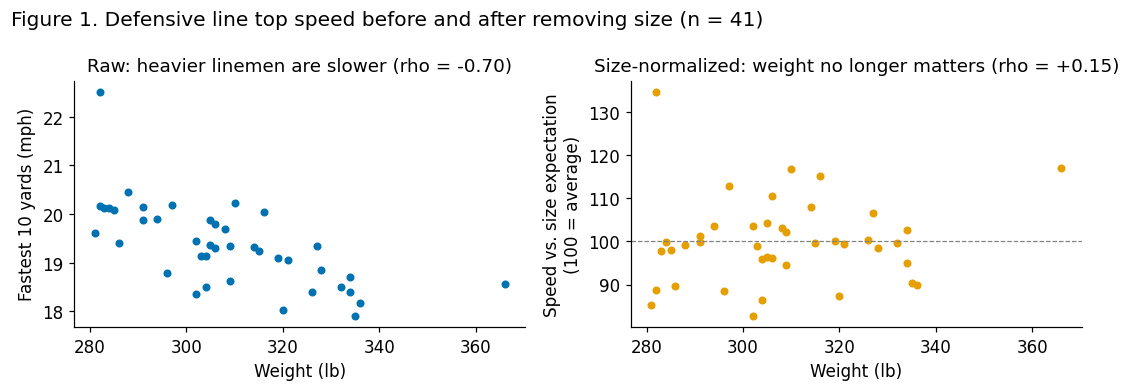

In [10]:
# Figure 1: why size normalization matters (defensive line)
CJ = T("combine_juice_scores.csv")
dd = CJ[(CJ.pgm == "DL") & CJ.fly10.notna() & CJ.T_trk_plus.notna()]
r_raw = spearmanr(dd.combine_weight, dd.fly10)[0]
r_adj = spearmanr(dd.combine_weight, dd.T_trk_plus)[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(dd.combine_weight, dd.fly10 * YD_TO_MPH, s=18, color=OI[0])
ax[0].set_title(f"Raw: heavier linemen are slower (rho = {r_raw:.2f})")
ax[0].set_xlabel("Weight (lb)"); ax[0].set_ylabel("Fastest 10 yards (mph)")
ax[1].scatter(dd.combine_weight, dd.T_trk_plus, s=18, color=OI[1])
ax[1].axhline(100, color="grey", lw=0.8, ls="--")
ax[1].set_title(f"Size-normalized: weight no longer matters (rho = {r_adj:+.2f})")
ax[1].set_xlabel("Weight (lb)"); ax[1].set_ylabel("Speed vs. size expectation\n(100 = average)")
fig.suptitle(f"Figure 1. Defensive line top speed before and after removing size (n = {len(dd)})", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 3. Seeing juice translate

**Game Juice+** rebuilds the same pieces from every 2023 to 2025 regular-season snap:
- **Like is compared with like.** Each play is compared only with plays at the same position, alignment, route and length. Very short snaps and snaps in decided games are dropped.
- **Best efforts count.** Each piece uses a player's 95th-percentile play, so loafing snaps don't drag him down.
- **Burst starts from his spot, not the snap.** Timing yards 2 to 10 from where he stood keeps reaction time out, just like the 40.
- **A player needs 50 usable plays.** The pieces are weighted by how well they repeat. 320 players qualify.

Game movement is a stable trait: split a player's plays in half at random and the halves agree at 0.94 (top speed), 0.89 (agility) and 0.81 (burst).

Figure 2 shows what translation looks like. **Malik Heath** (WR, undrafted, 2023) ran a 4.64 40, in the bottom 5% of receivers. His overall Combine Juice+ was 91, so a 40-first board passes on him. But his drill agility was 119, among the best of any receiver, and in 229 NFL plays his game agility came in above average at 106. Left: his sharpest route drill. Right: his sharpest cut on an NFL route. Bottom: both speed traces on one clock.

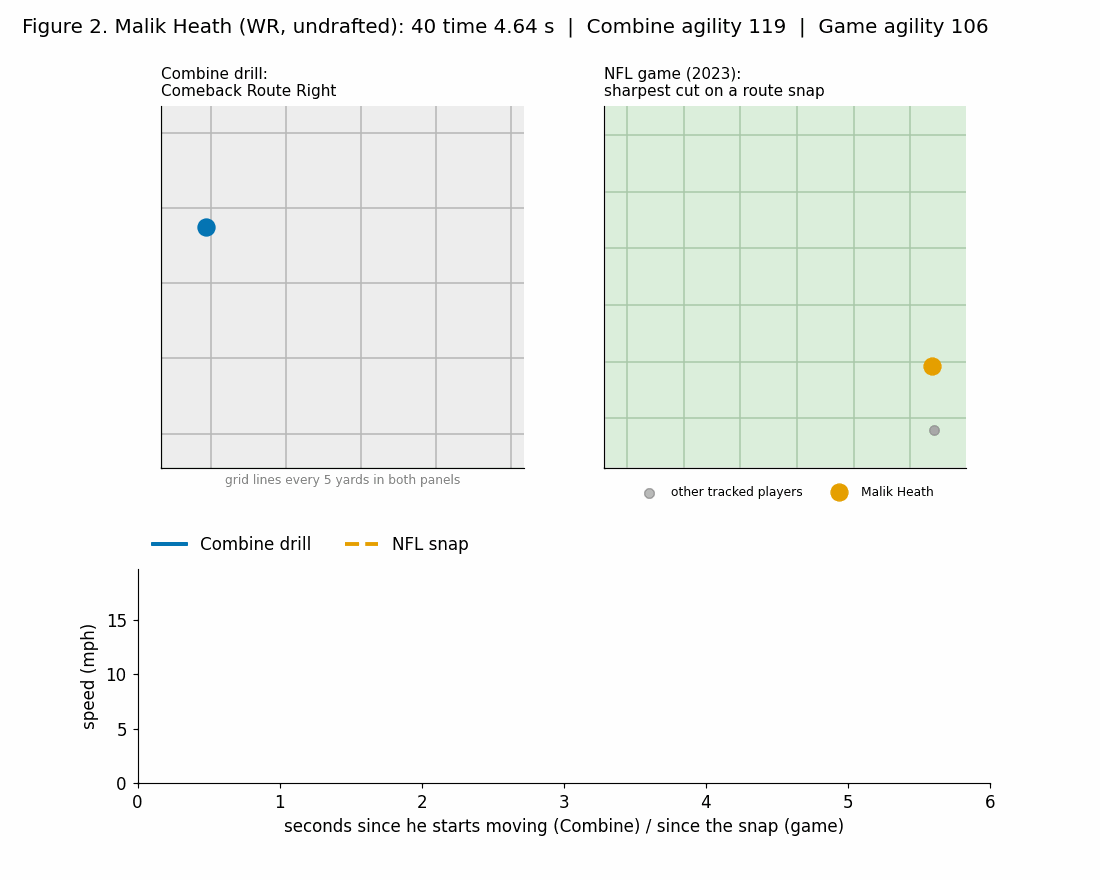

In [11]:
# Figure 2: one player in a position drill at the Combine and on a matching NFL snap.
# Rule (no hand-picking): the late-round (pick 140+ or undrafted) WR or DB with 100+ usable plays and the highest
# tracked Combine agility.
GJ = T("game_juice_scores.csv")
card = CJ.merge(GJ[["nfl_id", "game_juice", "g_agil_plus", "npl"]], on="nfl_id")
card["pick"] = card.draft_overall_pick.fillna(260)
row = (card[(card.pick >= 140) & card.pgm.isin(["WR", "DB"]) & (card.npl >= 100) & card.A_trk_plus.notna()]
       .sort_values("A_trk_plus", ascending=False).iloc[0])
pid, pname, ppos, pg = int(row.nfl_id), row.display_name, row.nfl_position, row.pgm
pick_txt = "undrafted" if row.pick >= 260 else f"pick {int(row.pick)}"
CACHE.mkdir(parents=True, exist_ok=True)
gif_path = CACHE / f"fig2_drill_vs_game_{pid}.gif"

if not gif_path.exists():
    # Combine: his position drill with the hardest braking and cutting (95th-percentile acceleration)
    cols = ["nfl_id", "entity_type", "event_id", "drill_name", "time", "x", "y", "s", "a"]
    ct = pd.concat(ch[ch.nfl_id == pid] for ch in pd.read_csv(get_file("combine_tracking.csv"), usecols=cols,
                                                              chunksize=1_000_000))
    ct = ct[ct.entity_type == "PLAYER"].copy()
    ct["time"] = pd.to_datetime(ct.time)
    ct = ct.sort_values(["event_id", "time"])
    ct["t"] = (ct.time - ct.groupby("event_id").time.transform("min")).dt.total_seconds()
    word = {"WR": "ROUTE", "DB": "BACK_PEDAL"}[pg]
    drills = ct[ct.drill_name.astype(str).str.contains(word)]
    if drills.empty:
        drills = ct[ct.drill_name != "FORTY_YARD_DASH"]

    def acc95(e):
        mv = e[e.s >= 1.0]
        return np.nanpercentile(mv.a, 95) if len(mv) >= 10 else np.nan

    ev = drills.groupby("event_id").apply(acc95).idxmax()
    cf = ct[ct.event_id == ev].sort_values("t")
    dname = str(cf.drill_name.iloc[0])
    on = np.where(cf.s.values >= 1.0)[0]
    cf = cf.iloc[max(on[0] - 3, 0):] if len(on) else cf
    cf = cf[cf.t - cf.t.iloc[0] <= 6.0]                  # the drill itself, not the jog out afterwards
    cx, cy = cf.x.values, cf.y.values
    cs, ctt = cf.s.values * YD_TO_MPH, cf.t.values - cf.t.values[0]

    # Game: his sharpest context-adjusted cuts in his role (the same route as the drill when possible)
    plm = T("play_level_movement.csv")
    mine = plm[(plm.nfl_id == pid) & plm.role.astype(bool) & plm.alat_c.notna()]
    if pg == "WR":
        same = mine[mine.route.astype(str).apply(lambda r: r not in ("NO_ROUTE", "nan") and r in dname.split("_"))]
        mine = same if len(same) >= 3 else mine[mine.route.astype(str) != "NO_ROUTE"]
    cands = mine.nlargest(5, "alat_c")[["game_id", "play_id", "season"]].astype(int)
    hits = []
    for seas_ in cands.season.unique():
        for chunk in pd.read_csv(get_file(f"game_tracking_{seas_}.csv"), chunksize=2_000_000,
                                 usecols=["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "event"]):
            h = chunk[chunk.game_id.isin(cands.game_id)]
            if len(h):
                hits.append(h.merge(cands[["game_id", "play_id"]], on=["game_id", "play_id"]))
    gp_all = pd.concat(hits, ignore_index=True)
    gp_all["time"] = pd.to_datetime(gp_all.time)
    me = pd.DataFrame()
    for _, cand in cands.iterrows():
        gp = gp_all[(gp_all.game_id == cand.game_id) & (gp_all.play_id == cand.play_id)].copy()
        snap_t = gp.loc[gp.event == "ball_snap", "time"].min()
        if pd.isna(snap_t):
            continue
        gp["t"] = (gp.time - snap_t).dt.total_seconds().round(1)
        gp = gp[(gp.t >= 0) & (gp.t <= 6)].sort_values("t")
        me = gp[gp.nfl_id == pid].drop_duplicates("t")
        if len(me) >= 10:
            seas = int(cand.season)
            break
    others = {t: d for t, d in gp[gp.nfl_id != pid].groupby("t")}
    gx, gy, gs, gtt = me.x.values, me.y.values, me.s.values * YD_TO_MPH, me.t.values

    def field(ax, xs, ys, face, line):
        pad = 3
        xc, yc = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
        half = max(xs.max() - xs.min(), ys.max() - ys.min()) / 2 + pad
        ax.set_xlim(xc - half, xc + half); ax.set_ylim(yc - half, yc + half); ax.set_aspect("equal")
        ax.set_facecolor(face); ax.set_xticks([]); ax.set_yticks([])
        for v in range(int(np.floor((xc - half) / 5) * 5), int(xc + half) + 1, 5):
            ax.axvline(v, color=line, lw=1.0, zorder=0)
        for v in range(int(np.floor((yc - half) / 5) * 5), int(yc + half) + 1, 5):
            ax.axhline(v, color=line, lw=1.0, zorder=0)

    fig = plt.figure(figsize=(10, 8))
    gsp = fig.add_gridspec(2, 2, height_ratios=[2.2, 1.3], hspace=0.35, wspace=0.08)
    axc, axg, axs = fig.add_subplot(gsp[0, 0]), fig.add_subplot(gsp[0, 1]), fig.add_subplot(gsp[1, :])
    fig.suptitle(f"Figure 2. {pname} ({ppos}, {pick_txt}): 40 time {row.forty:.2f} s  |  "
                 f"Combine agility {row.A_trk_plus:.0f}  |  Game agility {row.g_agil_plus:.0f}",
                 x=0.02, ha="left", fontsize=13)
    field(axc, cx, cy, "#eeeeee", "#b5b5b5")
    axc.set_title("Combine drill:\n" + dname.replace("_", " ").title(), loc="left", fontsize=10)
    field(axg, gx, gy, "#dcefdc", "#a9c9a9")
    axg.set_title(f"NFL game ({seas}):\nsharpest cut on a {'route' if pg == 'WR' else 'coverage'} snap",
                  loc="left", fontsize=10)
    c_trail, = axc.plot([], [], color=OI[0], lw=2.2)
    c_dot, = axc.plot([], [], "o", color=OI[0], ms=11)
    o_dots = axg.scatter([], [], s=40, color="grey", alpha=0.6, label="other tracked players")
    g_trail, = axg.plot([], [], color=OI[1], lw=2.2)
    g_dot, = axg.plot([], [], "o", color=OI[1], ms=11, label=pname)
    axg.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=8, frameon=False)
    axc.set_xlabel("grid lines every 5 yards in both panels", fontsize=8, color="grey")
    tmax = max(ctt.max(), gtt.max())
    axs.set_xlim(0, tmax); axs.set_ylim(0, max(cs.max(), gs.max()) * 1.15)
    axs.set_xlabel("seconds since he starts moving (Combine) / since the snap (game)")
    axs.set_ylabel("speed (mph)")
    c_line, = axs.plot([], [], color=OI[0], lw=2.5, label="Combine drill")
    g_line, = axs.plot([], [], color=OI[1], lw=2.5, ls="--", label="NFL snap")
    axs.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)

    n_frames = int(round(tmax * 10)) + 15          # hold the last frame for 1.5 s

    def frame(i):
        ic, ig = min(i, len(cx) - 1), min(i, len(gx) - 1)
        c_trail.set_data(cx[:ic + 1], cy[:ic + 1]); c_dot.set_data([cx[ic]], [cy[ic]])
        g_trail.set_data(gx[:ig + 1], gy[:ig + 1]); g_dot.set_data([gx[ig]], [gy[ig]])
        od = others.get(gtt[ig])
        o_dots.set_offsets(od[["x", "y"]].values if od is not None else np.empty((0, 2)))
        c_line.set_data(ctt[:ic + 1], cs[:ic + 1]); g_line.set_data(gtt[:ig + 1], gs[:ig + 1])
        return c_trail, c_dot, g_trail, g_dot, o_dots, c_line, g_line

    anim = animation.FuncAnimation(fig, frame, frames=n_frames, interval=100, blit=True)
    anim.save(gif_path, writer=animation.PillowWriter(fps=10))
    plt.close(fig)

display(Image(filename=str(gif_path)))

## 4. Does Combine juice show up in games?

**Yes.** Across the 270 players with both scores, the rank correlation between Combine and Game Juice+ is **0.28** (95% interval 0.17 to 0.39). A formula built without each player's own draft class gives the same answer (0.27). It holds for part-timers (50 to 199 plays: 0.26) and starters (600+: 0.21). It is strongest for defensive backs (0.41), edge rushers (0.35), tight ends (0.53, only 20 players) and receivers (0.28), and weakest for the lines (OL 0.12, interior DL 0.10), where games rarely ask big men to run in space.

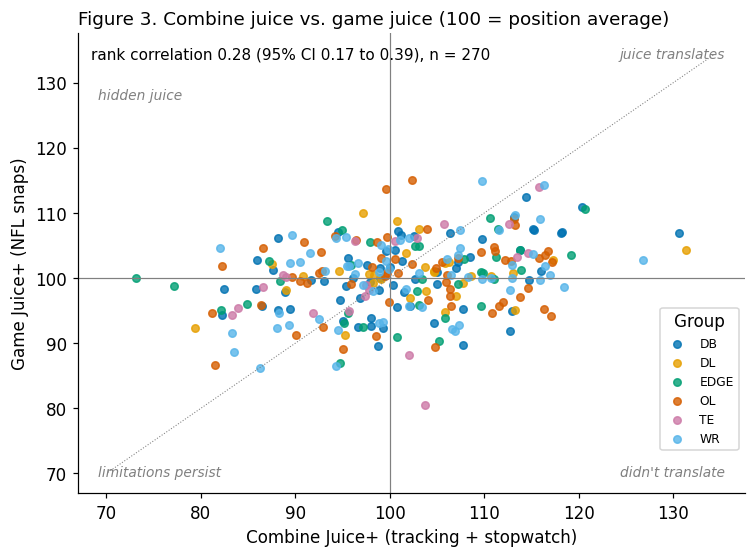

In [12]:
# Figure 3: Combine Juice+ vs Game Juice+
J = T("juice_player_table.csv")
BP = T("by_position_group.csv").set_index("group")
fig, ax = plt.subplots(figsize=(7, 5.2))
for g, d in J.groupby("pgm"):
    ax.scatter(d.juice_final, d.game_juice, s=24, alpha=0.8, color=GROUP_COL[g], label=g)
ax.axhline(100, color="grey", lw=0.8); ax.axvline(100, color="grey", lw=0.8)
lo, hi = min(J.juice_final.min(), J.game_juice.min()) - 3, max(J.juice_final.max(), J.game_juice.max()) + 3
ax.plot([lo, hi], [lo, hi], color="grey", lw=0.7, ls=":")
a = BP.loc["ALL"]
ax.text(0.02, 0.97, f"rank correlation {a['corr']:.2f} (95% CI {a['ci_low']:.2f} to {a['ci_high']:.2f}), n = {int(a['n'])}",
        transform=ax.transAxes, va="top", fontsize=10)
for txt, (xx, yy) in {"juice translates": (0.97, 0.97), "hidden juice": (0.03, 0.88),
                      "didn't translate": (0.97, 0.03), "limitations persist": (0.03, 0.03)}.items():
    ax.text(xx, yy, txt, transform=ax.transAxes, ha="right" if xx > 0.5 else "left",
            va="top" if yy > 0.5 else "bottom", color="grey", fontsize=9, style="italic")
ax.set_xlabel("Combine Juice+ (tracking + stopwatch)"); ax.set_ylabel("Game Juice+ (NFL snaps)")
ax.set_title("Figure 3. Combine juice vs. game juice (100 = position average)", loc="left")
ax.legend(title="Group", fontsize=8, loc="lower right", bbox_to_anchor=(1, 0.08))
plt.tight_layout(); plt.show()

The more useful view for a draft room is by tier (Figure 4):
- **Red flag:** only 1 of 39 players under 90 became an elite mover in games (top 16% at his position).
- **Green flag:** 20 of 61 players at 110+ did (33%), more than double the 15% in the middle tier.
- **Reaching the field:** 88% of players at 110+ logged 50 usable NFL plays, against 57% of players under 90.

Inside the 90 to 110 tier, the score barely orders players (0.07). So read Juice+ as three tiers, not a ranking.

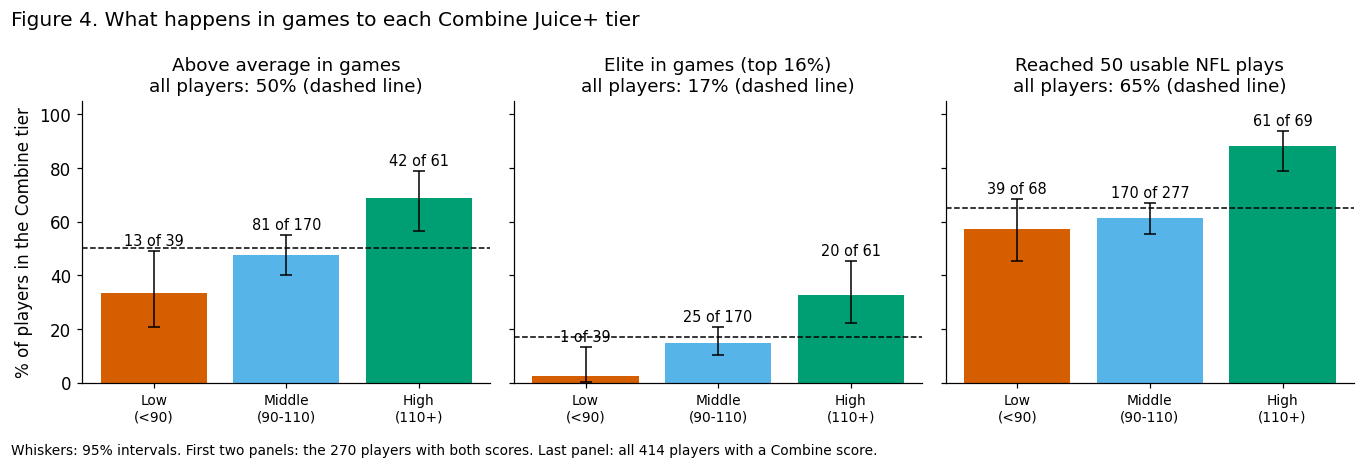

In [13]:
# Figure 4: what happens in games to each Combine Juice+ tier
TI, RF = T("tiers.csv"), T("reached_field.csv")
LAB = ["Low\n(<90)", "Middle\n(90-110)", "High\n(110+)"]
cols = [OI[3], OI[5], OI[2]]
panels = [("Above average in games", TI.above_avg, TI.n),
          ("Elite in games (top 16%)", TI.elite_in_games, TI.n),
          ("Reached 50 usable NFL plays", RF.scored_50plus, RF.n)]
fig, ax = plt.subplots(1, 3, figsize=(12.5, 4), sharey=True)
for a_, (lab, k, n) in zip(ax, panels):
    k, n = k.to_numpy(), n.to_numpy()
    p_ = 100 * k / n
    ci = np.array([wilson(ki, ni) for ki, ni in zip(k, n)]) * 100
    a_.bar(range(3), p_, color=cols)
    a_.errorbar(range(3), p_, yerr=[p_ - ci[:, 0], ci[:, 1] - p_], fmt="none", ecolor="black", elinewidth=1, capsize=4)
    base = 100 * k.sum() / n.sum()
    a_.axhline(base, color="black", ls="--", lw=1)
    for i in range(3):
        a_.text(i, ci[i, 1] + 2, f"{k[i]} of {n[i]}", ha="center", fontsize=9.5)
    a_.set_xticks(range(3)); a_.set_xticklabels(LAB, fontsize=9)
    a_.set_title(f"{lab}\nall players: {base:.0f}% (dashed line)")
ax[0].set_ylabel("% of players in the Combine tier")
ax[0].set_ylim(0, 105)
fig.text(0.01, -0.03, "Whiskers: 95% intervals. First two panels: the 270 players with both scores. "
         "Last panel: all 414 players with a Combine score.", fontsize=9)
fig.suptitle("Figure 4. What happens in games to each Combine Juice+ tier", x=0.01, ha="left")
plt.tight_layout(); plt.show()

**Which piece carries beyond the 40?** Figure 5 asks each Combine number to predict each game trait for receivers and defensive backs, with the 40 held fixed. A number that only repeats the stopwatch goes blank. Drill agility lights up its own trait: **+0.33** (0.15 to 0.49). Tracked speed adds a little to game top speed (+0.20). Burst adds nothing yet. The 40 itself predicts game top speed (+0.32) but not game agility. The stopwatch can't see change of direction.

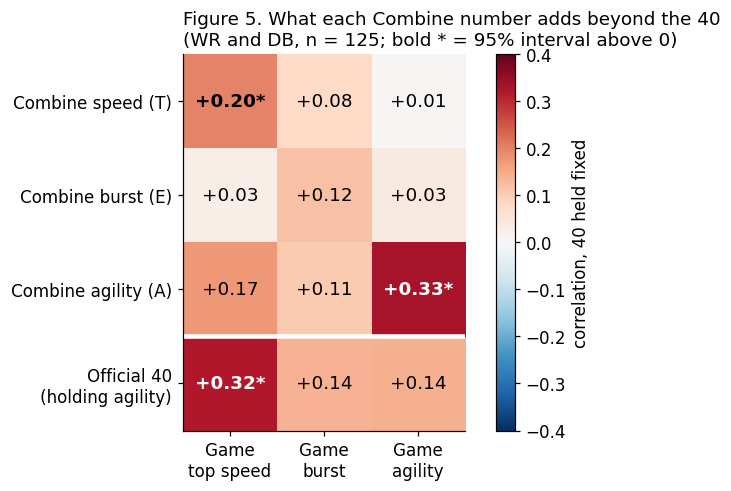

In [14]:
# Figure 5: Combine number vs game trait, WR + DB, holding the 40 fixed (the 40 row holds Combine agility instead)
SP = T("agility_specificity.csv")
SP = SP[SP.group == "WR + DB"]
rows_lab = ["Combine speed", "Combine burst", "Combine agility", "Official 40"]
cols_lab = ["game top speed", "game burst", "game agility"]
cm, ok = np.full((4, 3), np.nan), np.zeros((4, 3), bool)
for i, rl in enumerate(rows_lab):
    for j, cl in enumerate(cols_lab):
        r_ = SP[(SP["combine"] == rl) & (SP.game_trait == cl)].iloc[0]
        cm[i, j], ok[i, j] = r_.r, r_.lo > 0
fig, ax = plt.subplots(figsize=(6.6, 4.6))
im = ax.imshow(cm, vmin=-0.4, vmax=0.4, cmap="RdBu_r")
ax.set_xticks(range(3)); ax.set_xticklabels(["Game\ntop speed", "Game\nburst", "Game\nagility"])
ax.set_yticks(range(4)); ax.set_yticklabels(["Combine speed (T)", "Combine burst (E)", "Combine agility (A)",
                                             "Official 40\n(holding agility)"])
for i in range(4):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:+.2f}" + ("*" if ok[i, j] else ""), ha="center", va="center", fontsize=12,
                fontweight="bold" if ok[i, j] else "normal", color="white" if abs(cm[i, j]) > 0.25 else "black")
ax.axhline(2.5, color="white", lw=3)
plt.colorbar(im, ax=ax, fraction=0.046, label="correlation, 40 held fixed")
ax.set_title(f"Figure 5. What each Combine number adds beyond the 40\n(WR and DB, n = {int(SP.n.iloc[0])}; "
             "bold * = 95% interval above 0)", loc="left")
plt.tight_layout(); plt.show()

## 5. Juice+ vs. the stopwatch

On the same 249 players, Combine Juice+ ranks game movement at **0.27**. The NGS Athleticism Score reaches 0.16 and a RAS-style score 0.14 (Figure 6). Both gaps are clear (+0.11 and +0.13, with intervals above 0).

The 40 is the real benchmark. The plain 40 reaches 0.24. Take body size out of it and it reaches 0.29, level with Juice+. For straight-line speed, nothing beats a stopwatch. Juice+'s value is the part a stopwatch can't time:

- **Agility beyond the 40.** For WR and DB, drill agility predicts game agility with the 40 held fixed at **+0.33** (n = 125). It stays at +0.33 to +0.35 when RAS-style, draft pick, play count or body size are also held fixed. Shuffling agility scores within each position never comes close (p < 0.001). Across all groups with agility, it adds +0.17 (0.05 to 0.30) to overall Game Juice+.
- **It isn't who got on the field.** WR and DB who never reached 50 plays had the same Combine agility as those who did (49th vs. 51st percentile).
- **It predicts growth.** Holding a player's rookie game agility fixed, his Combine agility still predicts his year-2 game agility: **+0.34** (0.12 to 0.54, n = 63). The 40 in the same model: **+0.01**. The 16 WR and DB whose drill agility ran a full standard deviation (SD) ahead of their rookie play gained 0.71 SD the next year. Everyone else slipped 0.48 SD.

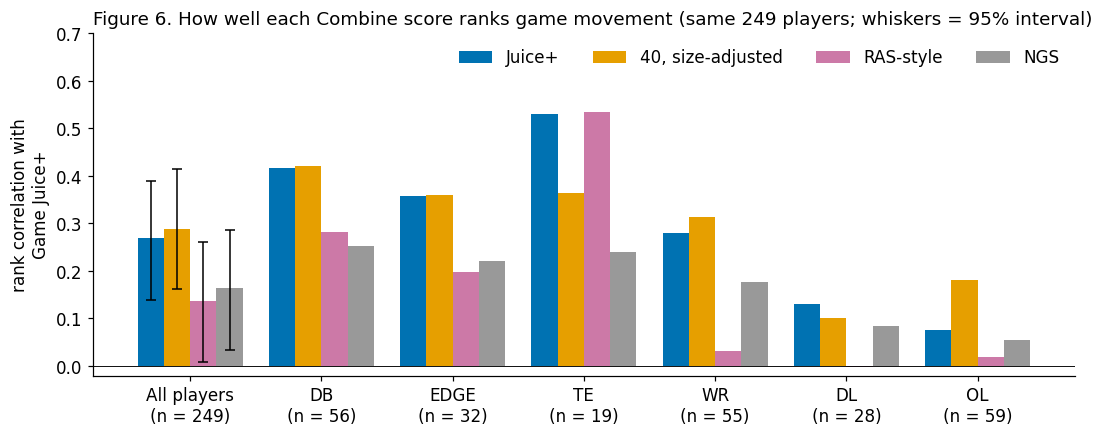

In [15]:
# Figure 6: how well each Combine score ranks game movement, same players
CO = T("carry_over.csv").set_index("score")
SCORES = [("Juice+", "juice_final", "Juice+", OI[0]),
          ("Official 40, size-adjusted", "forty_adj", "40, size-adjusted", OI[1]),
          ("RAS-style", "ras_style", "RAS-style", OI[4]),
          ("NGS athleticism", "ngs_athleticism_score", "NGS", "#999999")]
V = J.dropna(subset=["ngs_athleticism_score", "ras_style", "forty_adj", "forty_neg", "ngs_adj", "ras_adj"])
order = ["ALL", "DB", "EDGE", "TE", "WR", "DL", "OL"]
fig, ax = plt.subplots(figsize=(10, 4.1))
xs, wbar = np.arange(len(order)), 0.2
for k, (co_name, col, lab, colr) in enumerate(SCORES):
    vals = [CO.loc[co_name, "corr_with_game_juice"]] + [spearmanr(d[col], d.game_juice)[0]
                                                         for g in order[1:] for d in [V[V.pgm == g]]]
    off = (k - 1.5) * wbar
    ax.bar(xs + off, vals, wbar, color=colr, label=lab)
    ax.errorbar(off, CO.loc[co_name, "corr_with_game_juice"],
                yerr=[[CO.loc[co_name, "corr_with_game_juice"] - CO.loc[co_name, "ci_low"]],
                      [CO.loc[co_name, "ci_high"] - CO.loc[co_name, "corr_with_game_juice"]]],
                fmt="none", ecolor="black", elinewidth=1, capsize=3)
ax.axhline(0, color="black", lw=0.6)
n_g = V.pgm.value_counts()
ax.set_xticks(xs); ax.set_xticklabels([f"All players\n(n = {len(V)})"] + [f"{g}\n(n = {n_g[g]})" for g in order[1:]])
ax.set_ylabel("rank correlation with\nGame Juice+")
ax.set_ylim(-0.02, 0.7)
ax.legend(frameon=False, ncol=4, loc="upper right")
ax.set_title(f"Figure 6. How well each Combine score ranks game movement (same {len(V)} players; "
             "whiskers = 95% interval)", loc="left")
plt.tight_layout(); plt.show()

## 6. Using Juice+ to add juice to a roster

Teams already pay for juice somewhat (first-round picks average 107, undrafted players 94), but the draft prices the whole player and leaves athletes on the board. A team can use Juice+ three ways:

1. **Draft-board filter.** Flag prospects at 110+ and red-flag those under 90. Juice+ says who has the gear. Scouts decide whether he can play. Late-round players at 110+ finished in the top half of game movement 4 of 7 times (other late picks: 37%), including Eric Watts (DE), Will Mallory (TE) and Marques Sigle (SS).
2. **The agility flag for WR and DB.** A receiver or corner whose drill agility is far ahead of his 40 is the prospect a stopwatch board misses, like Heath. Use it to sort a tier, not to call one player: in matched pairs with the same 40, the more agile player moved better in games only 53% of the time.
3. **Week to week, and year to year.** For top speed, a rookie's first 10 plays already beat his Combine, but the Combine keeps adding (+0.07 R² even after 100 plays). For agility, game film wins right away. So in season, trust the film for agility. Across seasons, trust the Combine: a rookie whose drill agility outran his game agility is a candidate to grow in year 2 (Table 1).

In [16]:
# Table 1: WR and DB whose Combine agility was 1+ SD ahead of their rookie game agility, and what year 2 showed
cw = report("casework_report.txt")
sec = cw.split("C3. Unused agility")[1].split("C4.")[0]
pat = re.compile(r"^\s+(.+?)\s{2,}(\w+)\s+(\d{4}) pick\s+(\S+)\s+year-1 ([+-][\d.]+) -> year-2 ([+-][\d.]+) SD "
                 r"\(Combine ([+-][\d.]+)\)", re.M)
U = pd.DataFrame(pat.findall(sec), columns=["Player", "Pos", "Class", "Pick", "y1", "y2", "comb"])
for c in ["y1", "y2", "comb"]:
    U[c] = U[c].astype(float)
U["Pick"] = U.Pick.replace({"UDFA": "undrafted"})
tbl = pd.DataFrame({"Player": U.Player, "Pos": U.Pos, "Class": U.Class, "Pick": U.Pick,
                    "Combine agility": U.comb, "Rookie game agility": U.y1, "Year-2 game agility": U.y2,
                    "Change": U.y2 - U.y1})
print("Table 1. Unused agility: WR and DB whose Combine agility ran 1+ SD ahead of their rookie game agility "
      "(all values in SD within position)")
fmt = {c: "{:+.2f}" for c in ["Combine agility", "Rookie game agility", "Year-2 game agility", "Change"]}
try:
    display(tbl.style.hide(axis="index").format(fmt)
            .bar(subset=["Change"], align="zero", color=[OI[3], OI[0]], vmin=-2, vmax=2))
except Exception:
    display(tbl.round(2).reset_index(drop=True))

Table 1. Unused agility: WR and DB whose Combine agility ran 1+ SD ahead of their rookie game agility (all values in SD within position)


Player,Pos,Class,Pick,Combine agility,Rookie game agility,Year-2 game agility,Change
Kei'Trel Clark,CB,2023,180,+0.61,-1.11,+0.73,+1.84
Trey Palmer,WR,2023,191,+0.03,-1.24,+0.49,+1.73
Xavier Legette,WR,2024,32,+0.67,-1.68,+0.02,+1.70
Rome Odunze,WR,2024,9,+1.03,-0.44,+0.94,+1.38
Keon Coleman,WR,2024,33,-0.68,-2.33,-0.99,+1.34
Troy Franklin,WR,2024,102,-0.00,-1.02,+0.21,+1.23
Quan Martin,FS,2023,47,+1.71,+0.51,+1.45,+0.94
Jonathan Mingo,WR,2023,39,+0.56,-0.78,+0.12,+0.90
Ricky Pearsall,WR,2024,31,+1.86,+0.69,+1.10,+0.41
Tykee Smith,SS,2024,89,+0.75,-1.38,-1.06,+0.32


**Does juice show up in results?** A little, and the stars had it. Of the 9 All-Pro or Pro Bowl players with a Combine score, 8 were above 100 (all scored players: 50%). Moving well also buys a receiver separation, and each yard of separation at the throw is worth +0.083 EPA per target. Figure 7 follows the chain for WRs: the Combine predicts game movement, and game movement predicts separation. End to end, one SD at the Combine is worth about 0.03 yards of separation, or 0.2 to 0.3 EPA per 100 targets. Real, but small.

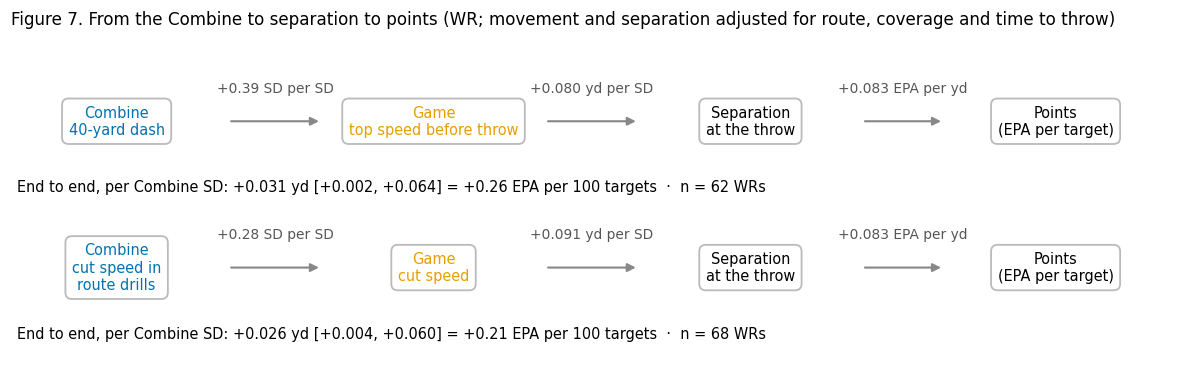

In [17]:
# Figure 7: the WR chain in yards and points (Combine -> game movement -> separation -> EPA)
RC = T("route_chain.csv")
RV = T("separation_value.csv").set_index("outcome")
rows_ = RC[RC.preregistered.astype(bool)].reset_index(drop=True)
epa_yd = RV.loc["EPA per target", "per_yard"]
NAMES = {"40-yard dash": "40-yard dash", "Combine drill cut speed": "cut speed in\nroute drills"}
fig, ax = plt.subplots(figsize=(11, 0.6 + 1.5 * len(rows_)))
ax.set_xlim(0, 10); ax.set_ylim(-0.7, len(rows_) - 0.4); ax.axis("off")
box = dict(boxstyle="round,pad=0.45", fc="white", ec="#bbbbbb", lw=1.2)
xs_ = [0.9, 3.6, 6.3, 8.9]
for i, r in rows_.iterrows():
    y = len(rows_) - 1 - i
    labels = [f"Combine\n{NAMES.get(r.combine_piece, r.combine_piece)}", f"Game\n{r.game_piece}",
              "Separation\nat the throw", "Points\n(EPA per target)"]
    for xx, lab, col in zip(xs_, labels, (OI[0], OI[1], "black", "black")):
        ax.text(xx, y, lab, ha="center", va="center", fontsize=9.5, color=col, bbox=box)
    arrows = [f"{r.a_sd_per_sd:+.2f} SD per SD", f"{r.b_yd_per_sd:+.3f} yd per SD", f"{epa_yd:+.3f} EPA per yd"]
    for k, lab in enumerate(arrows):
        ax.annotate("", xy=(xs_[k + 1] - 0.95, y), xytext=(xs_[k] + 0.95, y),
                    arrowprops=dict(arrowstyle="-|>", color="#888888", lw=1.4))
        ax.text((xs_[k] + xs_[k + 1]) / 2, y + 0.18, lab, ha="center", va="bottom", fontsize=9, color="#555555")
    ax.text(xs_[0] - 0.85, y - 0.45, f"End to end, per Combine SD: {r.ab_yd:+.3f} yd [{r.ab_lo:+.3f}, {r.ab_hi:+.3f}]"
            f" = {r.epa_per_100:+.2f} EPA per 100 targets  ·  n = {int(r.n)} WRs", ha="left", va="center",
            fontsize=9.5)
ax.set_title("Figure 7. From the Combine to separation to points (WR; movement and separation adjusted for route, "
             "coverage and time to throw)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## 7. Limits and next steps

- **Movement, not production.** Juice+ says how a player moves next to same-position, same-size peers. On results like separation, pressure and coverage EPA, no athleticism score (ours, NGS, RAS-style or the 40) predicts well once size is removed (all near +0.03 to +0.08).
- **Agility is strong but not settled.** For WR and DB it holds in the 2023 (+0.40) and 2024 (+0.35) classes, but the 2025 class alone is weaker (+0.15). Head to head with the 40 for game agility, agility leads, but not by a clear margin.
- **Small samples.** 20 to 64 players per position, so position-level intervals are wide.
- **Linemen.** OL and interior DL movement barely carries into games.
- **Scope.** Regular season only. Game tracking covers only this rookie group.

**Next:** score our 2026 receiver predictions, made before the season, once it ends.

*All numbers come from one run of the code on the competition data. Code cells are hidden. Expand any cell to see how a figure was made. The appendix recomputes every quoted number.*

In [18]:
# Appendix: every number quoted in the text, recomputed from this run's tables. A failed line means the text is stale.
cw, tr, ro = report("casework_report.txt"), report("transfer_report.txt"), report("routes_report.txt")
num = lambda pat, txt, g=1: float(re.search(pat, txt).group(g))
bv = T("burst_validity.csv").set_index("feature"); sd = T("size_dependence.csv").set_index("score")
CO = T("carry_over.csv").set_index("score"); ED = T("edges_vs_other_scores.csv").set_index("Juice+ minus")
ADD = T("tracking_adds.csv"); SPx = T("agility_specificity.csv")
spec = lambda comb, trait: SPx[(SPx.group == "WR + DB") & (SPx["combine"] == comb) & (SPx.game_trait == trait)].iloc[0]
agi = ADD[(ADD.piece.str.startswith("Agility")) & (ADD.group == "ALL") & (ADD.holding == "the 40")
          & (ADD.target == "Game Juice+")].iloc[0]
summ = json.loads((OUT / "transfer_summary.json").read_text())
TK = T("snap_takeover.csv"); TI_ = T("tiers.csv").set_index("tier"); RF_ = T("reached_field.csv").set_index("tier")
LR = T("late_round_agility.csv").set_index("display_name"); PR = T("agility_pairs.csv")
SFP = T("football_results_size_free_pooled.csv"); SFP = SFP[SFP["pool"] == "All blocks"]
heath = card.set_index("display_name").loc["Malik Heath"]
CJ["rd"] = CJ.draft_round.fillna(8)
cs_ = pd.read_csv(get_file("player_career_successes.csv"))
hon = cs_[(cs_.ap_all_pro_1st_team + cs_.ap_all_pro_2nd_team + cs_.pro_bowl_original_ballot) > 0]
hj = CJ[CJ.nfl_id.isin(hon.nfl_id)]
A2 = cw.split("A2.")[1].split("A3.")[0]
robust = [num(rf"{k}\s+([+-][\d.]+)", A2) for k in ["holding 40 \+ RAS-style ", "holding 40 \+ draft pick",
                                                       "holding 40 \+ log plays", "holding 40 \+ RAS \+ pick \+ plays",
                                                       "holding 40 \+ weight \+ height"]]
chain = T("route_chain.csv"); chain = chain[chain.preregistered.astype(bool)]
checks = {
    "tracked players 505": (C_["combine_tracked"], 505), "Combine scored 414": (C_["combine_scored"], 414),
    "game scored 320": (C_["game_scored"], 320), "both 270": (C_["both"], 270), "same players 249": (C_["head_to_head"], 249),
    "top speed retest 0.91": (bv.loc["fly10", "retest"], 0.91), "burst retest 0.67": (RUN["reliability"]["combine_retest"]["E_comp"], 0.67),
    "top speed vs 40 0.89": (bv.loc["fly10", "vs_forty"], 0.89),
    "DL weight vs raw speed -0.70": (r_raw, -0.70), "DL weight vs adjusted +0.15": (r_adj, 0.15),
    "Juice+ vs weight -0.03": (sd.loc["Juice+", "corr_with_weight"], -0.03),
    "40 vs weight -0.34": (sd.loc["Official 40", "corr_with_weight"], -0.34),
    "RAS vs weight -0.29": (sd.loc["RAS-style", "corr_with_weight"], -0.29),
    "game split-half top 0.94": (RUN["reliability"]["game_split_half"]["top"], 0.94),
    "game split-half agility 0.89": (RUN["reliability"]["game_split_half"]["agil"], 0.89),
    "game split-half burst 0.81": (RUN["reliability"]["game_split_half"]["expl"], 0.81),
    "Heath 40 4.64": (heath.forty, 4.64), "Heath 40 bottom 5%": (LR.loc["Malik Heath", "pct_neg_forty"] < 0.05, True),
    "Heath Juice+ 91": (heath.juice_final, 91), "Heath agility 119": (heath.A_trk_plus, 119),
    "Heath game agility 106": (heath.g_agil_plus, 106), "Heath plays 229": (heath.npl, 229),
    "carry 0.28": (BP.loc["ALL", "corr"], 0.28), "carry low 0.17": (BP.loc["ALL", "ci_low"], 0.17),
    "carry high 0.39": (BP.loc["ALL", "ci_high"], 0.39),
    "held-out formula 0.27": (CO.loc["Juice+ (held-out formula)", "corr_with_game_juice"], 0.27),
    "50-199 plays 0.26": (num(r"50-199\s+n=\s*\d+\s+([+-][\d.]+)", tr), 0.26),
    "600+ plays 0.21": (num(r"600\+\s+n=\s*\d+\s+([+-][\d.]+)", tr), 0.21),
    "DB 0.41": (BP.loc["DB", "corr"], 0.41), "EDGE 0.35": (BP.loc["EDGE", "corr"], 0.35),
    "TE 0.53": (BP.loc["TE", "corr"], 0.53), "TE n 20": (BP.loc["TE", "n"], 20), "WR 0.28": (BP.loc["WR", "corr"], 0.28),
    "OL 0.12": (BP.loc["OL", "corr"], 0.12), "DL 0.10": (BP.loc["DL", "corr"], 0.10),
    "under 90 elite 1 of 39": ((TI_.loc["<90", "elite_in_games"], TI_.loc["<90", "n"]) == (1, 39), True),
    "110+ elite 20 of 61": ((TI_.loc["110+", "elite_in_games"], TI_.loc["110+", "n"]) == (20, 61), True),
    "middle elite 15%": (TI_.loc["90-110", "elite_share"], 0.15),
    "reached 110+ 88%": (RF_.loc["110+", "share_scored"], 0.88), "reached <90 57%": (RF_.loc["<90", "share_scored"], 0.57),
    "inside 90-110 0.07": (summ["smaller_checks"]["tiers_inside_90_110"], 0.07),
    "agility beyond 40 +0.33": (spec("Combine agility", "game agility").r, 0.33),
    "agility low 0.15": (spec("Combine agility", "game agility").lo, 0.15),
    "agility high 0.49": (spec("Combine agility", "game agility").hi, 0.49),
    "agility n 125": (spec("Combine agility", "game agility").n, 125),
    "speed -> top +0.20": (spec("Combine speed", "game top speed").r, 0.20),
    "burst adds nothing (interval crosses 0)": (spec("Combine burst", "game burst").lo < 0, True),
    "40 -> top +0.32": (spec("Official 40", "game top speed").r, 0.32),
    "40 -> agility not clear": (spec("Official 40", "game agility").lo < 0, True),
    "Juice+ 0.27": (CO.loc["Juice+", "corr_with_game_juice"], 0.27),
    "NGS 0.16": (CO.loc["NGS athleticism", "corr_with_game_juice"], 0.16),
    "RAS 0.14": (CO.loc["RAS-style", "corr_with_game_juice"], 0.14),
    "plain 40 0.24": (CO.loc["Official 40", "corr_with_game_juice"], 0.24),
    "size-adjusted 40 0.29": (CO.loc["Official 40, size-adjusted", "corr_with_game_juice"], 0.29),
    "edge NGS +0.11": (ED.loc["NGS athleticism", "edge"], 0.11), "edge NGS low 0.02": (ED.loc["NGS athleticism", "ci_low"], 0.02),
    "edge NGS high 0.20": (ED.loc["NGS athleticism", "ci_high"], 0.20),
    "edge RAS +0.13": (ED.loc["RAS-style", "edge"], 0.13), "edge RAS low 0.05": (ED.loc["RAS-style", "ci_low"], 0.05),
    "edge RAS high 0.23": (ED.loc["RAS-style", "ci_high"], 0.23),
    "robust min 0.33": (min(robust), 0.33), "robust max 0.35": (max(robust), 0.35),
    "permutation p < 0.001": (num(r"permutation p .*?: ([\d.]+)", cw) < 0.001, True),
    "pooled agility +0.17": (agi.partial_r, 0.17), "pooled low 0.05": (agi.ci_low, 0.05), "pooled high 0.30": (agi.ci_high, 0.30),
    "reached field agility 51st pct": (num(r"reached 50\+ plays\s+n=\s*\d+\s+mean Combine agility pct ([\d.]+)", cw), 0.51),
    "did not reach 49th pct": (num(r"did not\s+n=\s*\d+\s+mean Combine agility pct ([\d.]+)", cw), 0.49),
    "year 2 agility +0.34": (num(r"Combine agility ([+-][\d.]+) \[", cw), 0.34),
    "year 2 low 0.12": (num(r"Combine agility [+-][\d.]+ \[([+-][\d.]+),", cw), 0.12),
    "year 2 high 0.54": (num(r"Combine agility [+-][\d.]+ \[[+-][\d.]+, ([+-][\d.]+)\]", cw), 0.54),
    "year 2 the 40 +0.01": (num(r"the 40 ([+-][\d.]+) \[", cw), 0.01),
    "year 2 n 63": (num(r"year-1 \+ Combine agility \+ 40, n=(\d+)", cw), 63),
    "flagged 16": (num(r"year-1 game agility\): (\d+);", cw), 16),
    "flagged gain +0.71": (num(r"mean change year 1 -> 2: ([+-][\d.]+) SD", cw), 0.71),
    "others -0.48": (num(r"SD vs ([+-][\d.]+) for the rest", cw), -0.48),
    "round 1 mean 107": (CJ[CJ.rd == 1].juice_final.mean(), 107), "no pick mean 94": (CJ[CJ.rd == 8].juice_final.mean(), 94),
    "late 110+ 4 of 7": ((summ["smaller_checks"]["late_round"]["hi_above"], summ["smaller_checks"]["late_round"]["hi_n"]) == (4, 7), True),
    "late others 37%": (summ["smaller_checks"]["late_round"]["lo_above"] / summ["smaller_checks"]["late_round"]["lo_n"], 0.37),
    "late names": (all(n_ in tr for n_ in ["Eric Watts", "Will Mallory", "Marques Sigle"]), True),
    "pairs 53%": (PR.agile_wins_game.mean(), 0.53),
    "top speed takeover 10 plays": (summ["takeover_k"]["game top speed"], 10),
    "Combine adds at 100 plays +0.07": (TK[(TK.metric == "game top speed") & (TK.k == 100)].combine_adds.iloc[0], 0.07),
    "agility film wins at once": (summ["takeover_k"]["game agility"], 1),
    "honors with a score 9": (len(hj), 9), "honors above 100: 8": ((hj.juice_final > 100).sum(), 8),
    "all scored above 100: 50%": ((CJ.juice_final > 100).mean(), 0.50),
    "EPA per yard 0.083": (RV.loc["EPA per target", "per_yard"], 0.083),
    "chain yards ~0.03": (chain.ab_yd.round(2).tolist(), [0.03, 0.03]),
    "chain EPA 0.2 to 0.3": (bool(chain.epa_per_100.between(0.2, 0.3).all()), True),
    "size-free results 0.03 to 0.08": (bool(SFP[SFP.score.isin(["Juice+", "NGS", "RAS-style", "40"])].estimate
                                            .between(0.025, 0.085).all()), True),
    "class 2023 +0.40": (num(r"draft class 2023 only\s+([+-][\d.]+)", cw), 0.40),
    "class 2024 +0.35": (num(r"draft class 2024 only\s+([+-][\d.]+)", cw), 0.35),
    "class 2025 +0.15": (num(r"draft class 2025 only\s+([+-][\d.]+)", cw), 0.15),
    "agility vs 40 head to head not clear": (num(r"Agility minus the 40 .*?\[([+-][\d.]+),", cw) < 0, True),
    "per-position n 20 to 64": ((BP.drop("ALL").n.min(), BP.drop("ALL").n.max()) == (20, 64), True),
}


def close(v, want):
    if isinstance(want, (bool, list, tuple)):
        return v == want
    return abs(float(v) - want) <= (0.5 if abs(want) >= 2 else 0.006)


bad = {k: v for k, (v, want) in checks.items() if not close(v, want)}
print(f"{len(checks) - len(bad)} of {len(checks)} quoted numbers match run {RUN['run_id']}.")
if bad:
    print("Update the text for:", bad)

97 of 97 quoted numbers match run 20261107T020037Z-a2540c.
